# 09 — 2μ2e final decision: optimized loose boundary versus fixed-A buffer

The final comparison is **Loose A: isolation<0.25, |Δφ|≥2.6** versus **Buffer A: isolation<0.20, |Δφ|≥2.7**, with buffered B/D isolation≥0.25 and C/D |Δφ|<2.0. All plots use these definitions consistently in nominal MC and the VRs.

Loose selection maximizes the **absolute median known-background MC-A significance** among native-grid candidates with every nominal B/C/D S/B_MC<10%. The historical union of abandoned A candidates is no longer an eligibility condition. The former (0.30,2.4) choice is superseded.

Both final candidate A regions remain blind in nominal DATA. The buffered B/D edge of 0.25 permits a common nominal-control comparison without exposing the loose finalist's A. The pure minimum-gap alternative at 0.20 is identified separately in MC; it is not queried in nominal DATA. Binwise VR contamination masking is retained.

This notebook supports choosing one boundary approach. MC-A significance is an optimization diagnostic; an uncertainty-aware ABCD likelihood and final limits are separate statistical deliverables.


In [1]:
from pathlib import Path
import sys,json,hashlib
from datetime import datetime,timezone
SIDM_DIR=next((p for p in (Path.cwd(),*Path.cwd().parents) if p.name=='sidm'),None)
if SIDM_DIR is None:raise RuntimeError('Run inside the sidm repository.')
NOTEBOOK_DIR=SIDM_DIR/'studies'/'ABCD_finalize'
for folder in (SIDM_DIR.parent,NOTEBOOK_DIR):
    if str(folder) not in sys.path:sys.path.insert(0,str(folder))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
import abcd_finalize_common as common
from abcd_finalize_common import finalize_final_check_build_final_check_config as build_final_check_config
from abcd_finalize_common import finalize_iso_focus_build_iso_focus as build_iso_focus, finalize_iso_focus_attach_final_nominal_controls as attach_final_nominal_controls
from abcd_finalize_common import finalize_final_nominal_controls_evaluate_final_nominal_controls as evaluate_final_nominal_controls
from abcd_finalize_common import finalize_selected_vr_displays_run_selected_vr_displays as run_selected_vr_displays, finalize_selected_vr_displays_prepare_final_gap_vr as prepare_final_gap_vr
from abcd_finalize_plots import finalize_iso_buffer_plots_make_iso_buffer_figures as make_iso_buffer_figures, finalize_iso_buffer_plots_iso_buffer_figure_definitions as iso_buffer_figure_definitions
from abcd_finalize_plots import finalize_capped_gap_plots_capped_gap_figures as capped_gap_figures, finalize_capped_gap_plots_capped_gap_definitions as capped_gap_definitions
from abcd_finalize_plots import finalize_final_comparison_plots_make_final_comparison_figures as make_final_comparison_figures, finalize_final_comparison_plots_final_comparison_definitions as final_comparison_definitions, finalize_final_comparison_plots_final_comparison_tables as final_comparison_tables
from abcd_finalize_common import finalize_sideband_validation_MEASUREMENT_FIELDS as MEASUREMENT_FIELDS
get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'figure.dpi':100,'font.size':11,'figure.max_open_warning':0})
pd.set_option('display.float_format',lambda x:f'{x:.5g}')
CONFIG=build_final_check_config(NOTEBOOK_DIR)
CONFIG.update(fixed_candidates=False,main_candidate='WP2',study='finalists-only-optimized-boundary-comparison',
    focus_angles=[2.4,2.6,2.7,2.8],isolation_boundary_max=.5,requested_angle_range=[2.4,2.8],report_date='2026-10-27')
OUTPUT_DIR=Path(CONFIG['output_dir'])
REFERENCE_DIRS=[NOTEBOOK_DIR/name for name in ['09_20261026_reference','09_20261027_sideband_reference','09_20261027_iso_reference']]
reference_tables=[]
for directory in REFERENCE_DIRS:
    document=json.loads((directory/'archive_manifest.json').read_text())
    for relative,digest in document['files'].items():
        assert hashlib.sha256((directory/relative).read_bytes()).hexdigest()==digest,relative
    reference_tables.append({p.stem:pd.read_csv(p,float_precision='round_trip')
        for p in (directory/OUTPUT_DIR.name).glob('*.csv')})
    print('Verified reference inputs:',directory.name,len(document['files']))
historical,previous_tables,reference_scan=reference_tables
CONFIG.update(nominal_blinding_policy='finalists_only',historical_A_union_veto=False,
    final_loose=dict(a_iso=.25,a_phi=2.6),
    final_buffer=dict(candidate_id='G_i0p25_p2',strategy='gap',a_iso=.2,a_phi=2.7,b_iso=.25,c_phi=2.,
        display_label='Fixed WP2 A + buffer (0.25,2.0)'))

CONFIG['significance_display']='absolute median over 60 matching signal hypotheses'

from abcd_finalize_plots import finalize_data_expected_significance_data_expected_significance_tables as data_expected_significance_tables, finalize_data_expected_significance_data_expected_significance_figures as data_expected_significance_figures, finalize_data_expected_significance_data_expected_significance_definitions as data_expected_significance_definitions


Verified reference inputs: 09_20261026_reference 4
Verified reference inputs: 09_20261027_sideband_reference 2
Verified reference inputs: 09_20261027_iso_reference 13


## Selections, scan range and blinding

Nominal is **2μ2e DD, MJJ≥150 GeV**, with partner isolation in [0,0.5). Low mass is [0,150), intermediate is [150,300), and inclusive is MJJ≥0. Displacement categories are explicit PP/PD/DP; intermediate DD is excluded.

The ordinary scan uses native isolation boundaries **0.20,0.25,0.30,0.40,0.50** and angle boundaries **2.4,2.6,2.7,2.8**. Isolation=0.50 means A requires isolation<0.50. There is no native 2.5 angle edge. Buffer isolation edges are also capped at 0.5; φ_L=2.0 is a sideband edge and does not change the fixed A cut of 2.7.

1. **Final nominal A only:** historical candidate-A unions do not veto optimization or newly defined controls. The two finalists' A regions remain blind. The loose A contains the fixed-WP2 A, so protection is exactly isolation<0.25 and |Δφ|≥2.6. Selected nominal controls are checked against this definition before reading DATA. No nominal A yield or κ is evaluated.
2. **Integrated contamination:** all 120 separate hypotheses must satisfy direct regional S/B_MC<10% in nominal B/C/D, or every ABCD region of a displayed VR closure. Nonpositive/invalid MC background is unsupported. This is a central-value rule, not a confidence bound.
3. **VR measurements:** exact published measurements can be reused. Buffered regions may reuse their individual exact published rectangular integrals when the four disjoint regions pass the selected VR gate. New regional information must still not disclose a contamination-masked region by subtraction. This is separate from the removed historical nominal-A veto.
4. **2D DATA display:** each visible bin passes its own all-120 MC purity test. Existing safe bins and the previously audited inclusive-DP subset are reused. A partial 2D display never substitutes for a complete ABCD yield or closure.

κ panels use 0–2 and a **0.9–1.1 visual guide**, not a confidence interval. Tables retain out-of-range values and uncertainties. Neighboring scan points share events.


In [2]:
iso_focus=build_iso_focus(CONFIG,reference_scan)
final_nominal=evaluate_final_nominal_controls(CONFIG,iso_focus,reference_scan,
    extra_specs=[CONFIG['final_buffer']],evaluate_data=True)
iso_focus=attach_final_nominal_controls(iso_focus,reference_scan,final_nominal)
final_gap_vr=prepare_final_gap_vr(CONFIG,reference_scan)
vr_displays=run_selected_vr_displays(CONFIG,historical,previous_tables,reference_scan,
    iso_result=iso_focus,load_data=True,final_gap_result=final_gap_vr)
tables={name:frame.copy() for name,frame in reference_scan.items()}
tables.update(iso_focus['tables']);tables.update(final_nominal['tables']);tables.update(vr_displays['tables'])
# Update the MC buffer eligibility for the two actual finalists, not historical A candidates.
gap_scan=tables['sideband_scan'].copy()
gap_mask=gap_scan.strategy.eq('gap')
gap_scan['historical_geometry_safe']=gap_scan.geometry_safe
gap_scan['finalist_A_compatible']=False
gap_scan.loc[gap_mask,'finalist_A_compatible']=(gap_scan.loc[gap_mask,'b_iso'].ge(.25)
    & gap_scan.loc[gap_mask,'c_phi'].le(2.6))
gap_scan.loc[gap_mask,'geometry_safe']=gap_scan.loc[gap_mask,'finalist_A_compatible']
gap_scan.loc[gap_mask,'operational_pass']=(gap_scan.loc[gap_mask,'purity_pass']
    & gap_scan.loc[gap_mask,'finalist_A_compatible'])
tables['sideband_scan']=gap_scan
validation_parts=[tables['if_validation'].assign(component='absolute_Z_loose_scan'),
    tables['vd_validation'].assign(component='selected_VR_displays')]
for name,frame in tables.items():
    if name not in ['if_validation','vd_validation','validation'] and name.endswith('_validation') and 'passed' in frame:
        validation_parts.append(frame.assign(component=name))
tables['validation']=pd.concat(validation_parts,ignore_index=True)
assert tables['validation'].passed.all()
result={'tables':tables,'selected_planes':vr_displays['selected_planes'],
    'selections':vr_displays['selections'],'buffer_planes':vr_displays['selected_planes']['gap'],
    'metadata':{'iso_focus':iso_focus['metadata'],'final_nominal_controls':final_nominal['metadata'],
        'final_gap_VR':final_gap_vr['metadata'],'selected_VR_displays':vr_displays['metadata'],
        'selection_policy':'Absolute median MC-A Z after all-120 BCD contamination; no historical-A veto',
        'nominal_protected_A':{'isolation_max':.25,'dphi_min':2.6},
        'buffer_choice':'I_H=0.25 and phi_L=2.0 preserve both final A candidates for the DATA-control comparison'}}
tables.update(final_comparison_tables(result))
tables.update(data_expected_significance_tables(result))
assert tables['data_expected_validation'].passed.all()
figures=make_iso_buffer_figures(result,CONFIG)+capped_gap_figures(result)+make_final_comparison_figures(result)+data_expected_significance_figures(result)
definitions=pd.concat([iso_buffer_figure_definitions(),capped_gap_definitions(),final_comparison_definitions(),data_expected_significance_definitions()],ignore_index=True)
figure_lookup={name:figure for figure,name in figures}
assert len(figures)==len(definitions)==len(figure_lookup)==45
for figure,name in figures:plt.close(figure)
selection=tables['if_selection']
loose=selection.loc[selection.role.eq('global_best')].iloc[0]
buffer_spec=result['selections']['gap']
assert loose.candidate_id=='I_i0p25_p2p6'
assert selection.loc[selection.role.eq('global_operational_best'),'candidate_id'].iloc[0]==loose.candidate_id
assert buffer_spec['candidate_id']=='G_i0p25_p2'
print('Final loose MC optimum:',loose.candidate_id)
print('Final buffer comparison:',buffer_spec)
print('Displayed VR bins:',vr_displays['metadata']['displayed_unique_bins'])


09 approved nominal B/C/D DATA 20/68


09 approved nominal B/C/D DATA 40/68


09 approved nominal B/C/D DATA 60/68


09 approved nominal B/C/D DATA 68/68


09 buffered distribution MC 20/138


09 buffered distribution MC 40/138


... (10 outputs left out)

09 selected VR approved DATA bins 40/68


09 selected VR approved DATA bins 60/68


09 selected VR approved DATA bins 68/68


Final loose MC optimum: I_i0p25_p2p6
Final buffer comparison: {'candidate_id': 'G_i0p25_p2', 'a_iso': 0.2, 'a_phi': 2.7, 'b_iso': 0.25, 'c_phi': 2.0, 'display_label': 'Selected buffer: A=(0.20,2.7); sidebands=(0.25,2.0)'}
Displayed VR bins: 930


## 1. Nominal MC and the two approaches

The nominal MC plane is redrawn from the original histogram with high-contrast, thicker boundary lines. It shows the established reference/tight region and the current alternatives. The distribution is MC; no nominal DATA A is accessed.

An ordinary boundary changes A and all controls together. A buffer keeps tight A fixed and discards strips between A and its controls. Both need the same definition in nominal and in each VR.


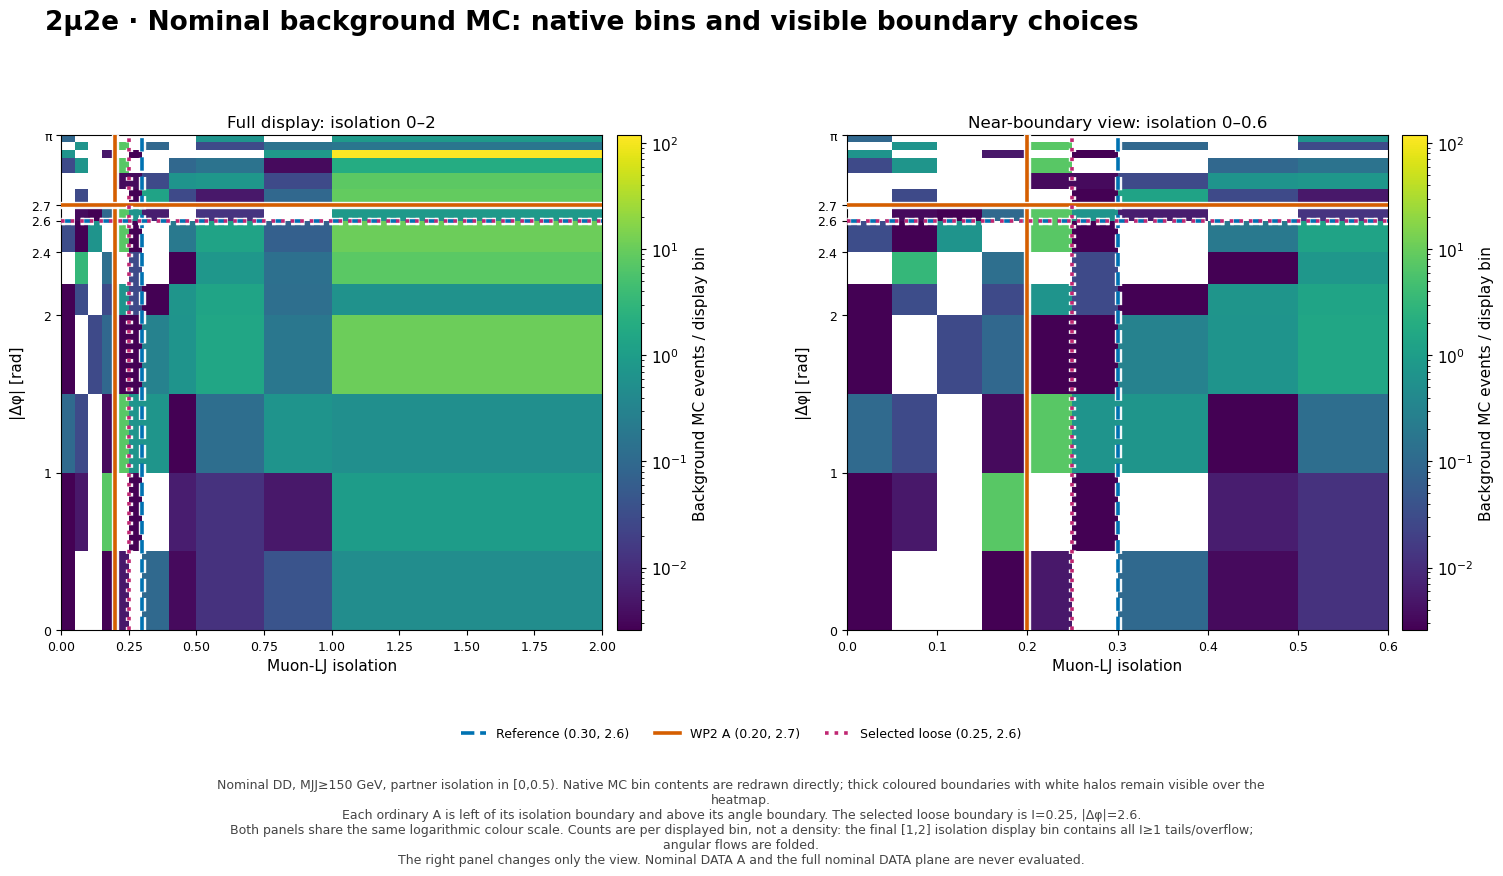

In [3]:
display(figure_lookup['if_nominal_plane'])


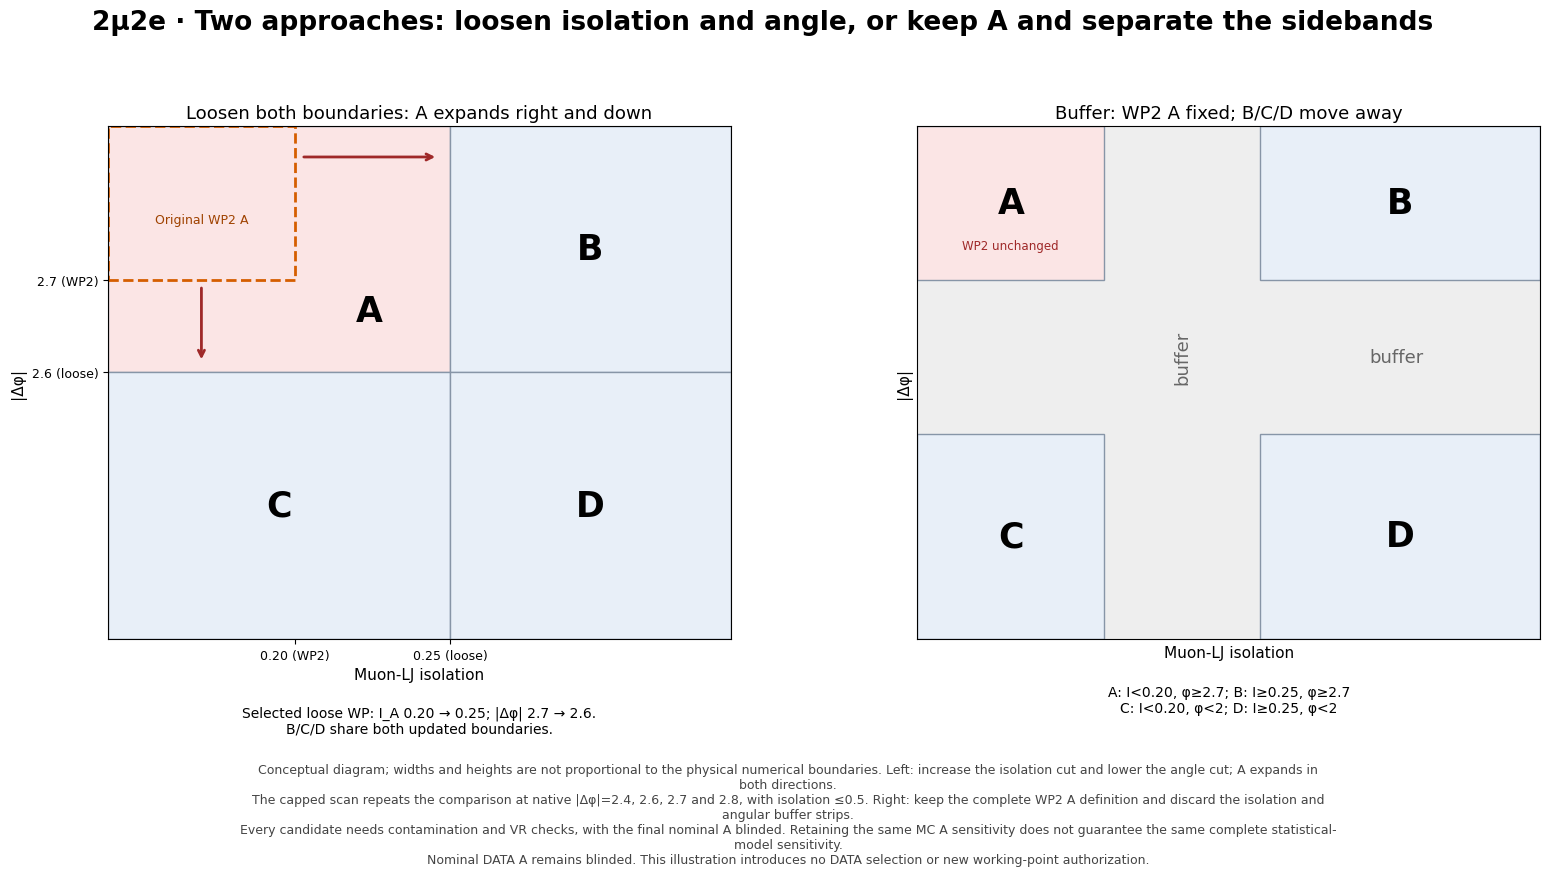

In [4]:
display(figure_lookup['if_approaches'])


## 2. Ordinary boundary relaxation: absolute sensitivity versus contamination

The three panels show **S/√(S+B), Z, and maximum nominal B/C/D contamination**. S and B are per-hypothesis signal and direct background MC yields in A. The first two panels show **absolute medians over the same 60 matching 2Mu2E hypotheses**, without division by WP2. The contamination envelope checks all 120 hypotheses separately.

The solid known-background Z is the primary objective; dashed finite-MC Z and S/√(S+B) are diagnostics. Selection uses MC, without tuning to nominal DATA counts or VR DATA κ. Both the global and per-angle selections now use the absolute objective. Historical-A geometry is not a ranking gate.


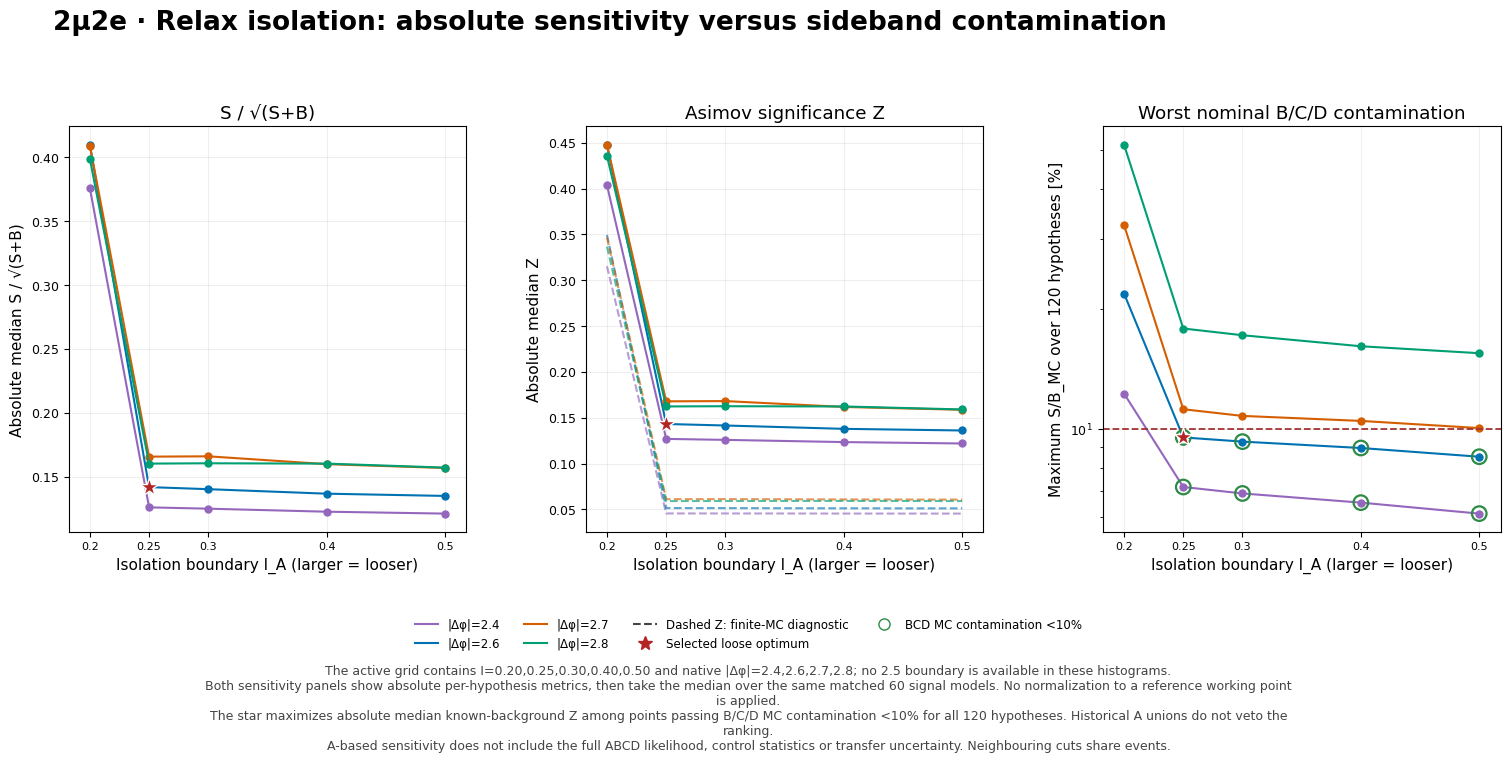

In [5]:
display(figure_lookup['if_tradeoff'])


### Final loose optimum: (0.25,2.6)

The selected point has **maximum BCD S/B_MC=9.52%**, absolute median **S/√(S+B)=0.14184**, known-background **Z=0.14320**, and finite-MC diagnostic **Z=0.05141**. Both significance diagnostics favor this global point among contamination-passing candidates. At angle 2.4 the best absolute-known-Z point is (0.25,2.4). No candidate passes at angles 2.7 or 2.8 within isolation≤0.5.

The former (0.30,2.4) result maximized sensitivity only after an extra historical-A veto. That veto is removed. The final loose A is now **isolation<0.25 and |Δφ|≥2.6**, with B/C/D defined by the same boundaries. New nominal B/C/D are evaluated only after the fixed MC selection and final-A checks.


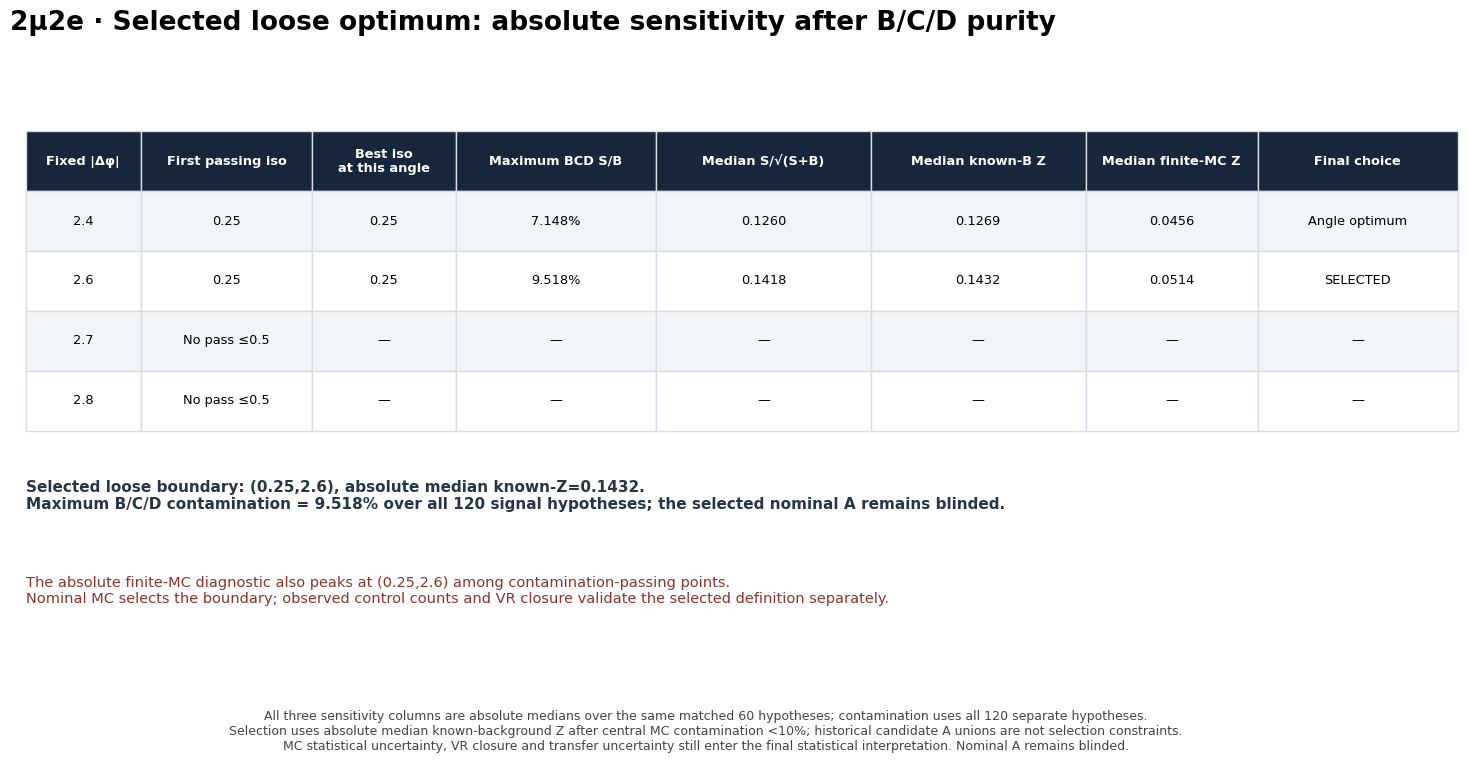

In [6]:
display(figure_lookup['if_selection'])


In [7]:
with pd.option_context('display.max_columns',None):
    display(selection.loc[selection.role.isin(['angle_best','global_best']),
        ['role','candidate_id','a_iso','a_phi','purity_pass','max_S_B_BCD',
         's_sqrt_s_plus_b_median','z_known_b_median','z_mc_stat_diagnostic_median']])


,role,candidate_id,a_iso,a_phi,purity_pass,max_S_B_BCD,s_sqrt_s_plus_b_median,z_known_b_median,z_mc_stat_diagnostic_median
1,angle_best,I_i0p25_p2p4,0.25,2.4,True,0.071483,0.12598,0.12692,0.045568
3,angle_best,I_i0p25_p2p6,0.25,2.6,True,0.095178,0.14184,0.1432,0.051405
6,global_best,I_i0p25_p2p6,0.25,2.6,True,0.095178,0.14184,0.1432,0.051405


### Nominal MC closure

κ_MC=A_MC/(B_MC×C_MC/D_MC) tests factorization in the nominal simulation. It is separate from VR MC and VR DATA. The plotted 0.9–1.1 band is only a visual guide; sparse MC errors and values outside 0–2 are retained in the tables.


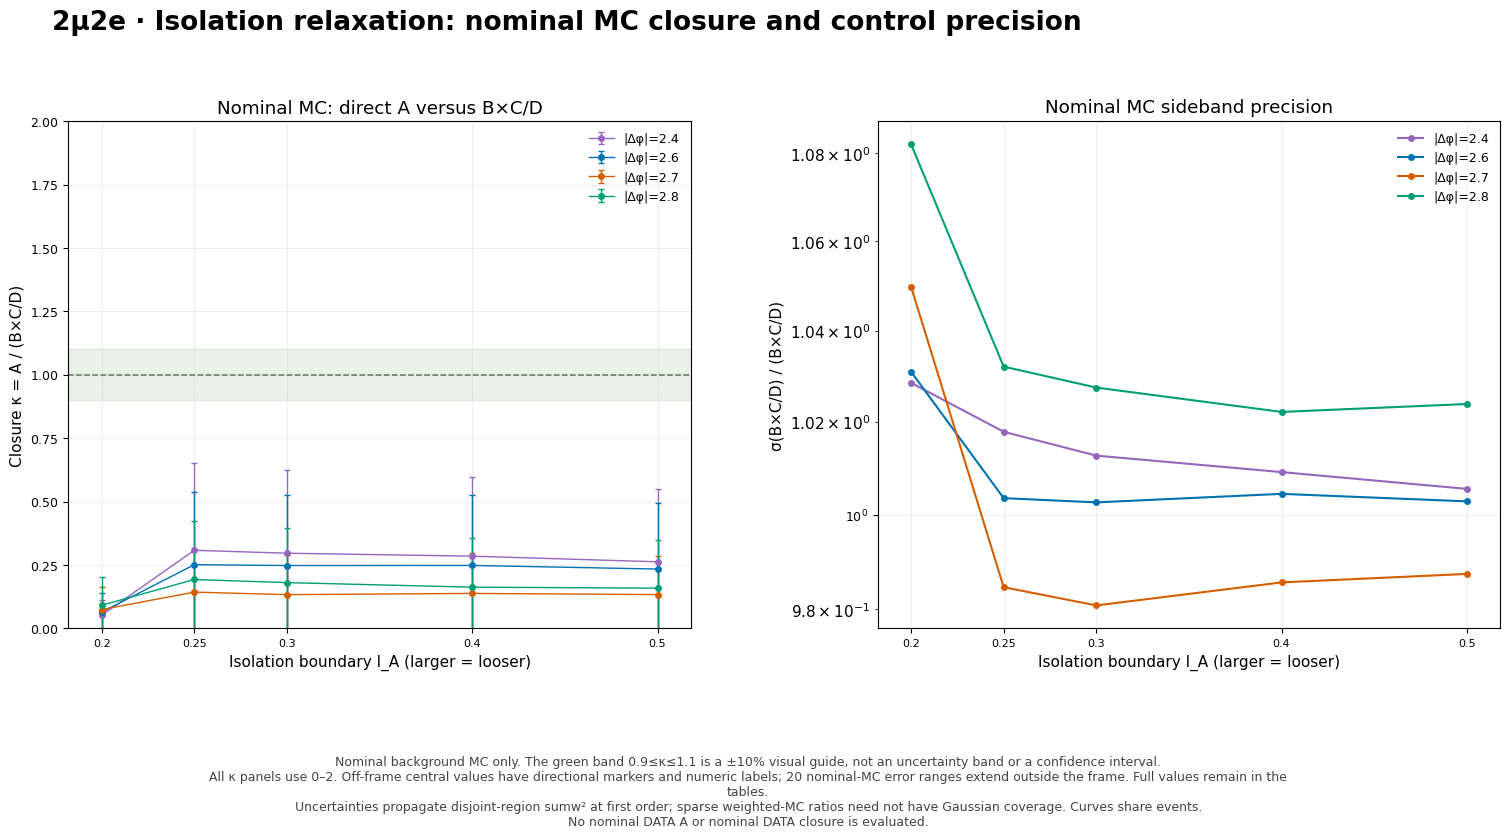

In [8]:
display(figure_lookup['if_nominal_closure'])


### Low mass: separate MC and DATA VR closure scans

Each column is an explicit displacement category. The MC figure displays the simulated closure; the DATA figure uses only already released identical ABCD measurements. Curves share events. A withheld point is not a zero count, and its reason is exported.


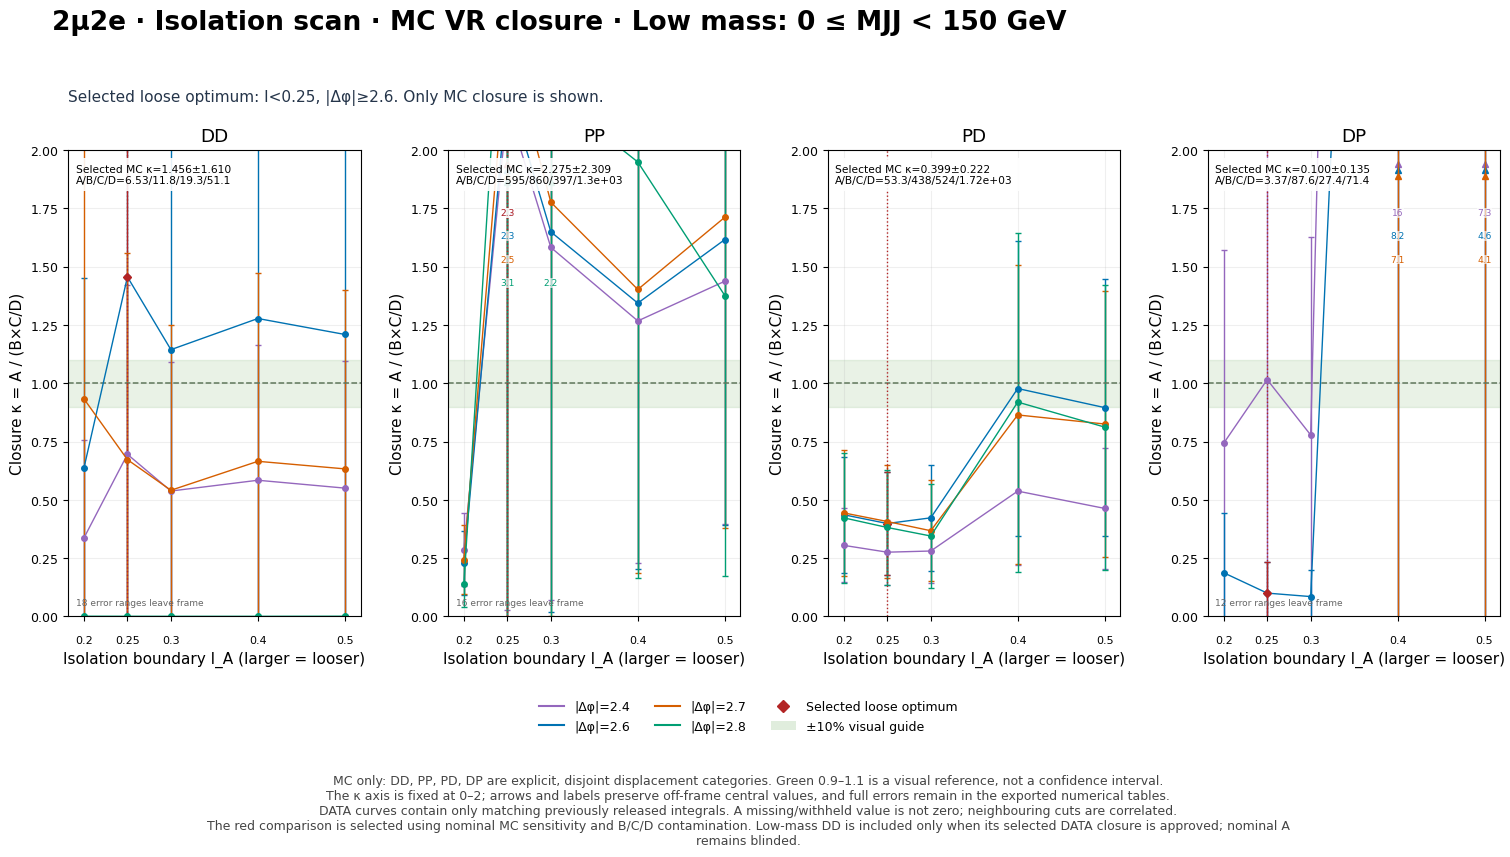

In [9]:
display(figure_lookup['if_vr_mc_low'])


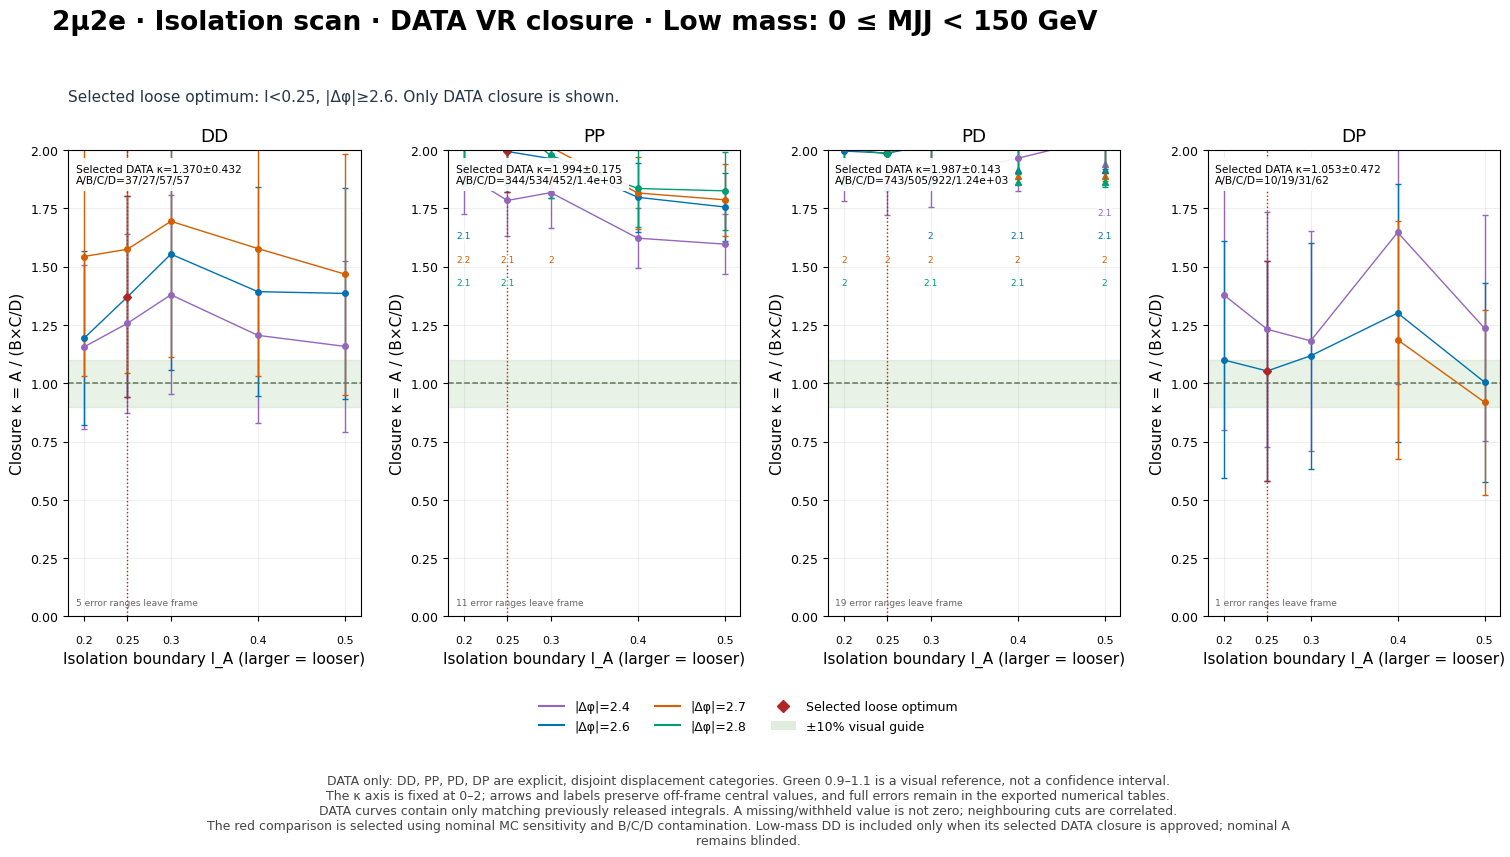

In [10]:
display(figure_lookup['if_vr_data_low'])


### Intermediate mass: separate MC and DATA VR closure scans

Each column is an explicit displacement category. The MC figure displays the simulated closure; the DATA figure uses only already released identical ABCD measurements. Curves share events. A withheld point is not a zero count, and its reason is exported.


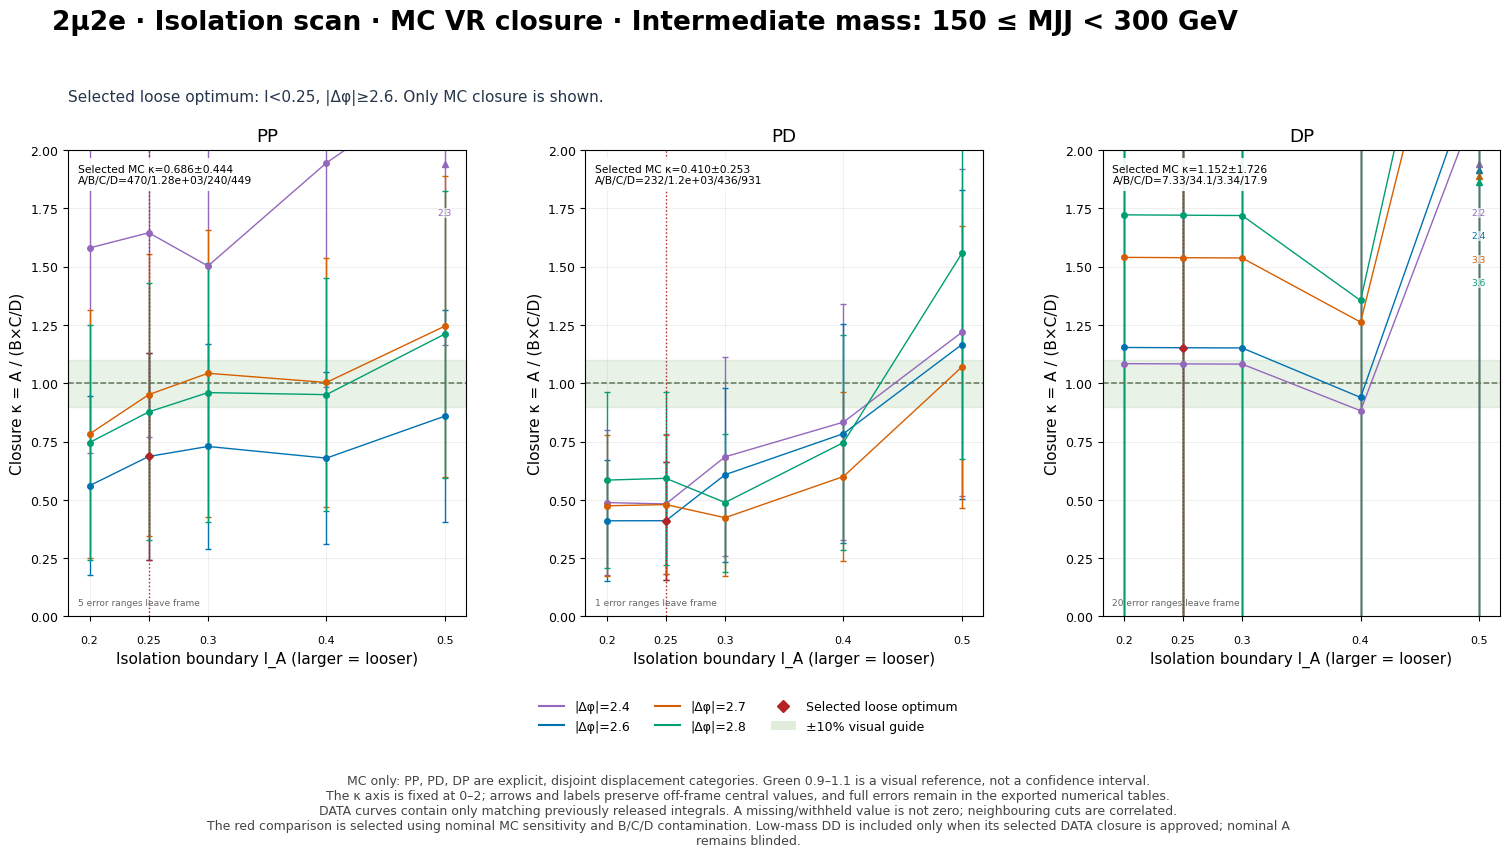

In [11]:
display(figure_lookup['if_vr_mc_intermediate'])


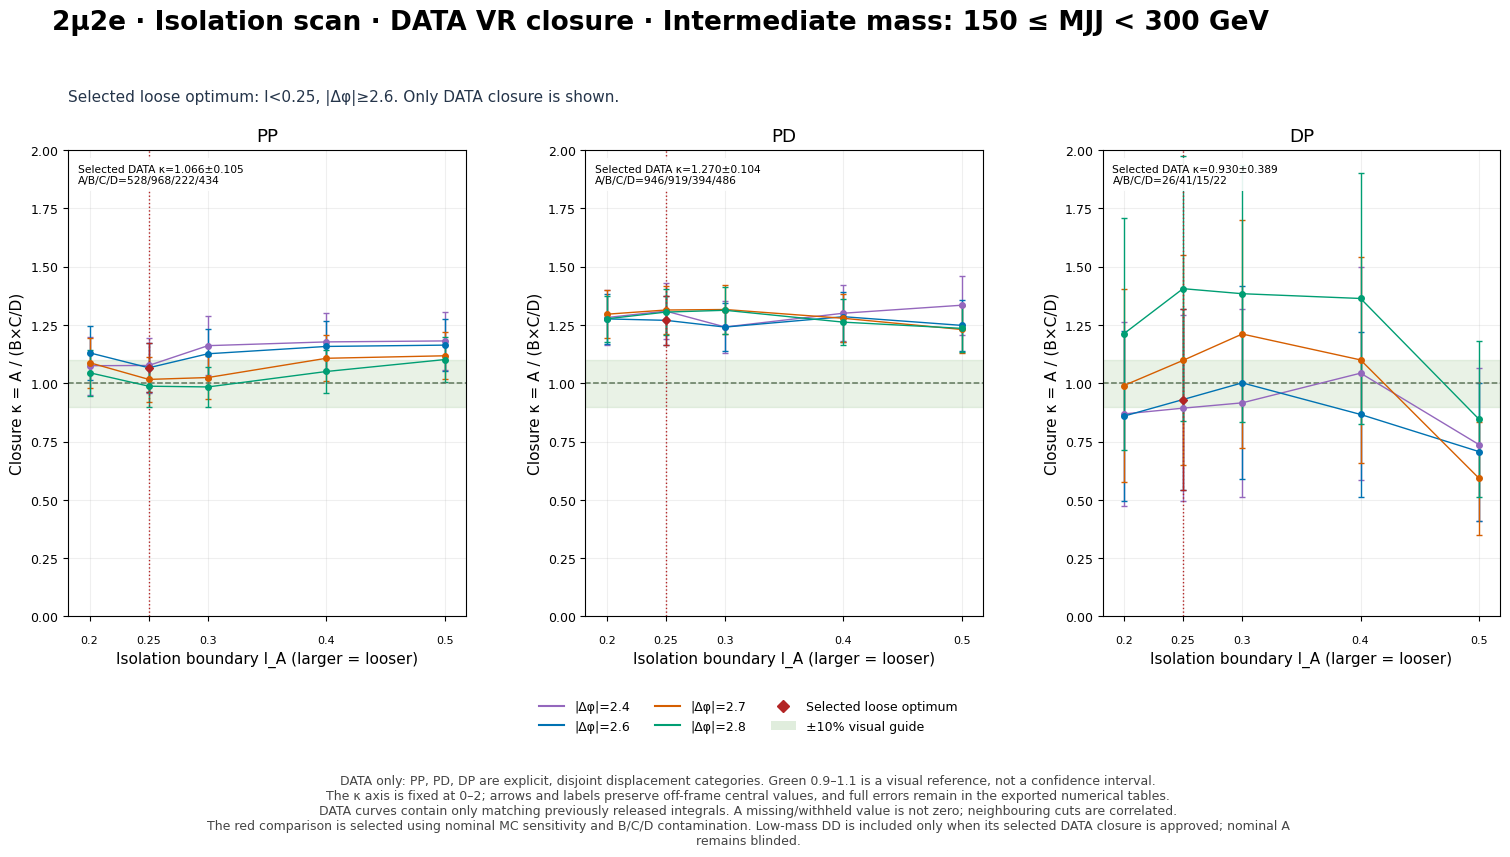

In [12]:
display(figure_lookup['if_vr_data_intermediate'])


### Mass inclusive: separate MC and DATA VR closure scans

Each column is an explicit displacement category. The MC figure displays the simulated closure; the DATA figure uses only already released identical ABCD measurements. Curves share events. A withheld point is not a zero count, and its reason is exported.


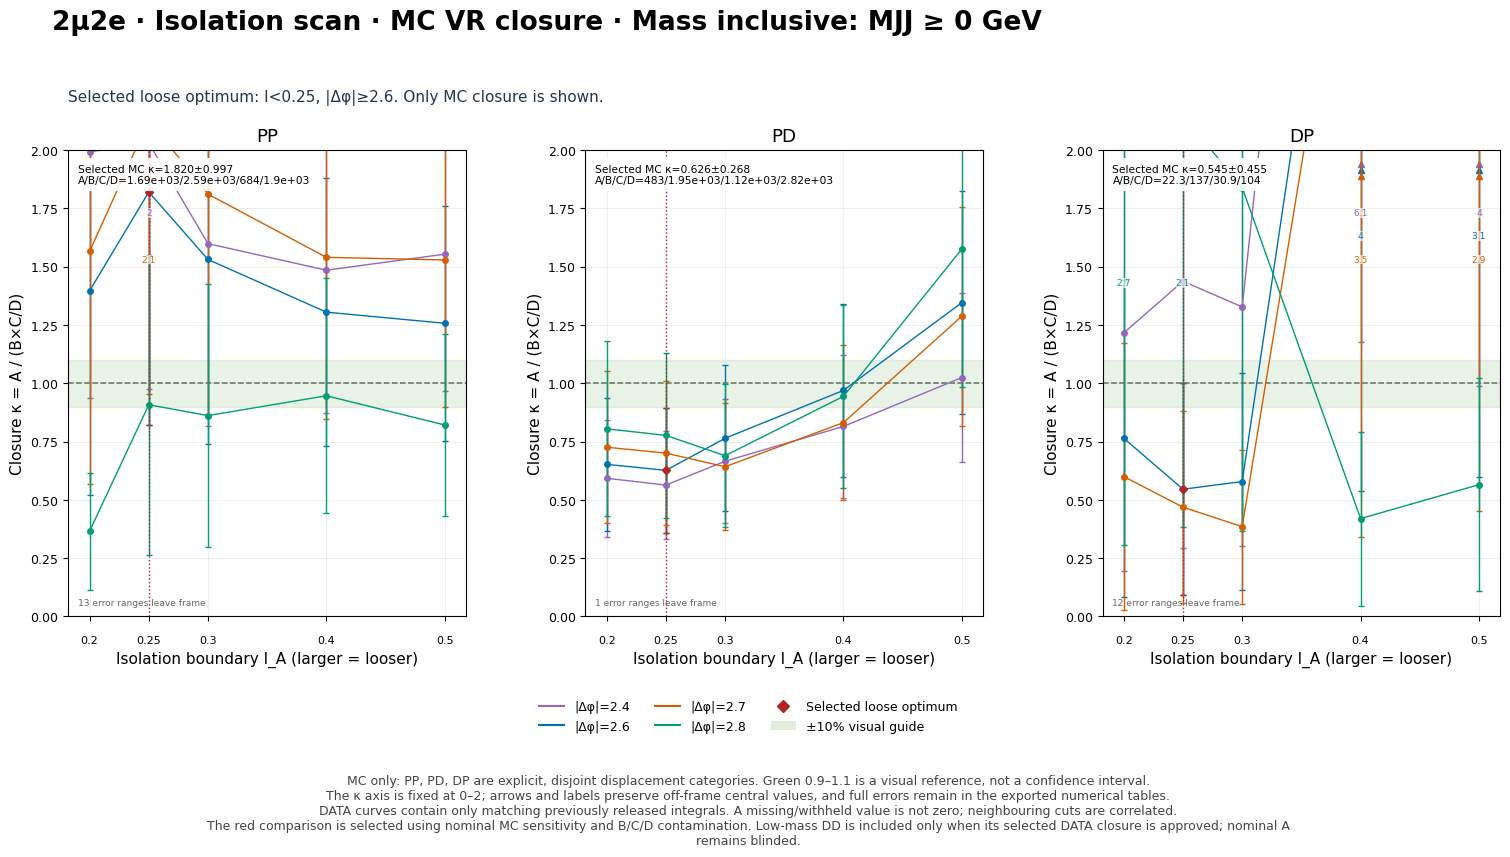

In [13]:
display(figure_lookup['if_vr_mc_all'])


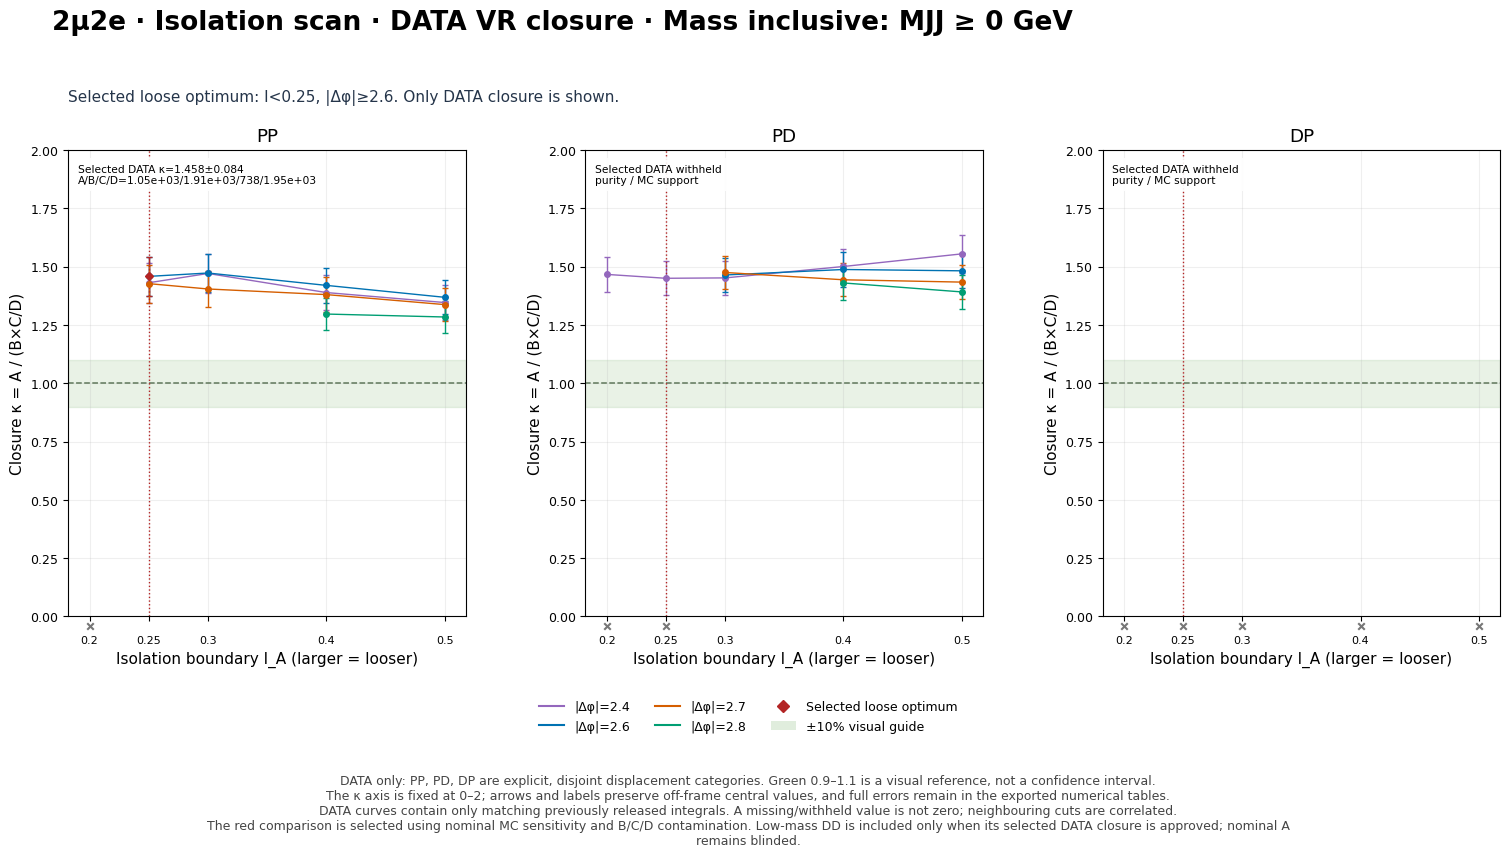

In [14]:
display(figure_lookup['if_vr_data_all'])


### Final loose-boundary DATA validation: (0.25,2.6)

The following 01–08-style 1D scans show observed A and DATA B×C/D, κ, and maximum regional MC contamination, with the selected point marked. They are **boundary scans**, not differential event-shape fits. Adjacent thresholds are correlated.

The accompanying DATA 2D plots overlay the selected ordinary boundaries. A gray crossed bin is blinded/unsupported; a visible white bin has zero events. A display may contain previously public safe bins even where the complete selected-WP ABCD integral is withheld. The bin display never substitutes for complete closure yields.


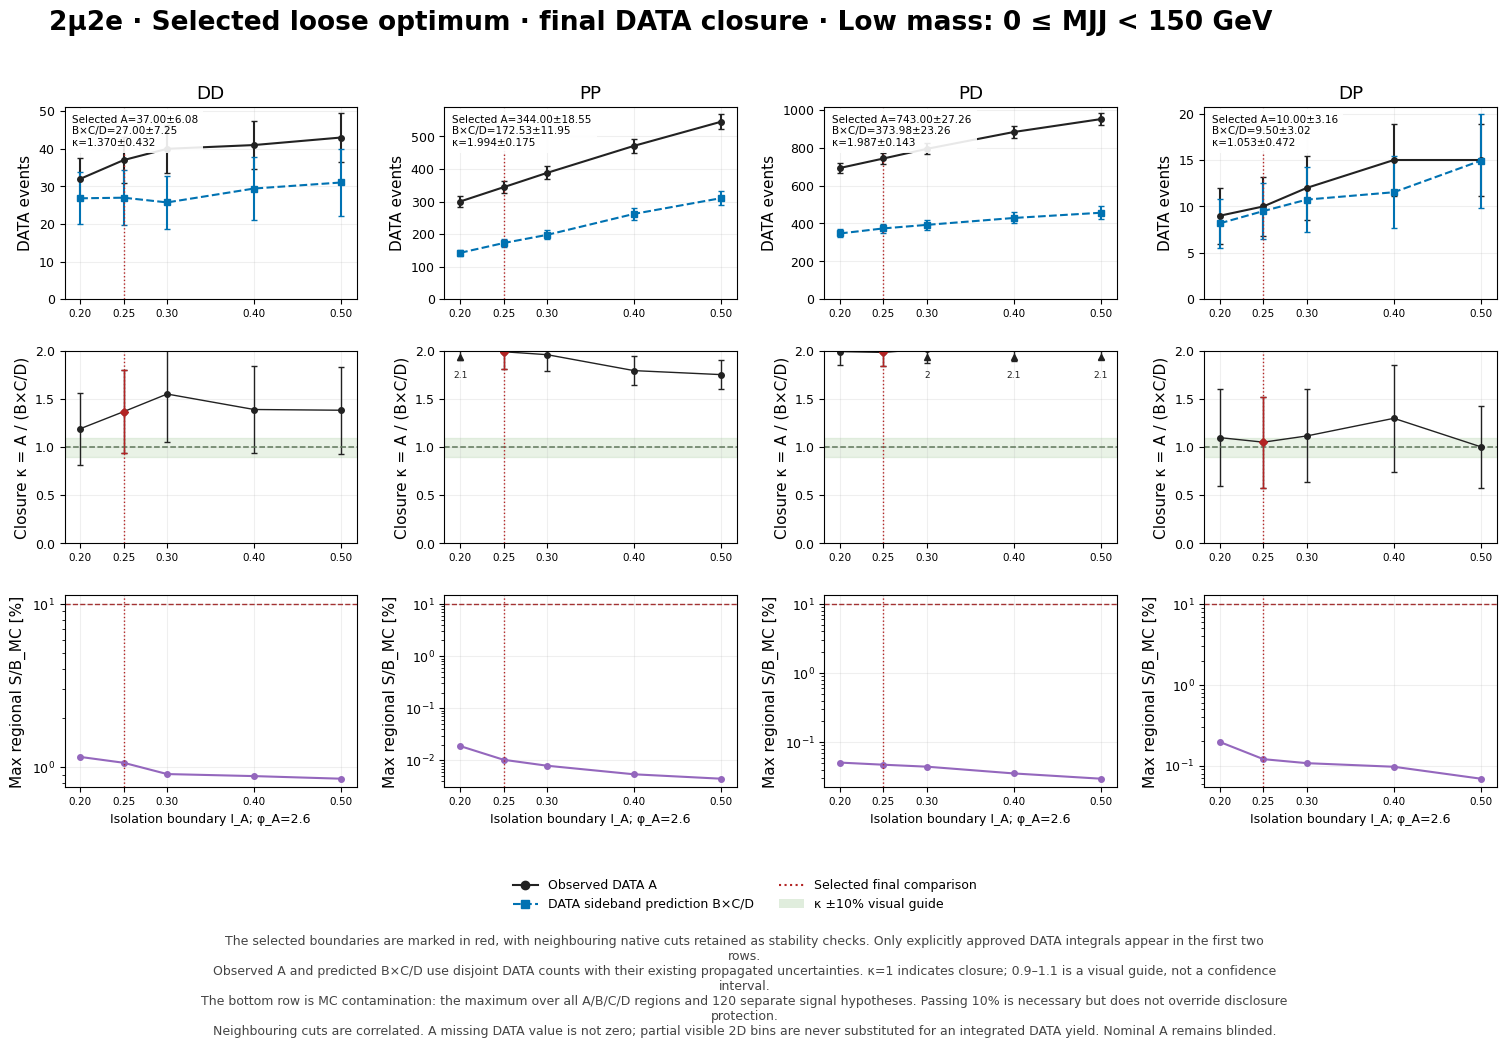

In [15]:
display(figure_lookup['loose_final_1d_low'])


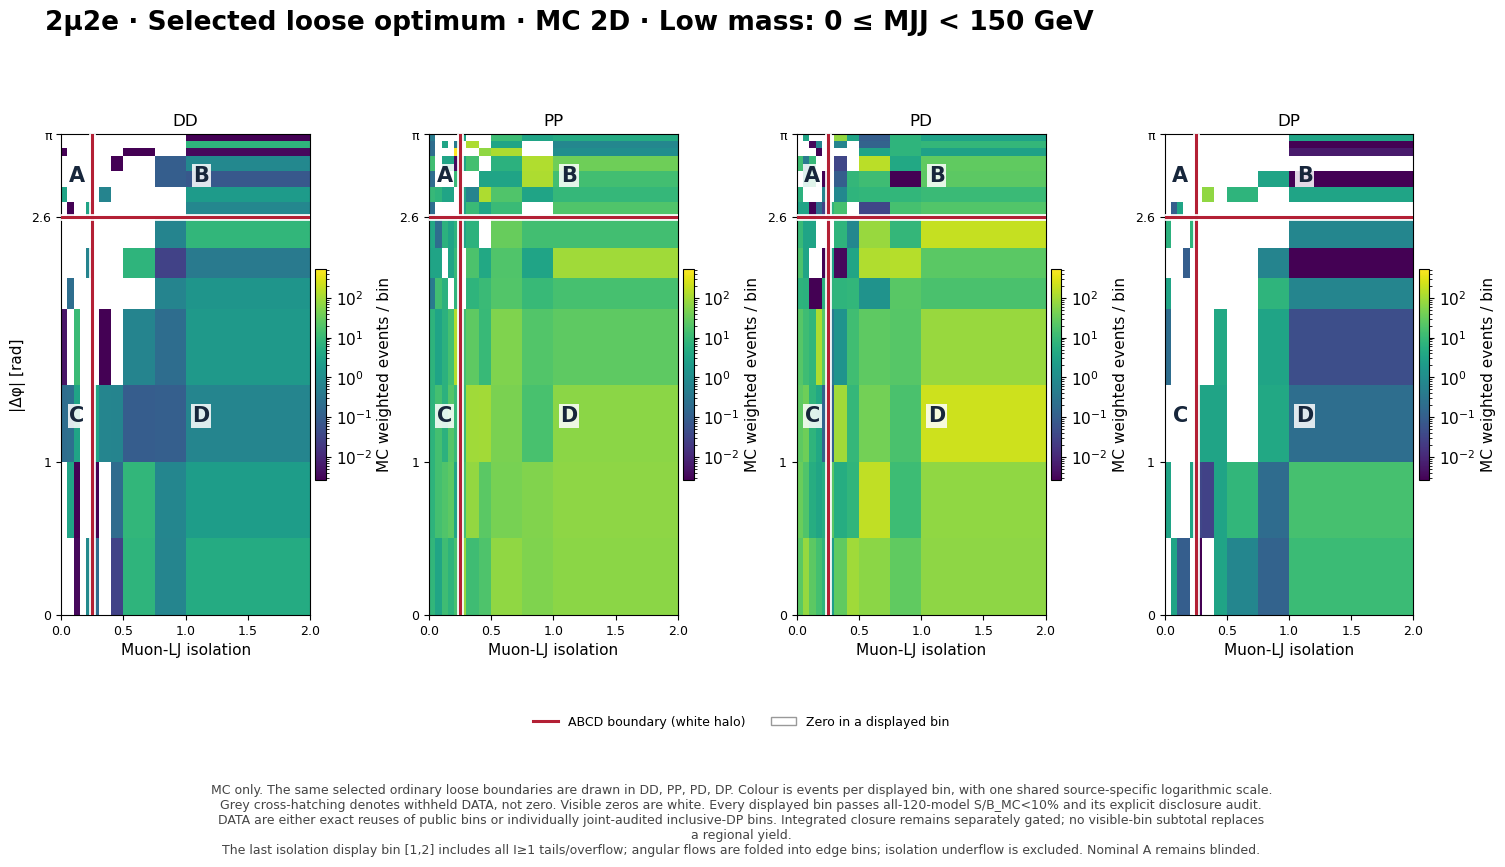

In [16]:
display(figure_lookup['loose2d_mc_low'])


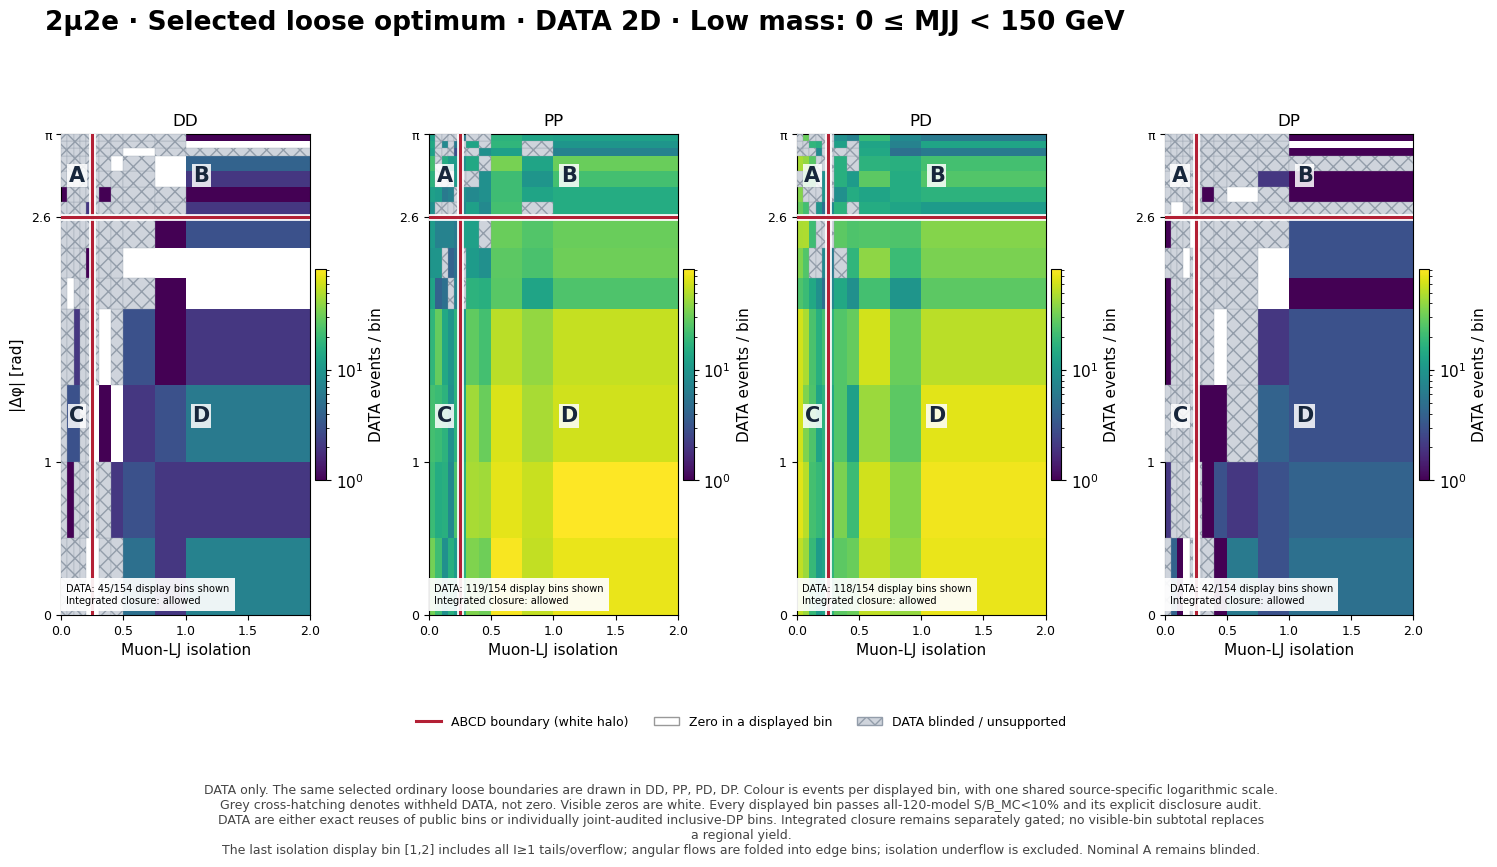

In [17]:
display(figure_lookup['loose2d_data_low'])


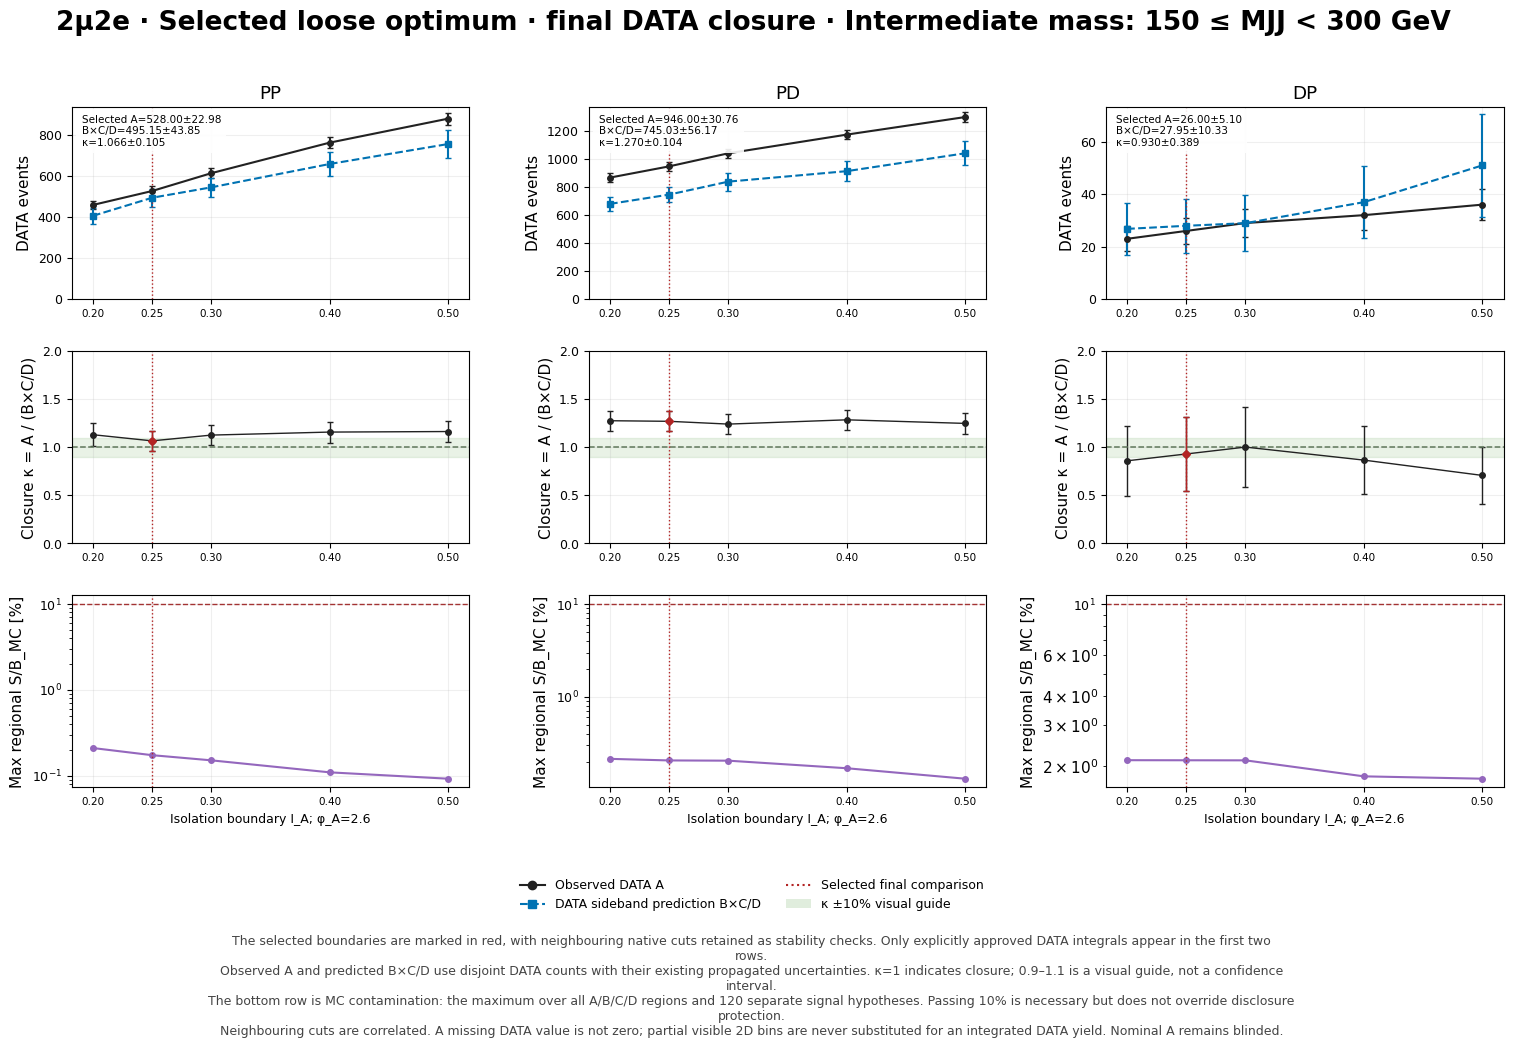

In [18]:
display(figure_lookup['loose_final_1d_intermediate'])


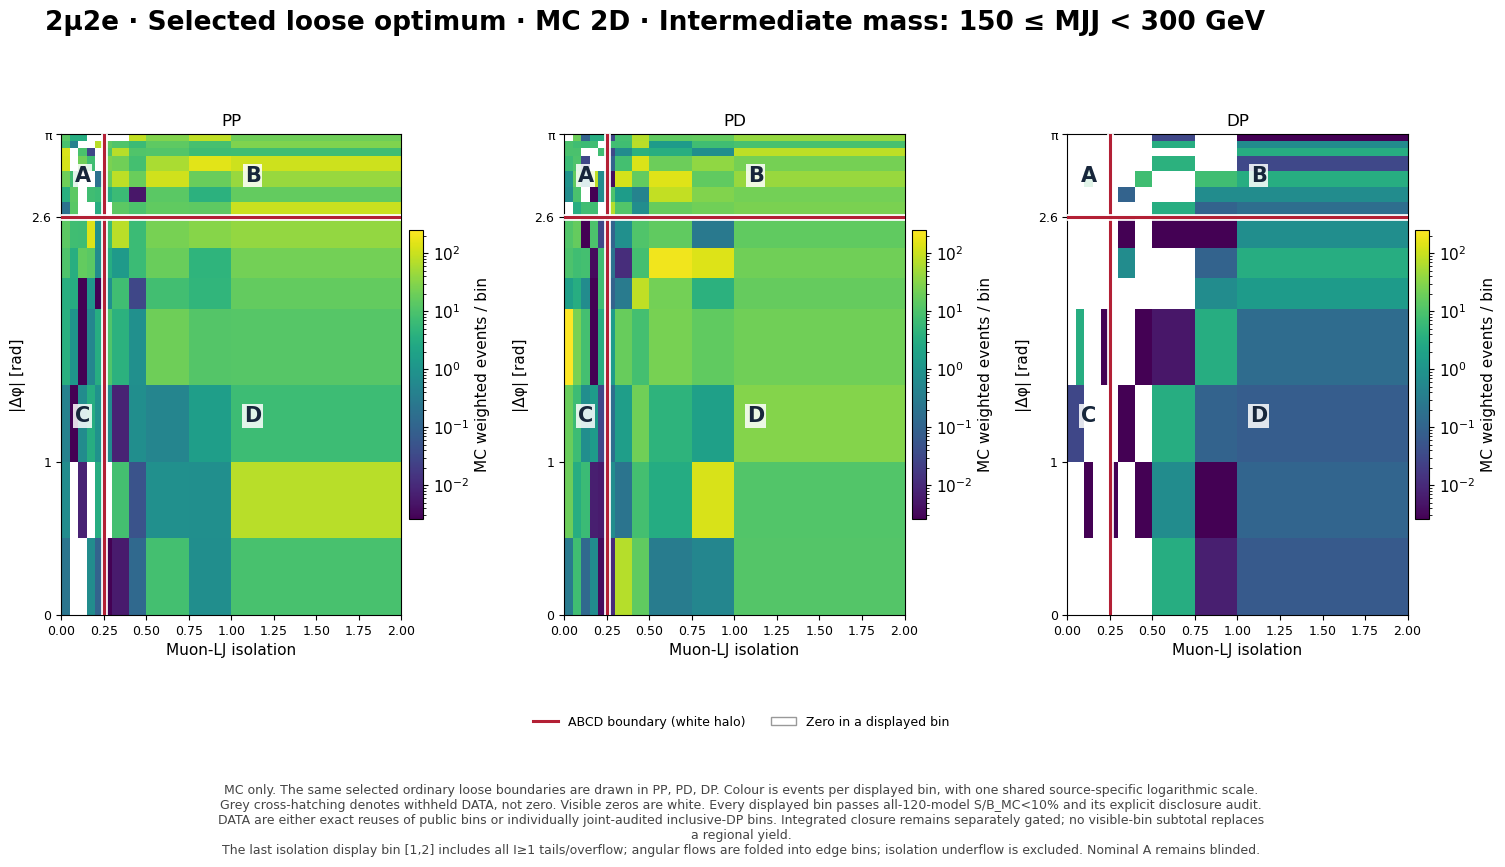

In [19]:
display(figure_lookup['loose2d_mc_intermediate'])


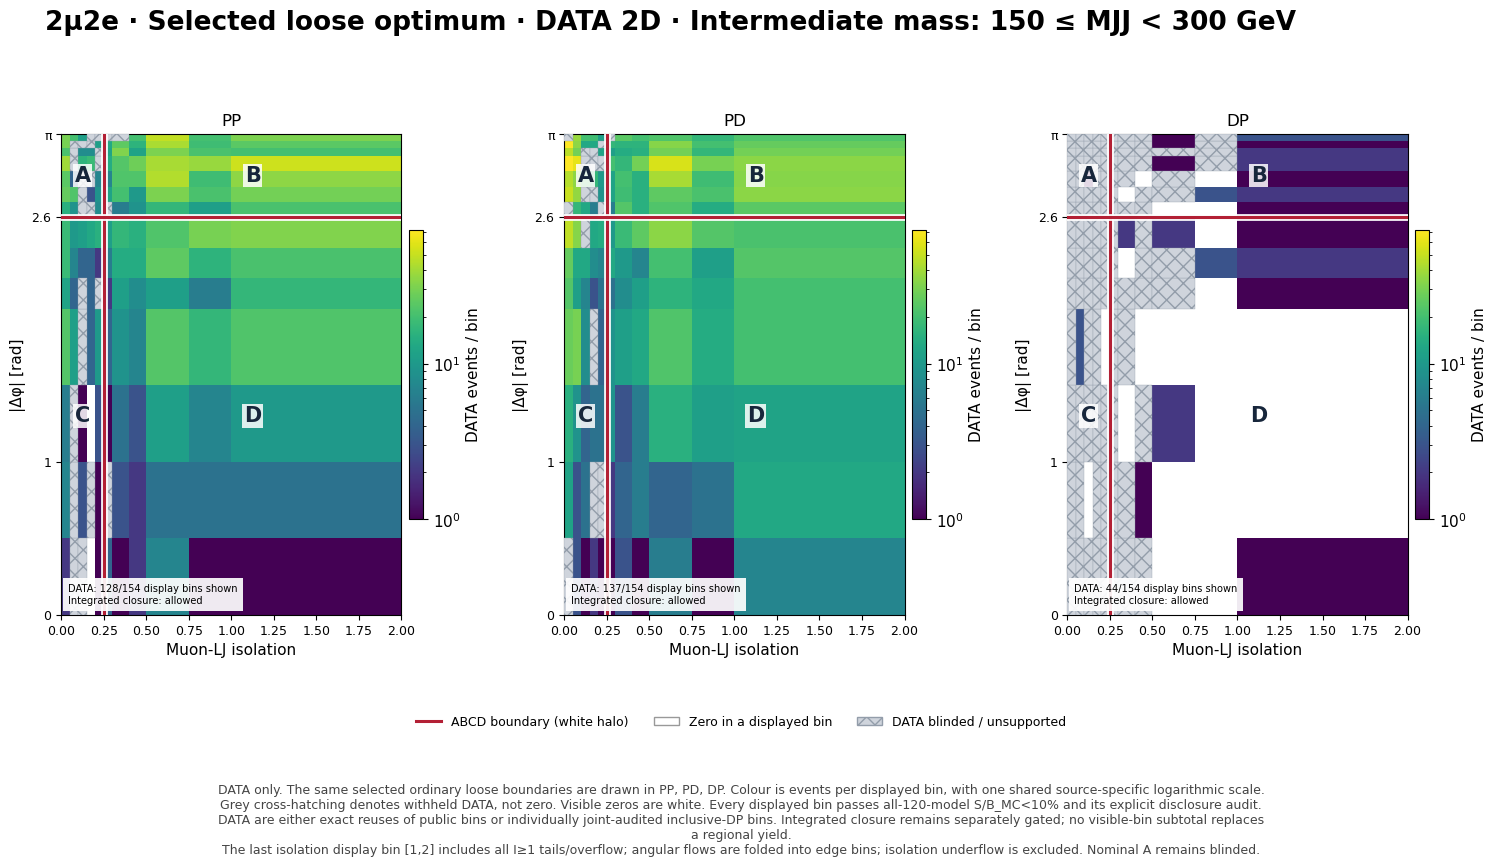

In [20]:
display(figure_lookup['loose2d_data_intermediate'])


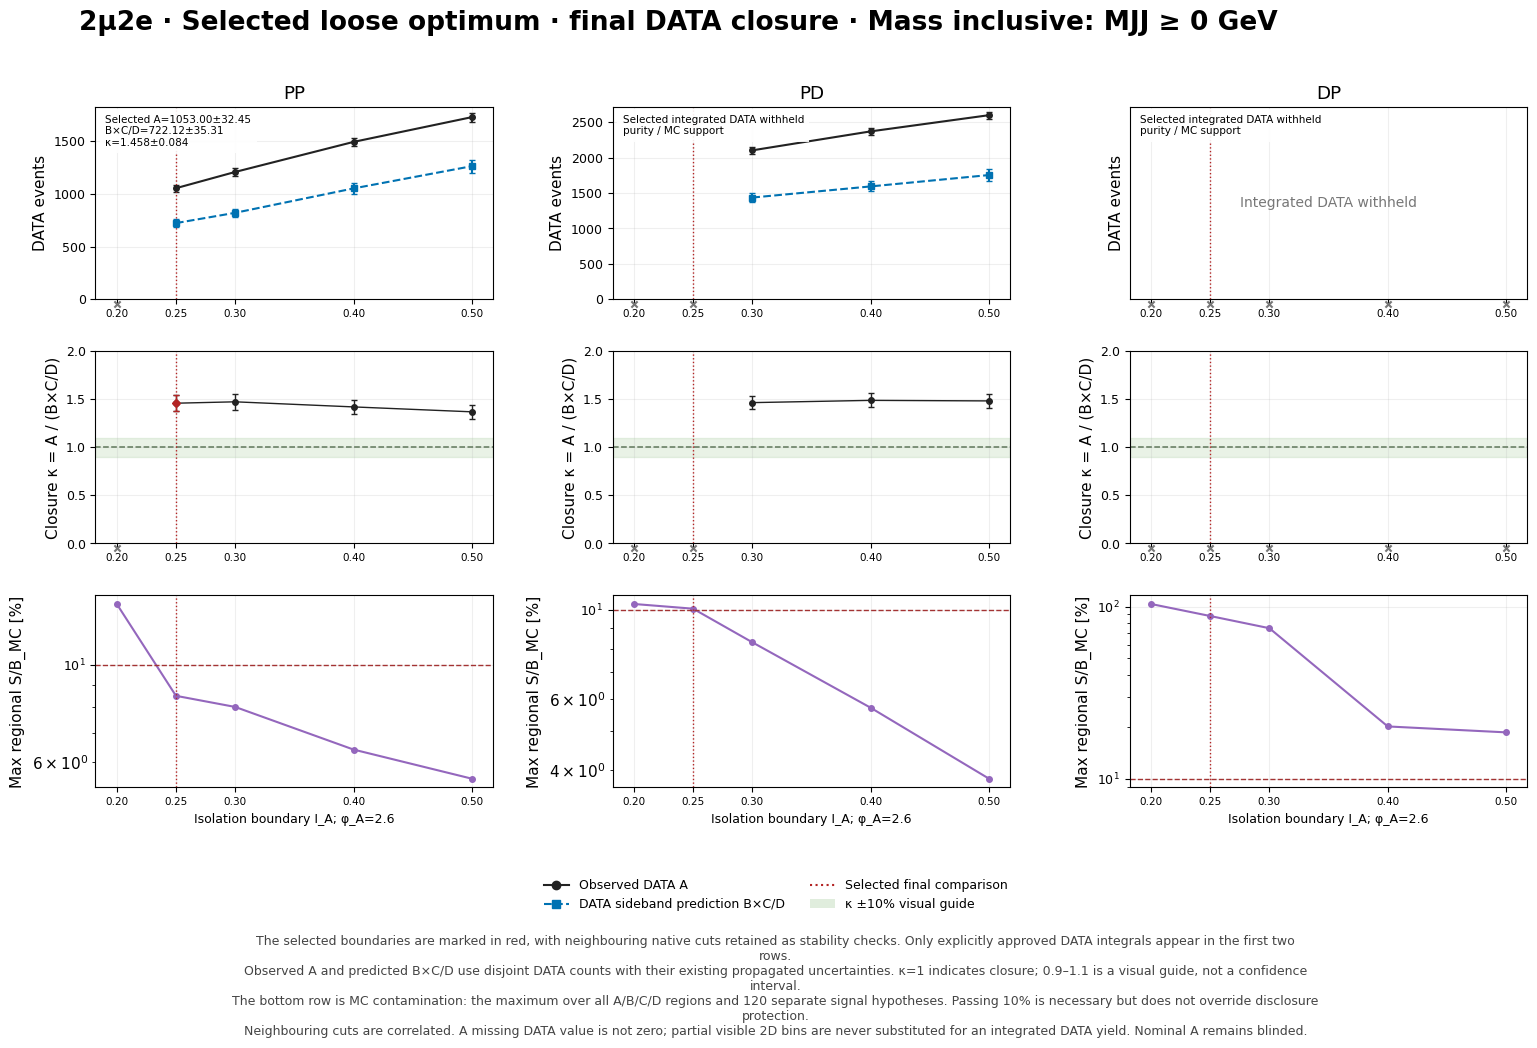

In [21]:
display(figure_lookup['loose_final_1d_all'])


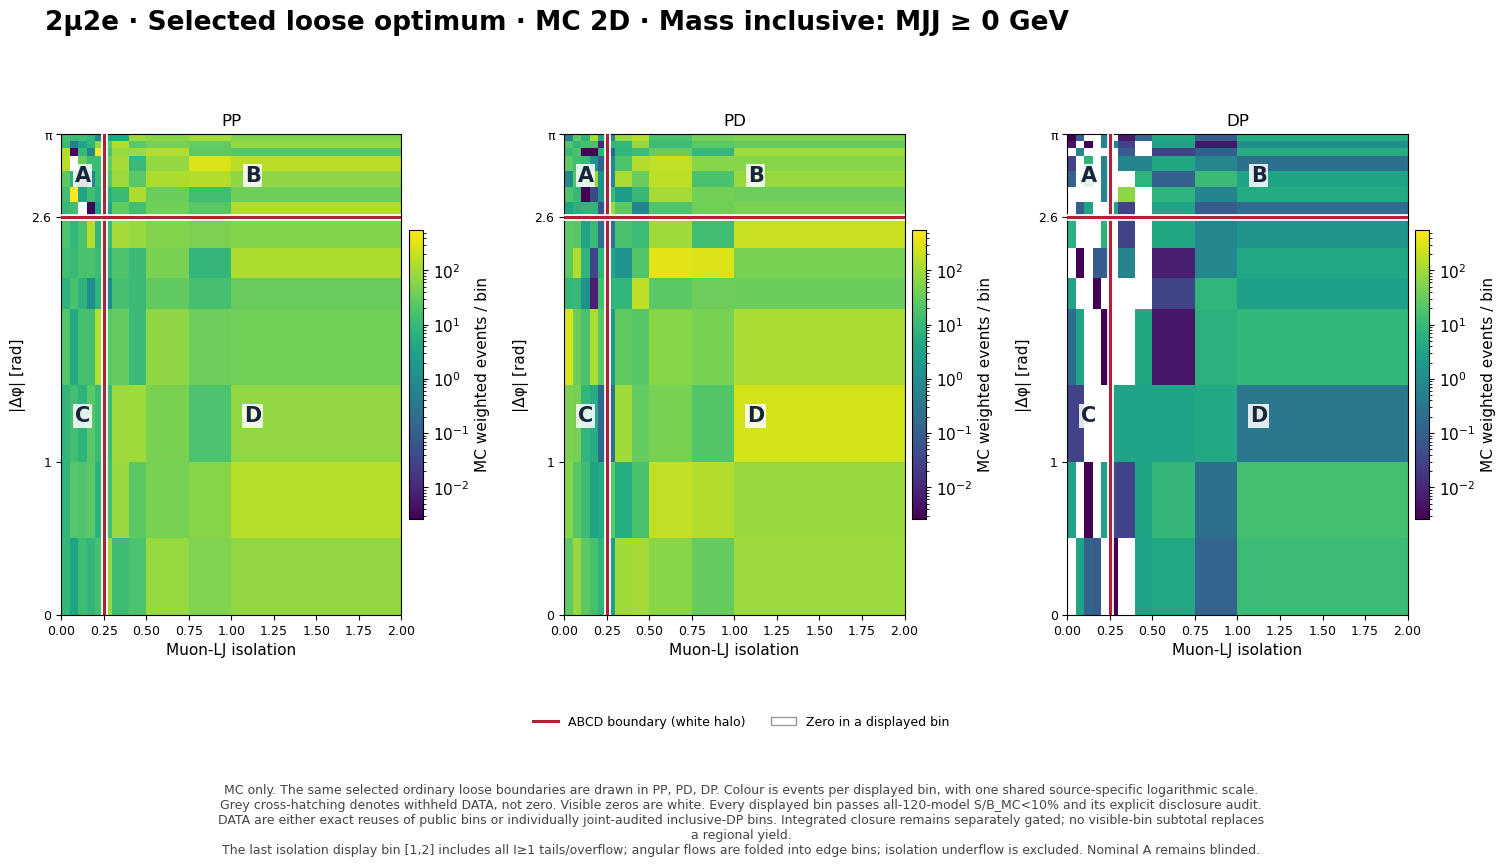

In [22]:
display(figure_lookup['loose2d_mc_all'])


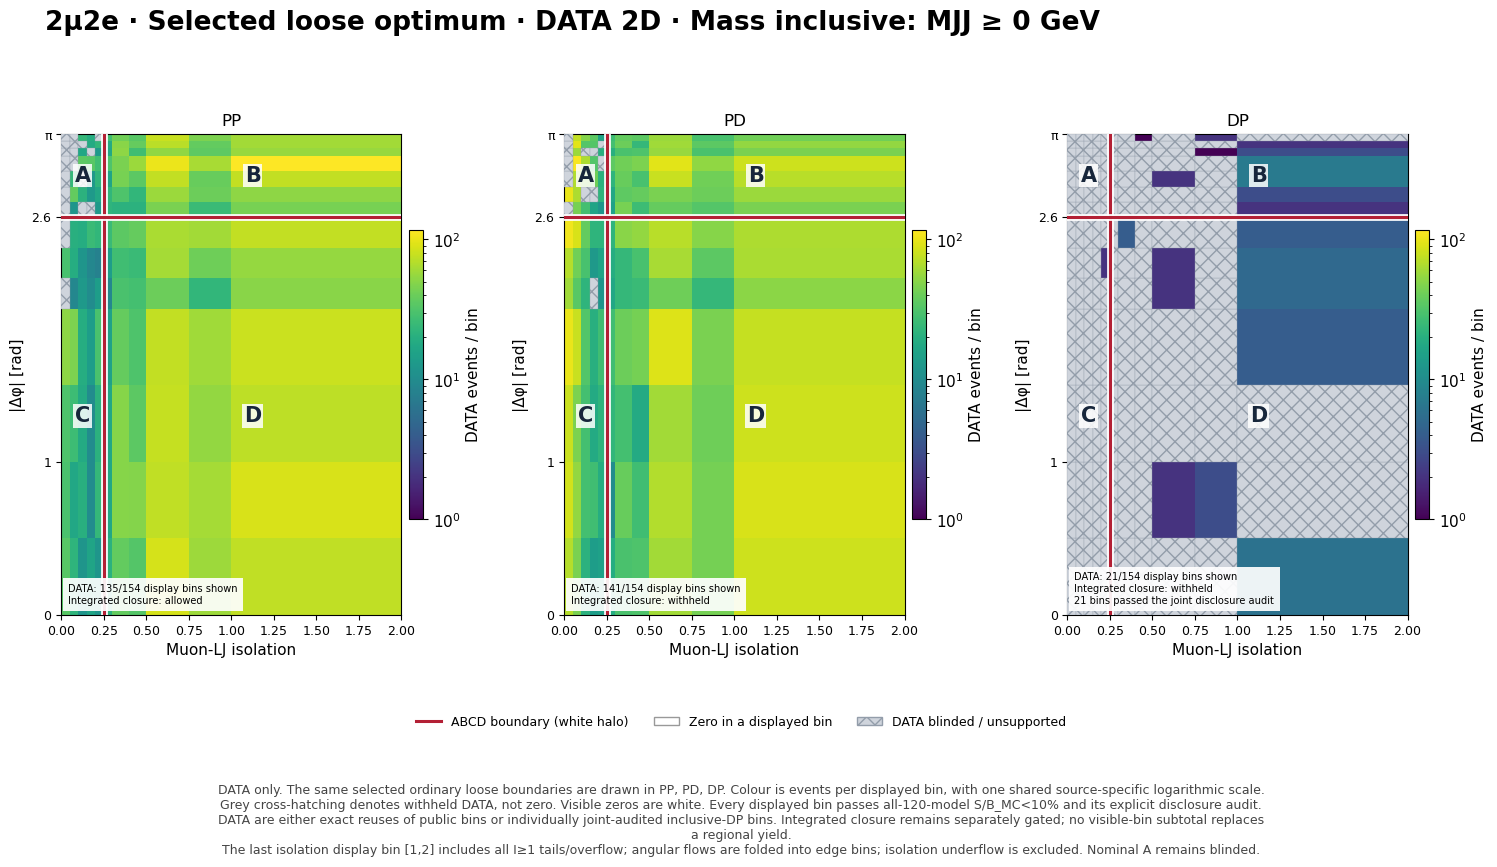

In [23]:
display(figure_lookup['loose2d_data_all'])


In [24]:
def vr_closure_text(study,mass,state):
    frame=tables['vd_closure1d']
    row=frame.loc[frame.study.eq(study)&frame.mass_slice.eq(mass)&frame.plane.eq(state)
        &frame.source.eq('DATA')&frame.selected_point.astype(bool)
        &frame.scan_axis.eq('a_iso' if study=='loose' else 'b_iso')]
    if len(row)!=1:return 'Unavailable'
    row=row.iloc[0]
    return f'{row.kappa:.3f} ± {row.kappa_error:.3f}' if row.display_allowed else 'Blinded / unsupported'
def vr_closure_summary(study):
    lines=['| Mass | PP κ | PD κ | DP κ |','|---|---:|---:|---:|']
    for mass in ['low','intermediate','all']:
        lines.append('| '+mass+' | '+' | '.join(vr_closure_text(study,mass,p) for p in ['PP','PD','DP'])+' |')
    return '\n'.join(lines)
display(Markdown('Selected loose DATA closure:\n\n'+vr_closure_summary('loose')+
    '\n\nIntermediate PP is near unity; PD retains a measurable offset. Low-mass and inclusive closure remain separate validation constraints.'))


Selected loose DATA closure:

| Mass | PP κ | PD κ | DP κ |
|---|---:|---:|---:|
| low | 1.994 ± 0.175 | 1.987 ± 0.143 | 1.053 ± 0.472 |
| intermediate | 1.066 ± 0.105 | 1.270 ± 0.104 | 0.930 ± 0.389 |
| all | 1.458 ± 0.084 | Blinded / unsupported | Blinded / unsupported |

Intermediate PP is near unity; PD retains a measurable offset. Low-mass and inclusive closure remain separate validation constraints.

## 3. Fixed-A buffer: B/D isolation≥0.25 and C/D |Δφ|<2.0

| Region | Isolation | Angle |
|---|---|---|
| A | 0≤I<0.20 | $\lvert\Delta\phi\rvert\ge2.7$ |
| B | I≥0.25 | $\lvert\Delta\phi\rvert\ge2.7$ |
| C | 0≤I<0.20 | $\lvert\Delta\phi\rvert<2.0$ |
| D | I≥0.25 | $\lvert\Delta\phi\rvert<2.0$ |

Excluded strips are **0.20≤I<0.25** and **2.0≤|Δφ|<2.7**. The tight WP2 A is unchanged. Thus all buffers have the same absolute MC-A medians: S/√(S+B)=**0.40908**, known-background Z=**0.44776**, finite-MC Z=**0.34672**.

With the historical veto removed, the smallest MC-purity-passing gap has I_H=0.20, φ_L=2.0. Its nominal B overlaps the *current loose finalist's A*. For this final two-approach DATA comparison, the explicitly chosen buffer is **I_H=0.25, φ_L=2.0**, the smallest passing gap preserving both finalists' A. This is not a claim that 0.25 uniquely maximizes significance: A is fixed across the scan.

The 40 native definitions display sensitivity, contamination and control precision. VR closure and uncertainty-aware inference remain essential to the choice.


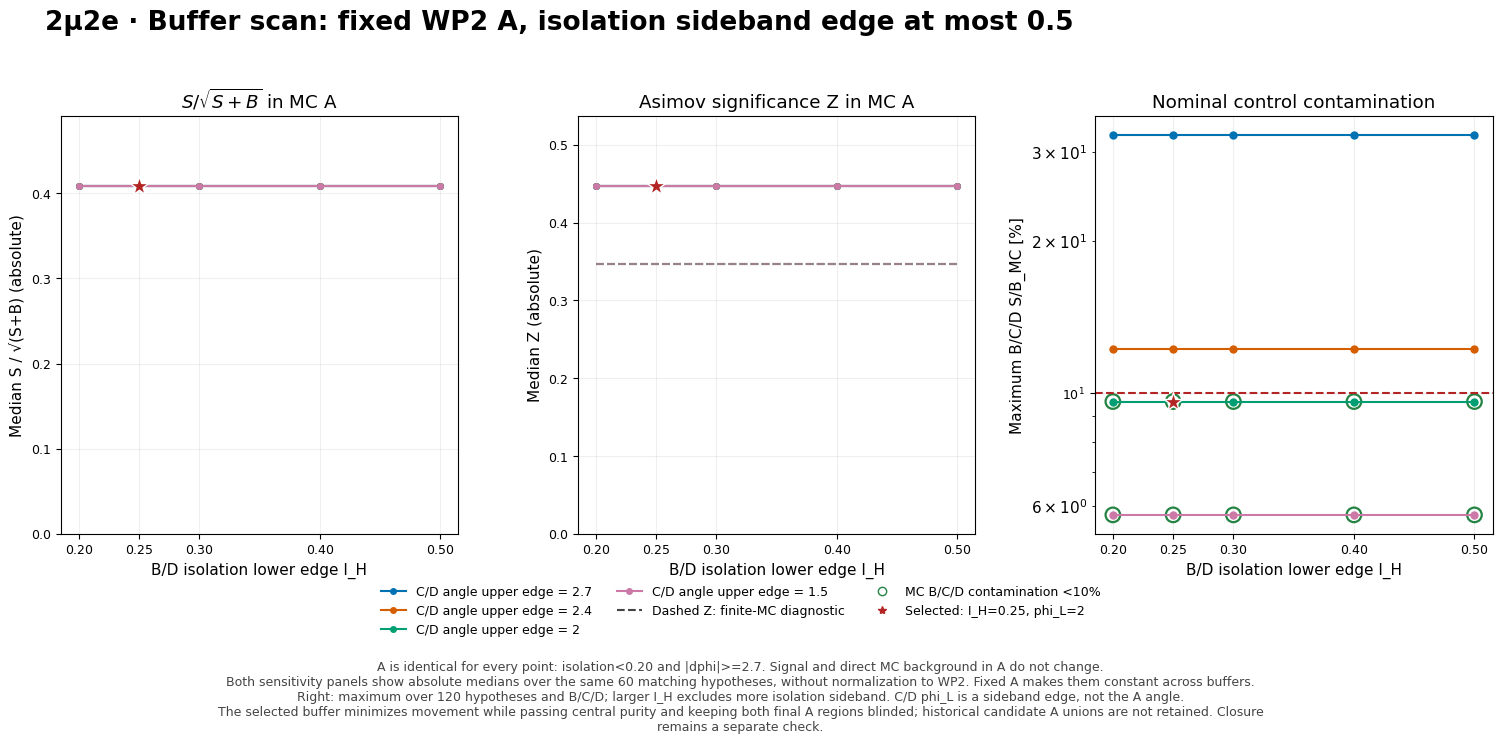

In [25]:
display(figure_lookup['gap_tradeoff'])


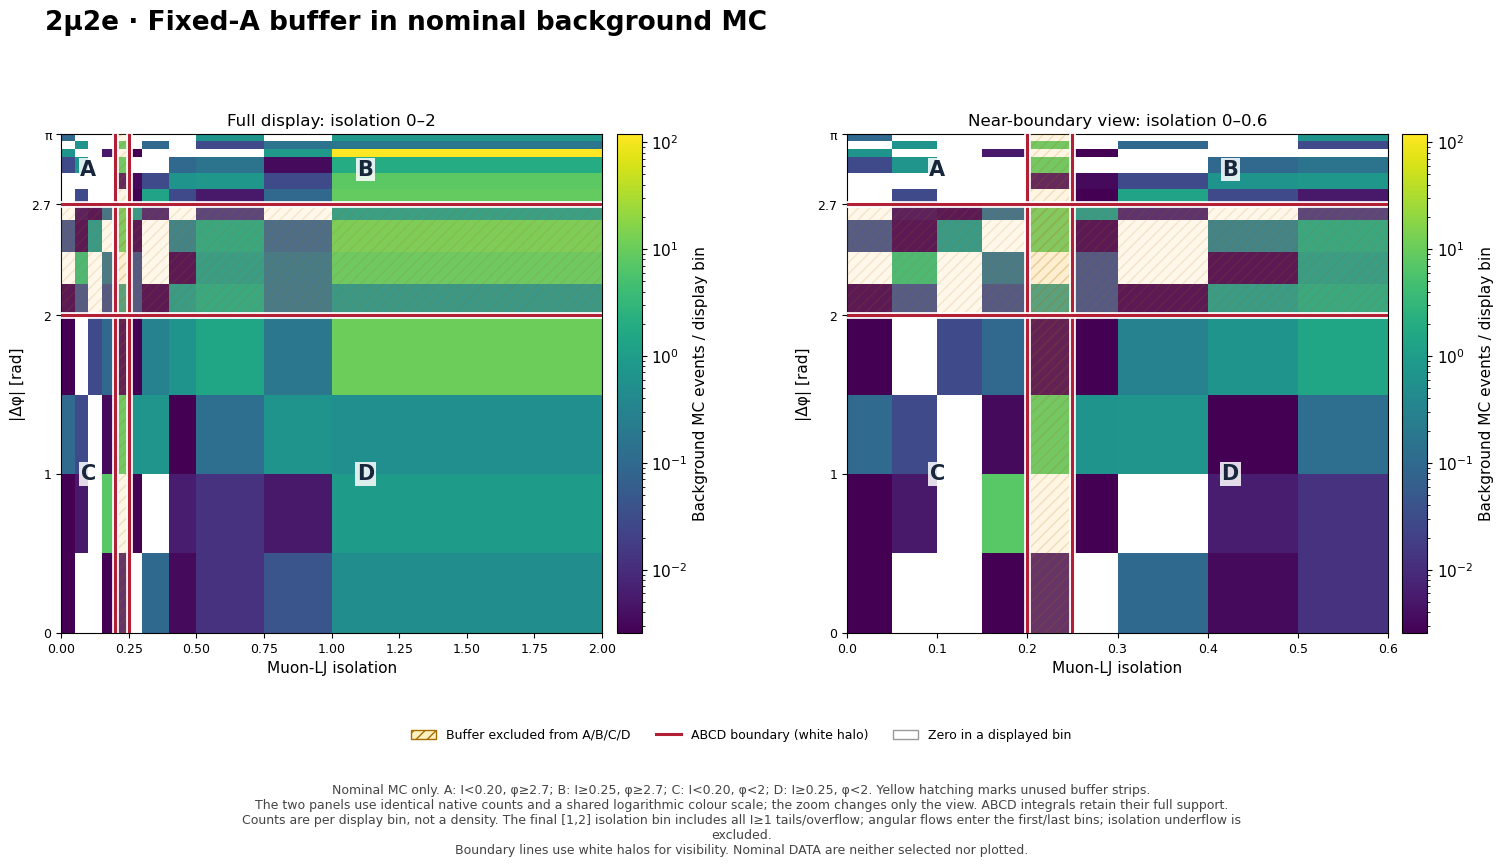

In [26]:
display(figure_lookup['buffer2d_nominal'])


### What the buffer-start closure scan means

This replaces `study_gap_nominal_closure`. **Yes: it scans the buffer sideband edges.** One panel moves the B/D isolation lower edge I_H at fixed φ_L; the other moves the C/D angle upper edge φ_L at fixed I_H. A is unchanged. The resulting κ is nominal background MC closure, not a DATA comparison and not an A-boundary scan.


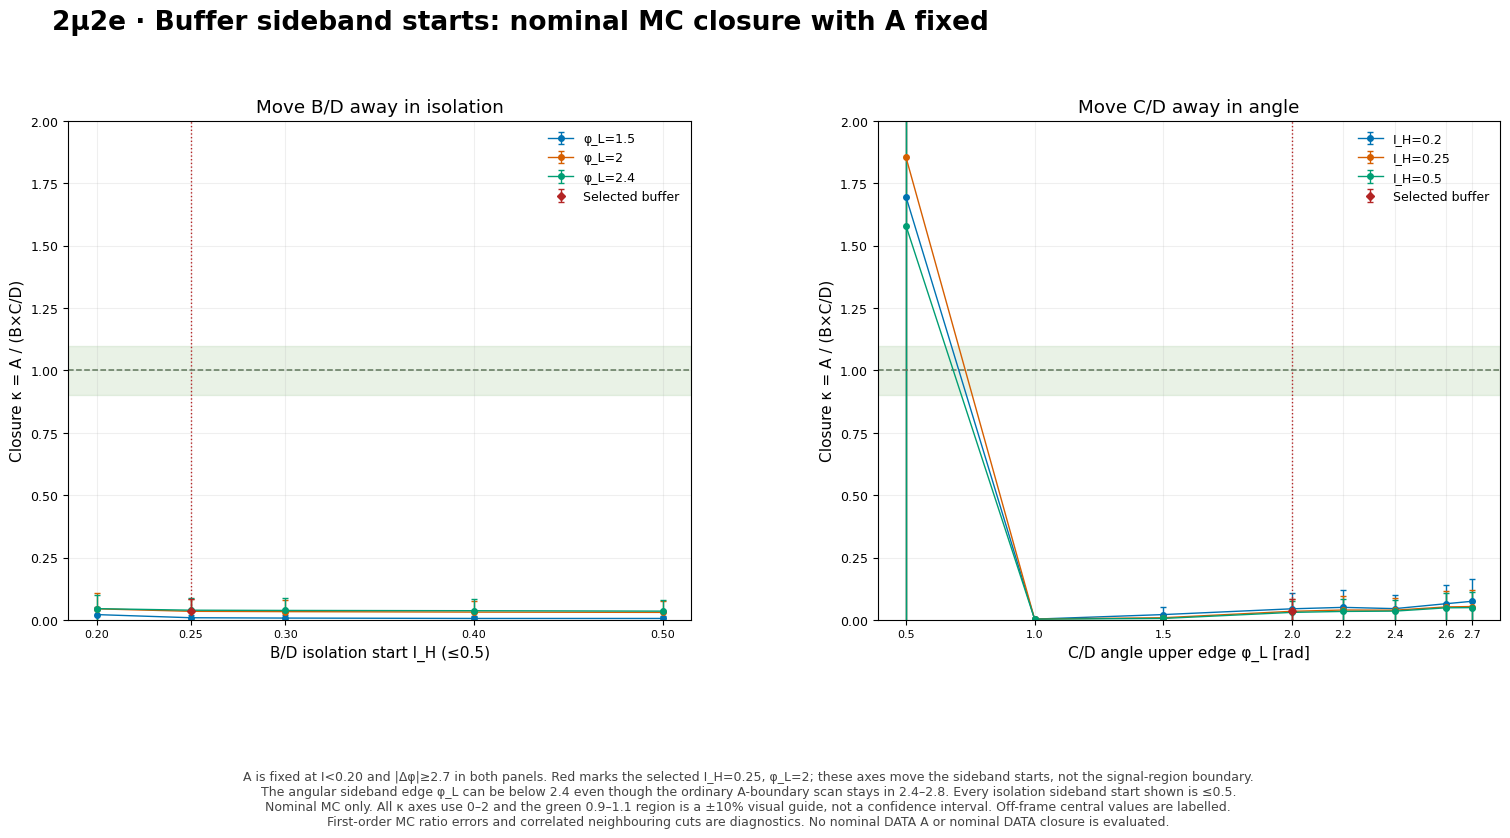

In [27]:
display(figure_lookup['gap_nominal_closure'])


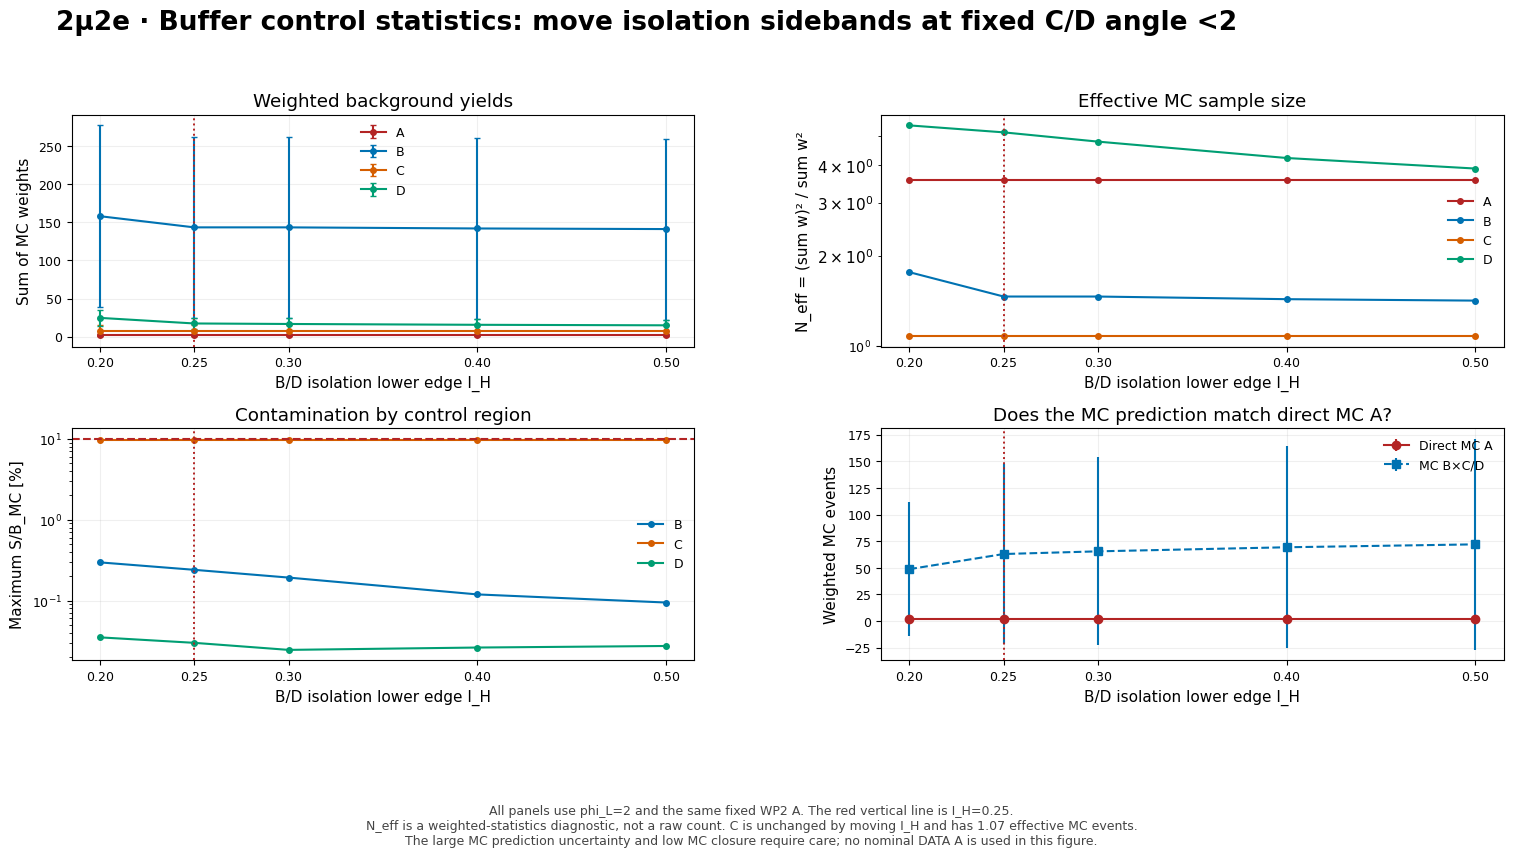

In [28]:
display(figure_lookup['gap_support'])


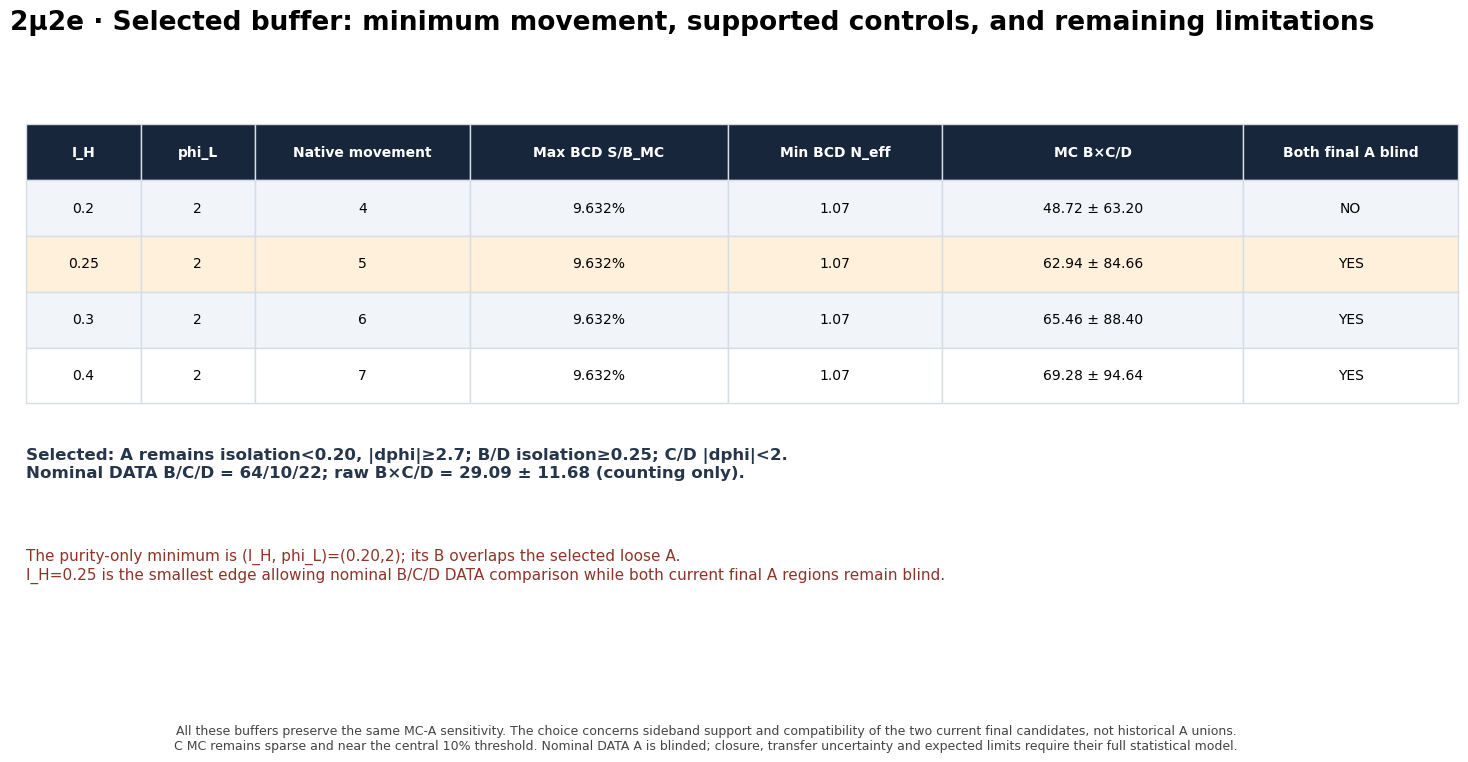

In [29]:
display(figure_lookup['gap_selection'])


### Low mass: separate buffered MC and DATA VR closure

The selected buffer is marked; each scan applies identical buffer geometry to the VR. MC and DATA are on separate figures, with κ in 0–2 and the same 0.9–1.1 visual guide.


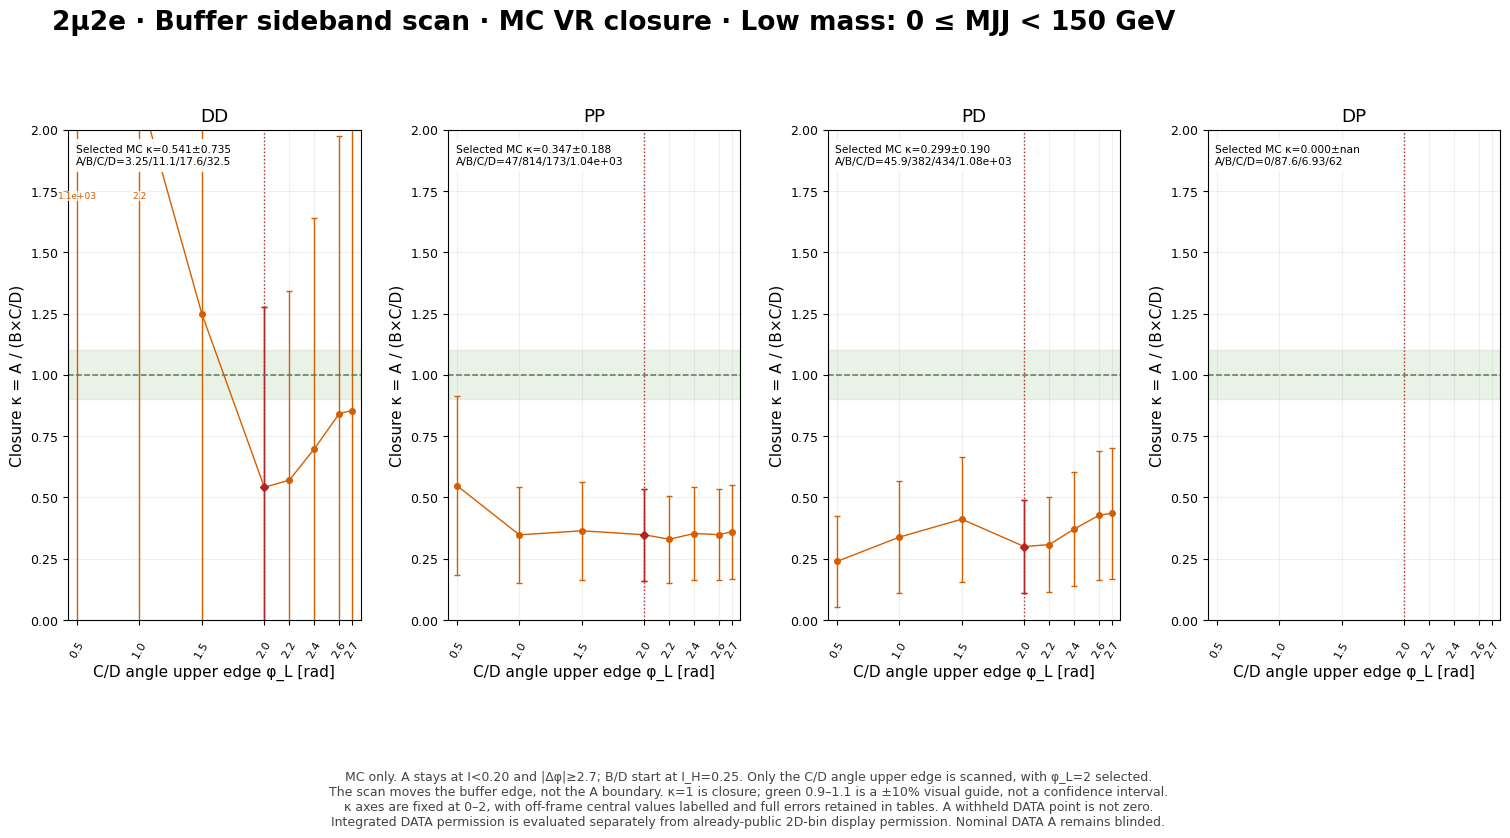

In [30]:
display(figure_lookup['gap_vr_mc_low'])


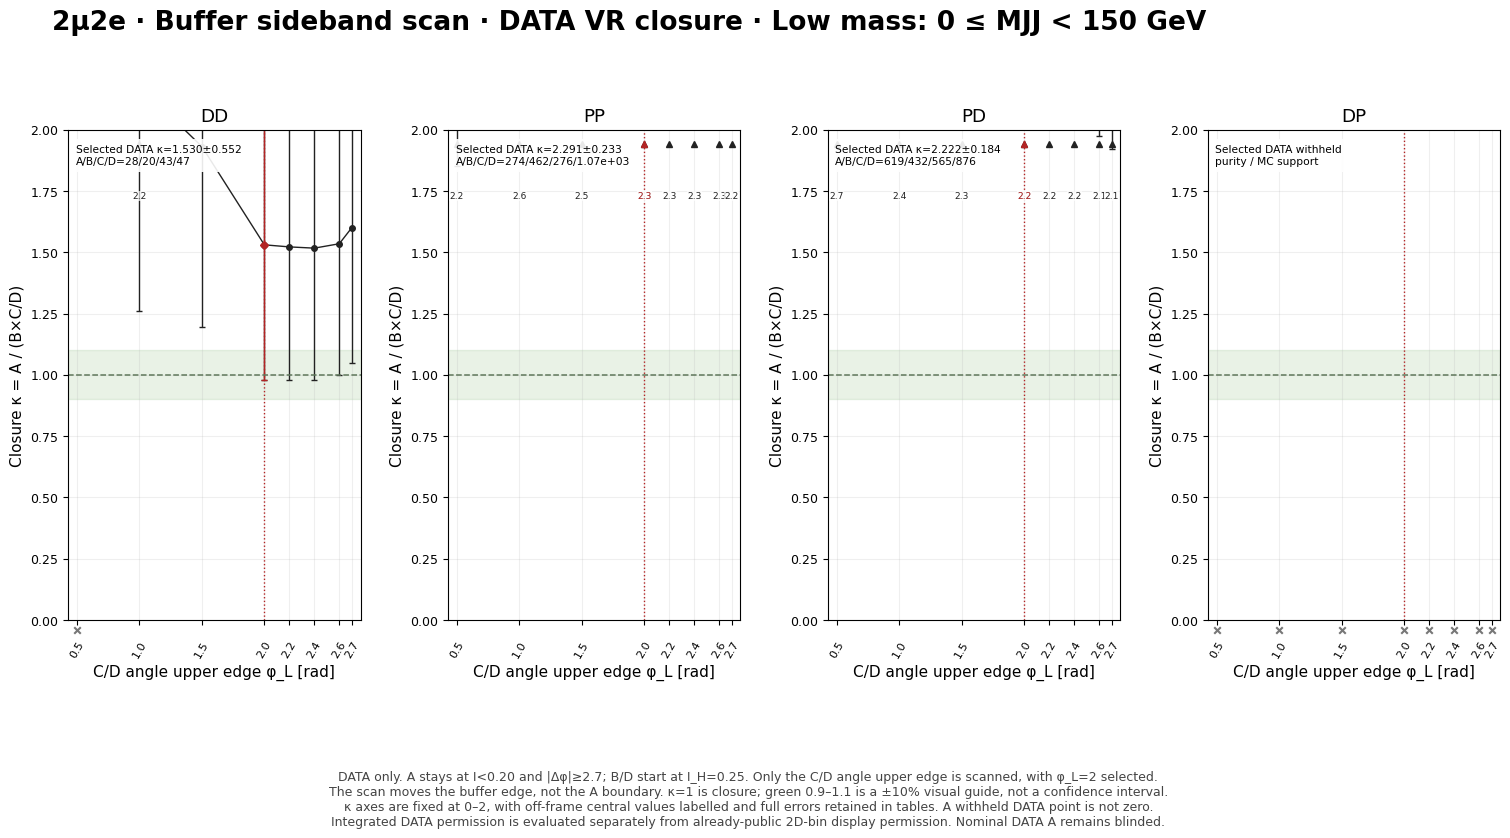

In [31]:
display(figure_lookup['gap_vr_data_low'])


### Intermediate mass: separate buffered MC and DATA VR closure

The selected buffer is marked; each scan applies identical buffer geometry to the VR. MC and DATA are on separate figures, with κ in 0–2 and the same 0.9–1.1 visual guide.


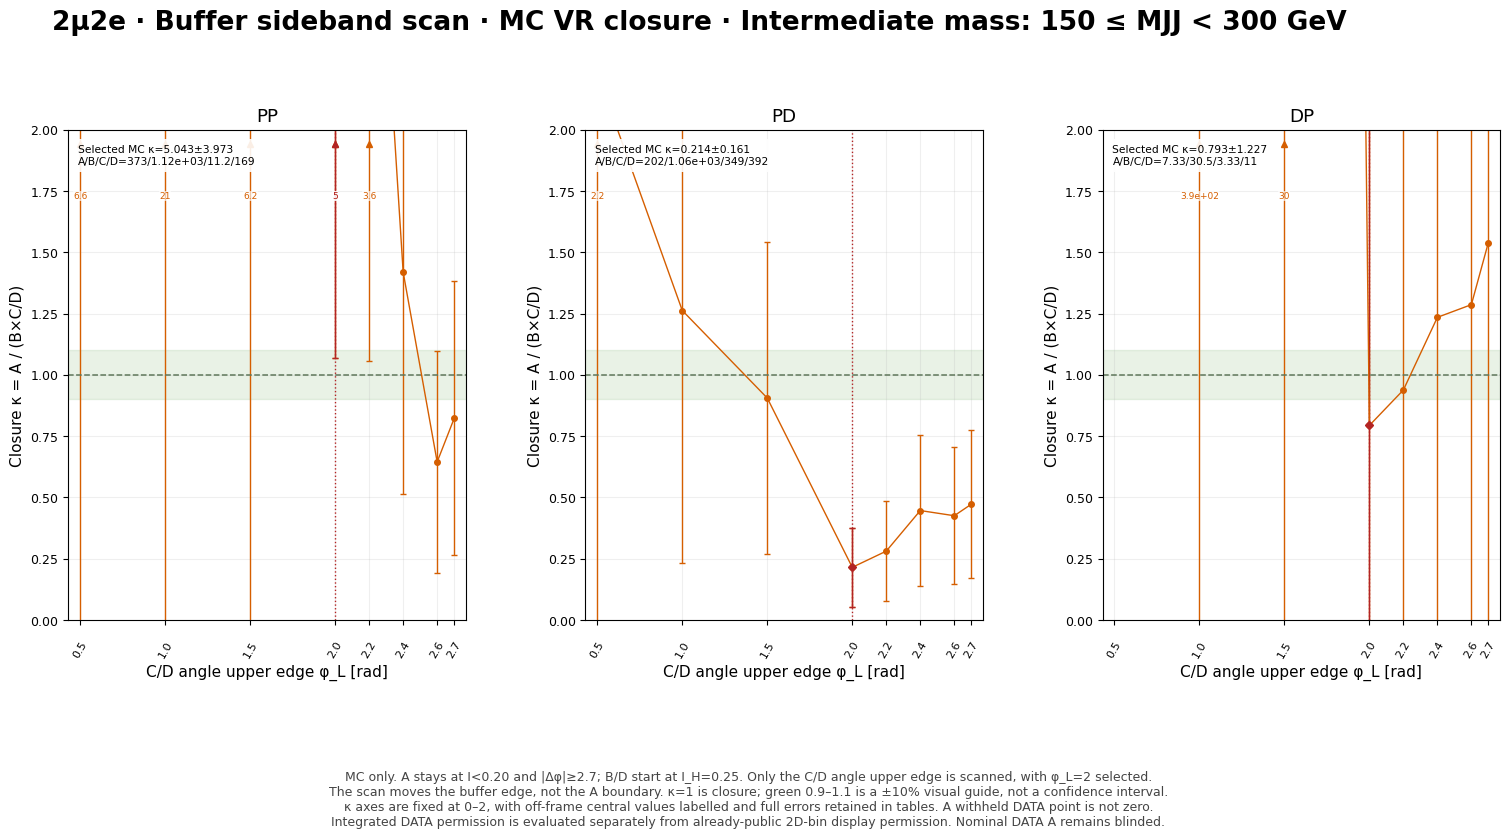

In [32]:
display(figure_lookup['gap_vr_mc_intermediate'])


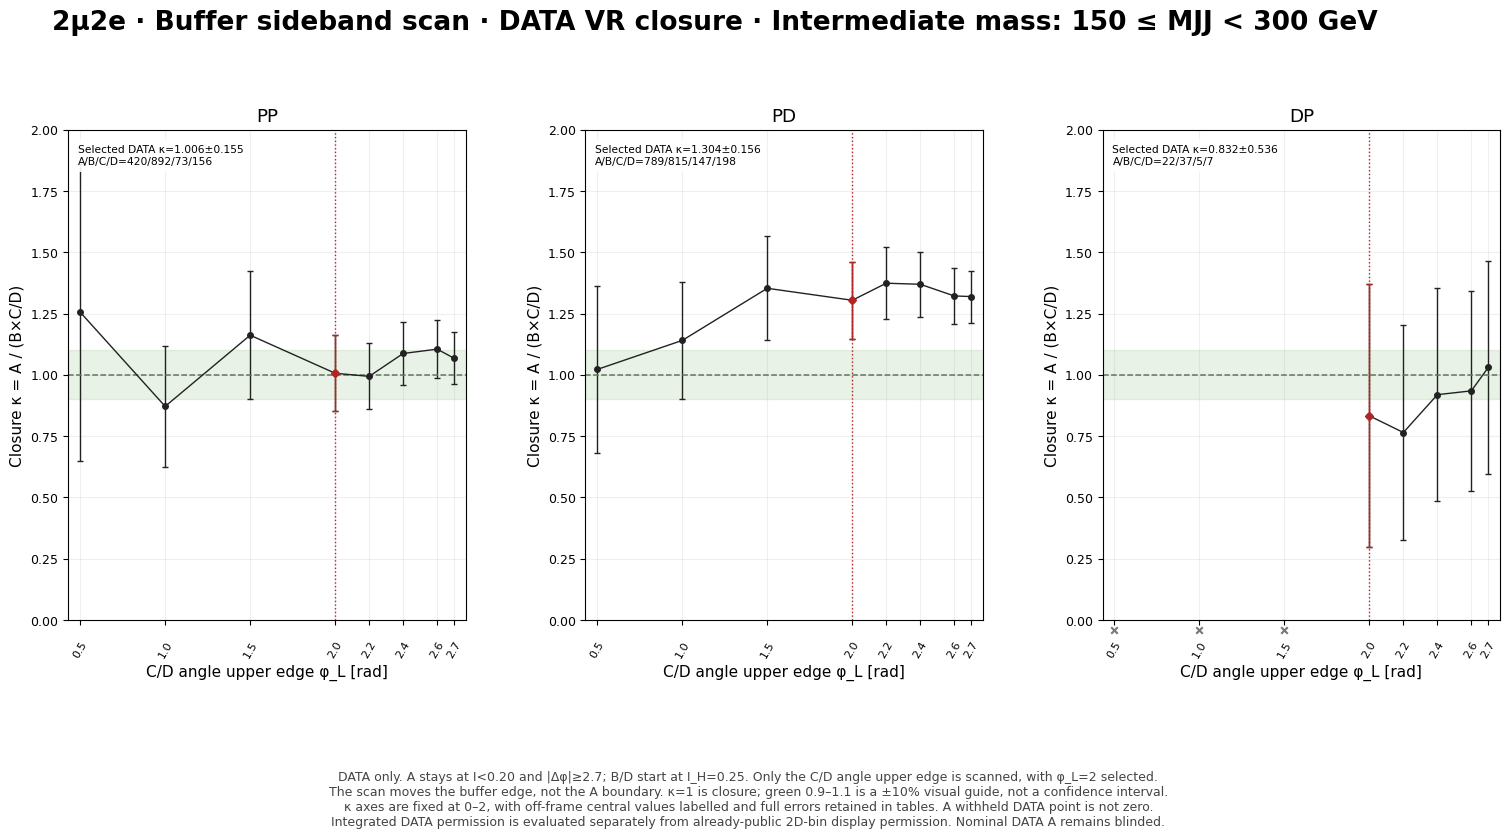

In [33]:
display(figure_lookup['gap_vr_data_intermediate'])


### Mass inclusive: separate buffered MC and DATA VR closure

The selected buffer is marked; each scan applies identical buffer geometry to the VR. MC and DATA are on separate figures, with κ in 0–2 and the same 0.9–1.1 visual guide.


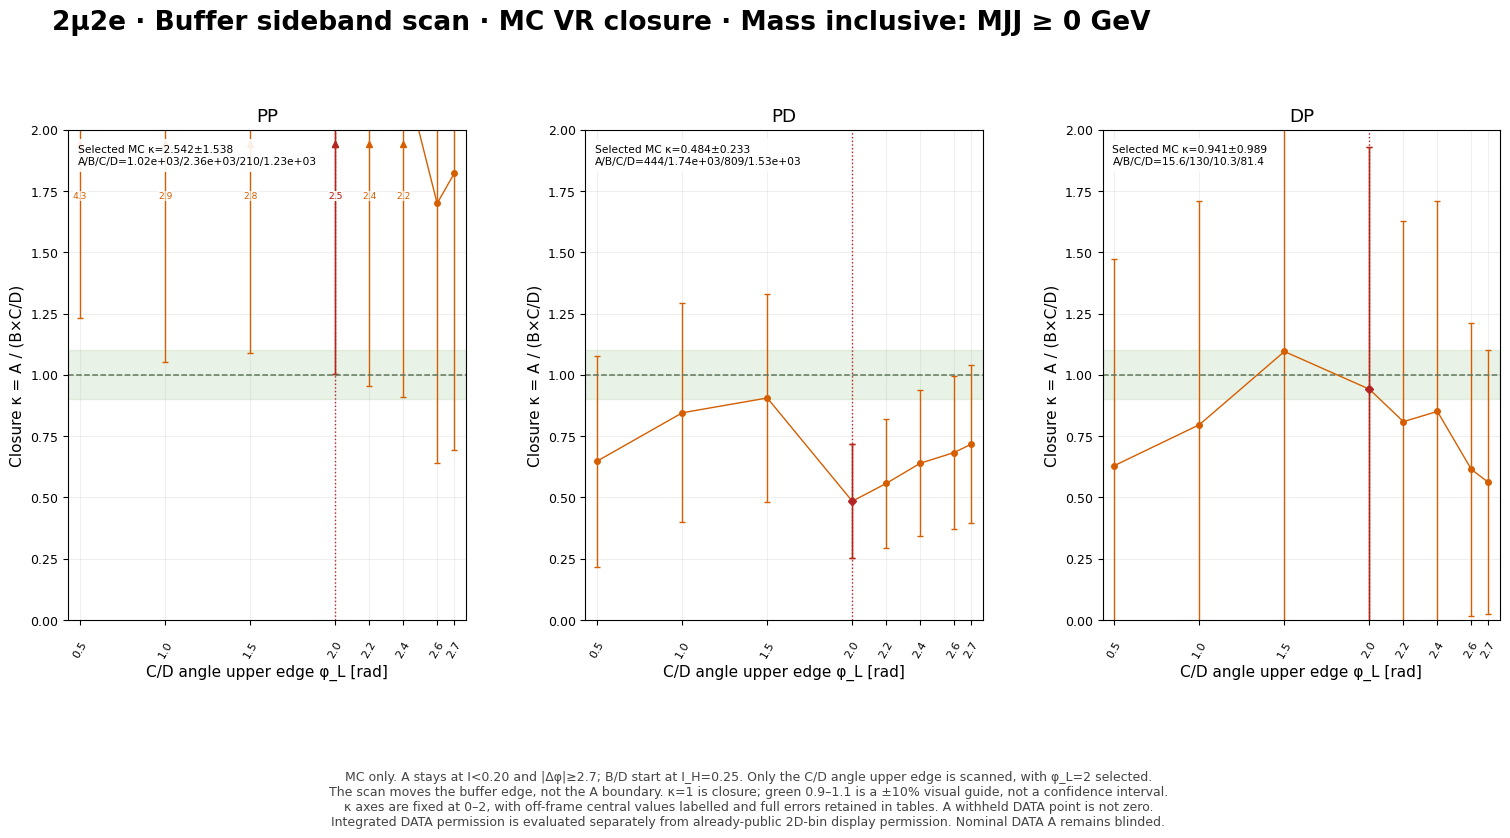

In [34]:
display(figure_lookup['gap_vr_mc_all'])


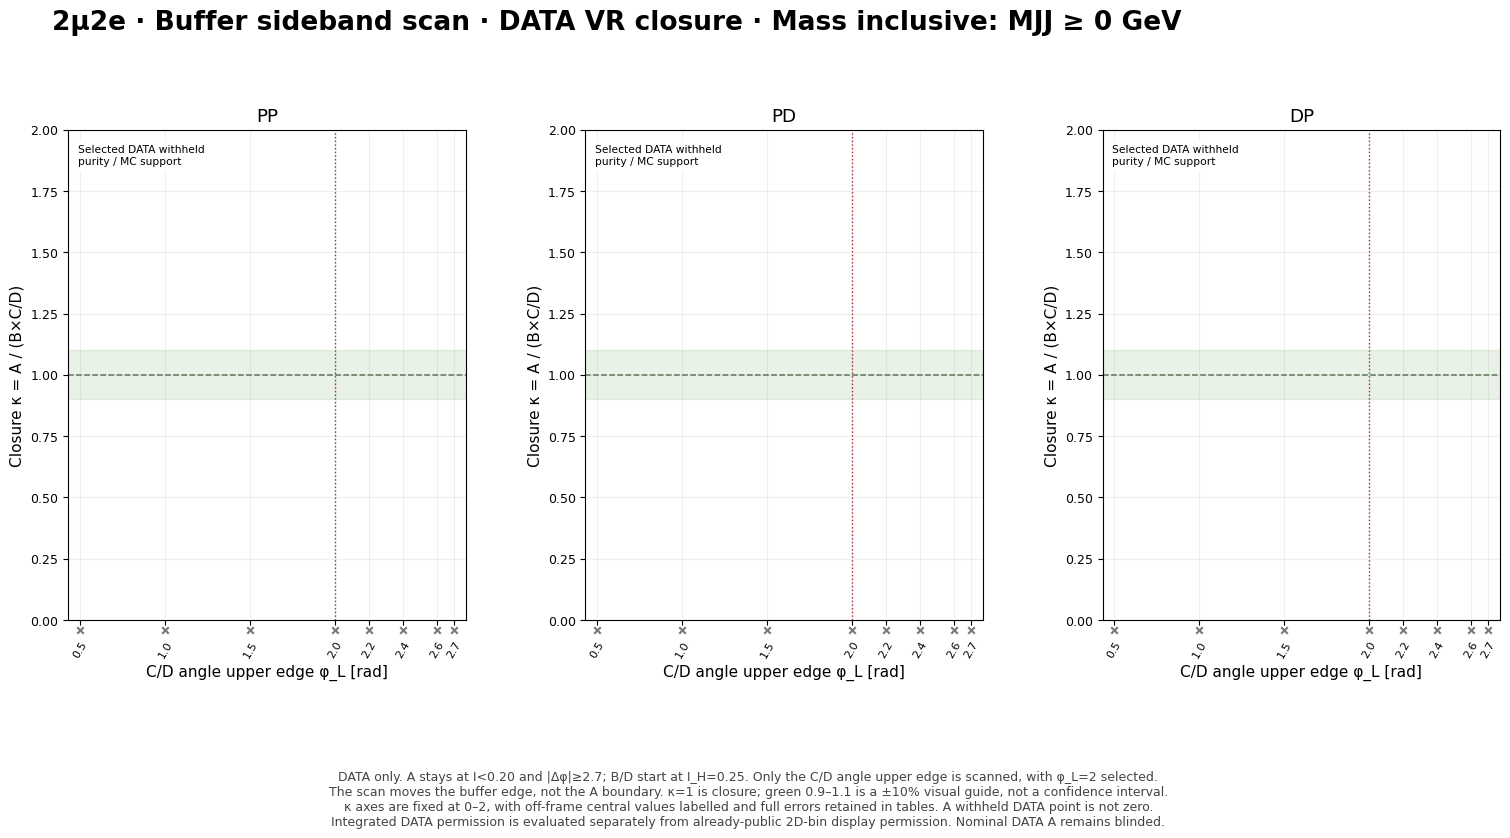

In [35]:
display(figure_lookup['gap_vr_data_all'])


### Final buffer DATA validation: fixed WP2 A, I_H=0.25 and φ_L=2.0

The final sequence mirrors the loose-boundary result: 1D DATA yield/prediction and closure scans, then separate MC and masked DATA 2D distributions for low, intermediate and inclusive mass. Amber slashes denote the excluded buffer; gray crosses denote blinded DATA bins. These are distinct concepts and may overlap.

The boundaries are overlays on the original stored bins, not new subdivisions or gap-cut rebinnings. Isolation underflow is excluded; the displayed final isolation bin [1,2] contains the physical interval [1,∞), and angular flows are folded into the edge bins. MC, signal purity and DATA use identical physical bin definitions.


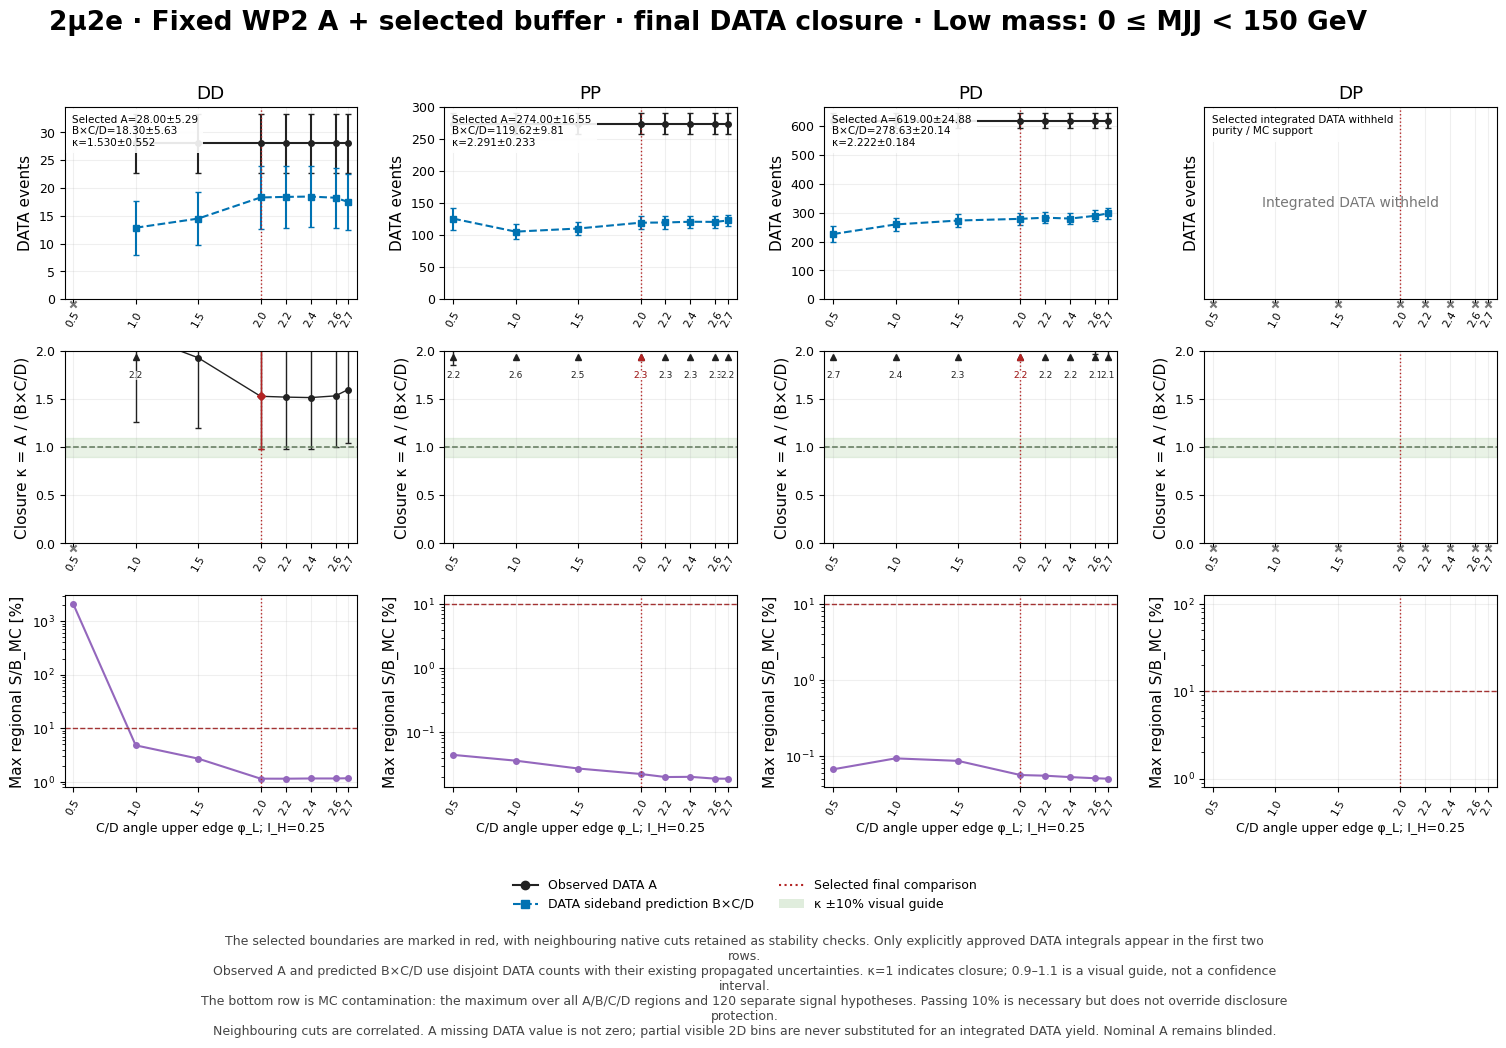

In [36]:
display(figure_lookup['buffer_final_1d_low'])


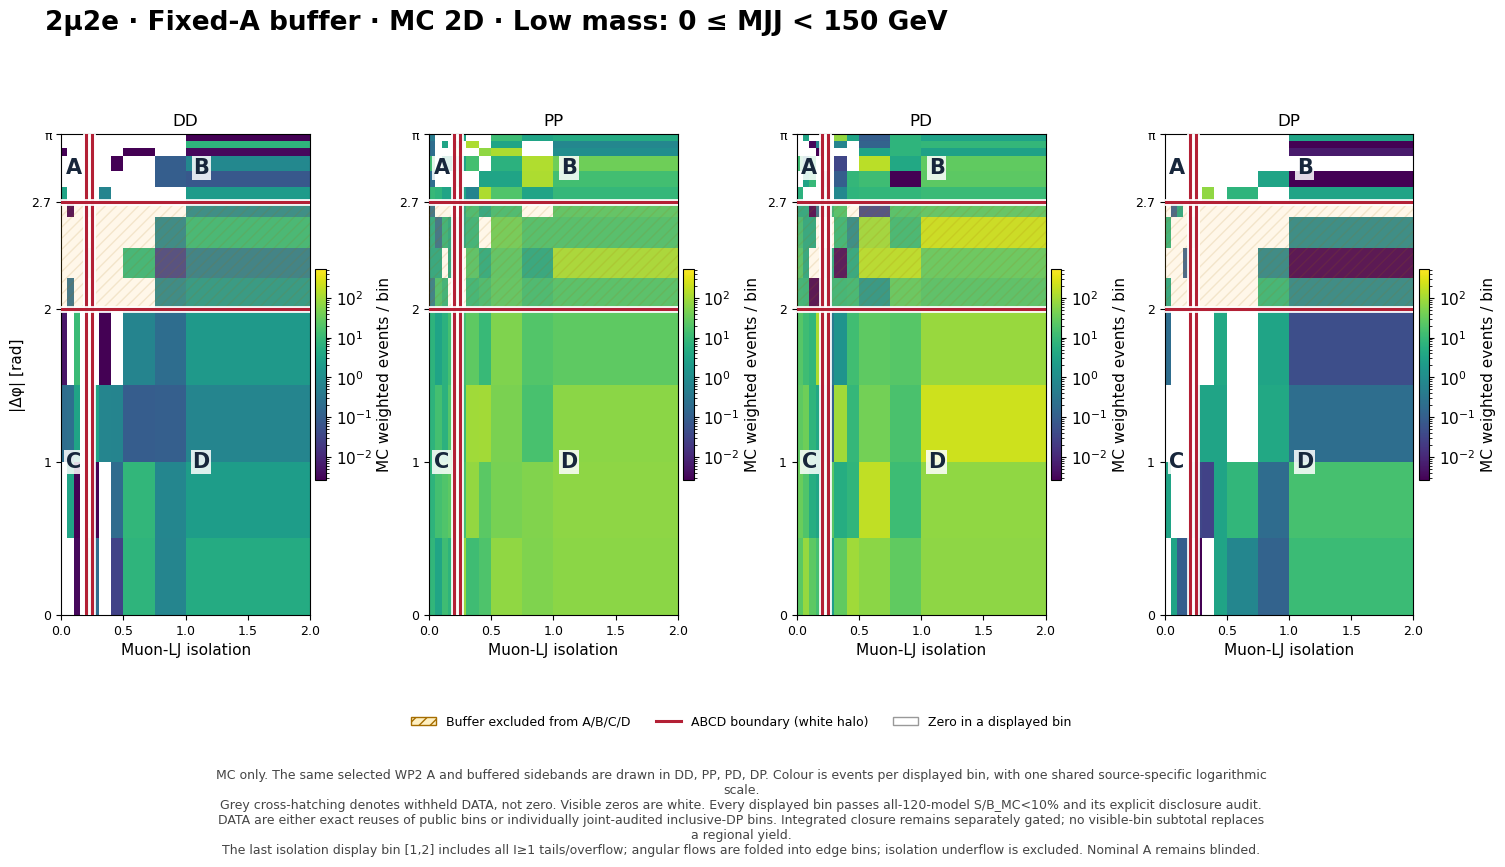

In [37]:
display(figure_lookup['buffer2d_mc_low'])


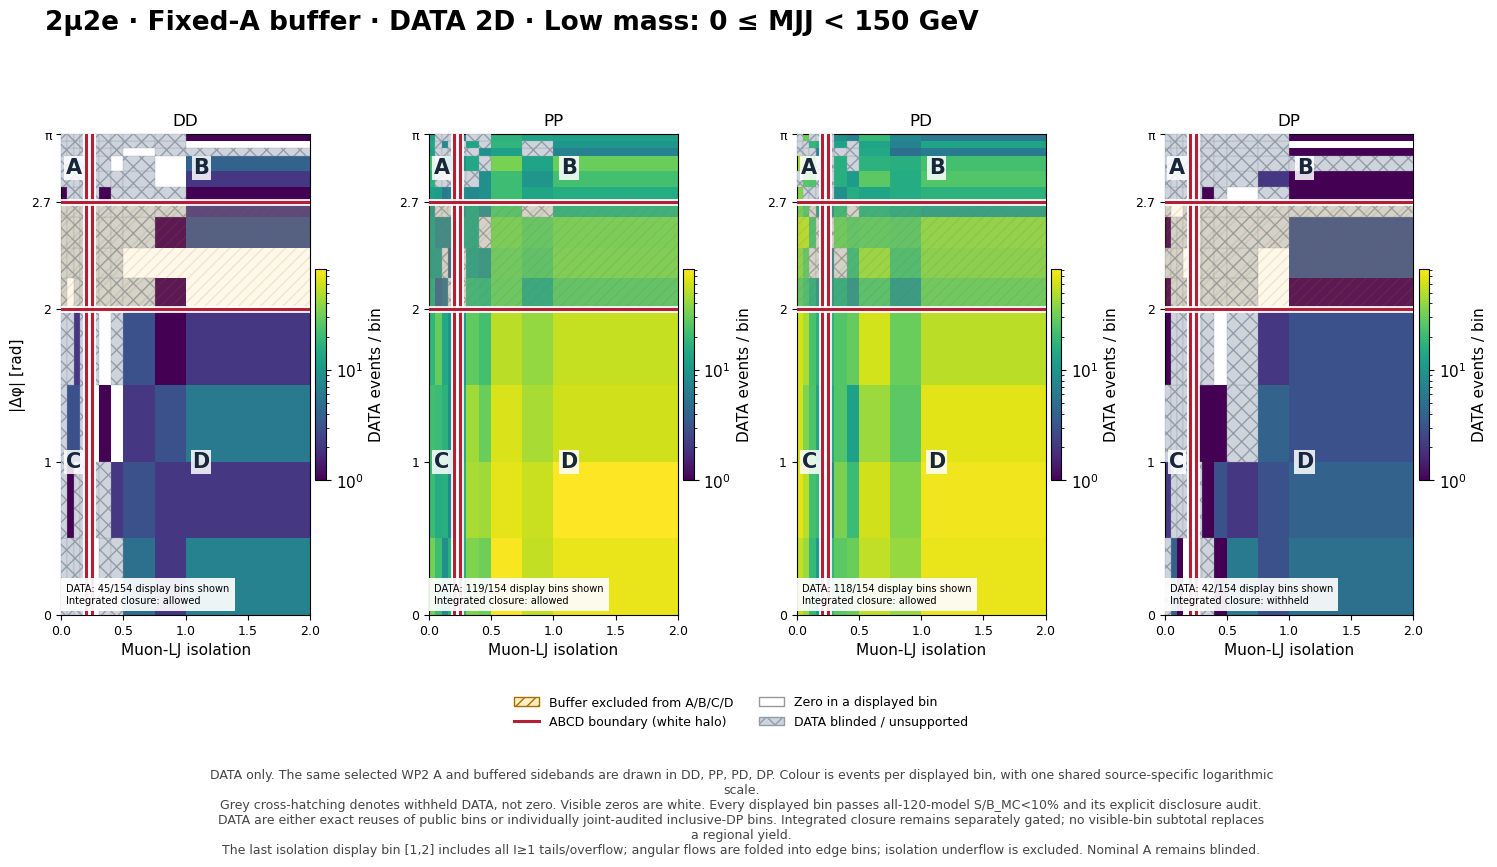

In [38]:
display(figure_lookup['buffer2d_data_low'])


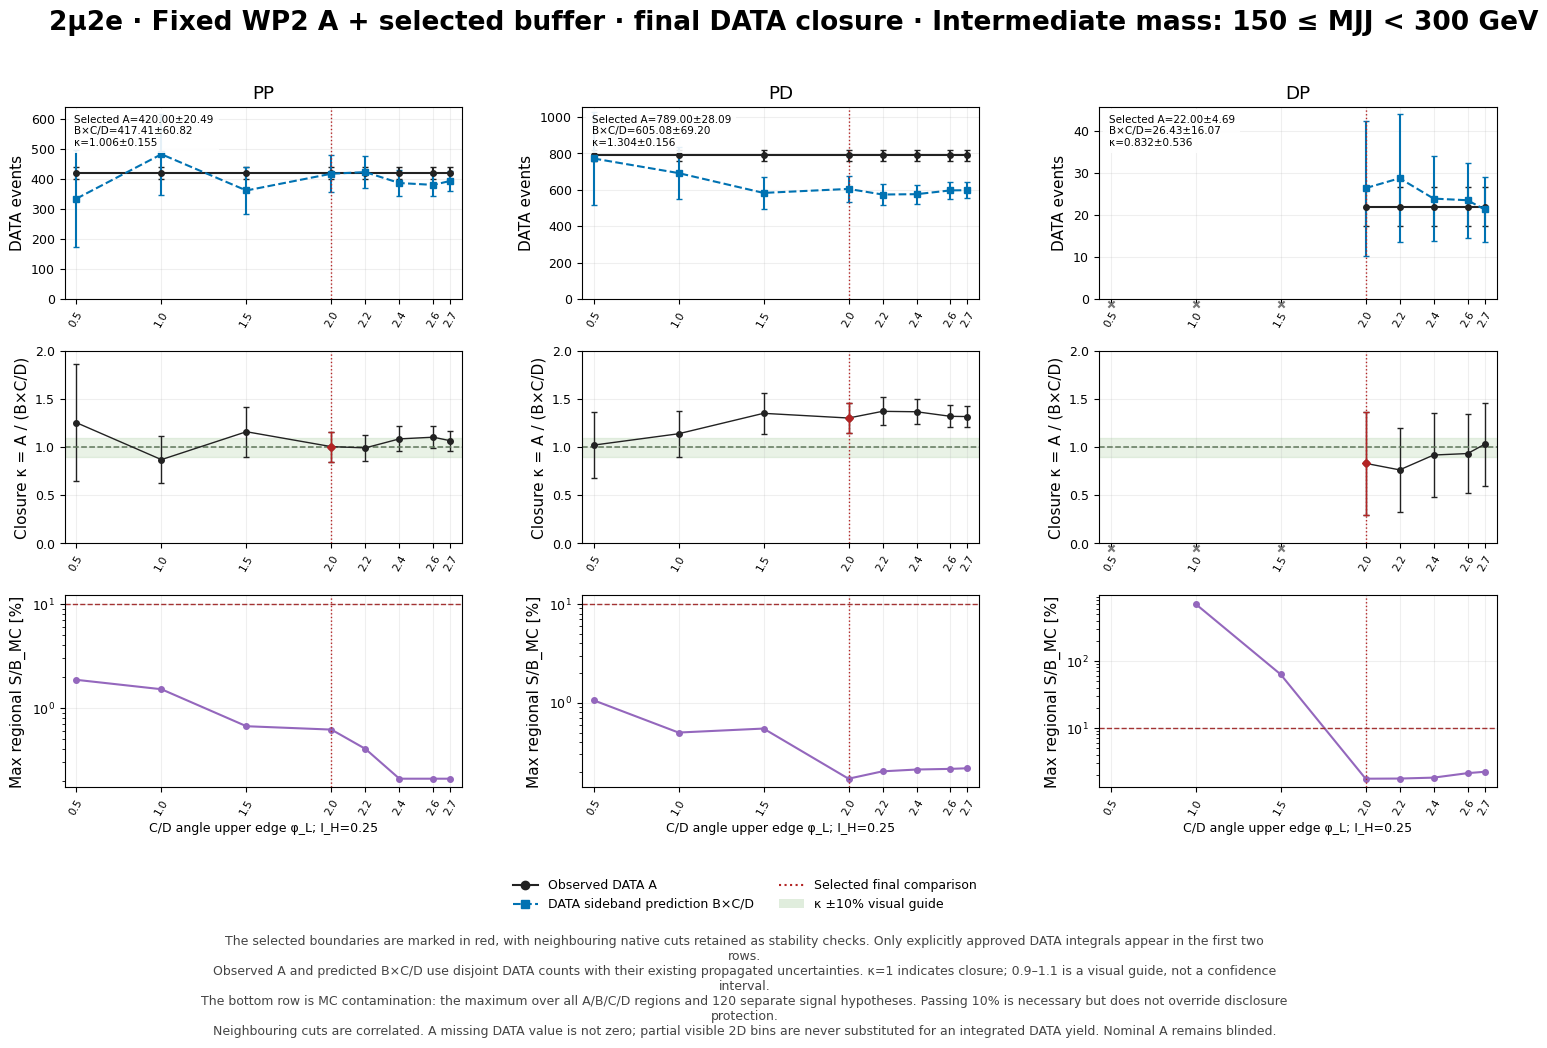

In [39]:
display(figure_lookup['buffer_final_1d_intermediate'])


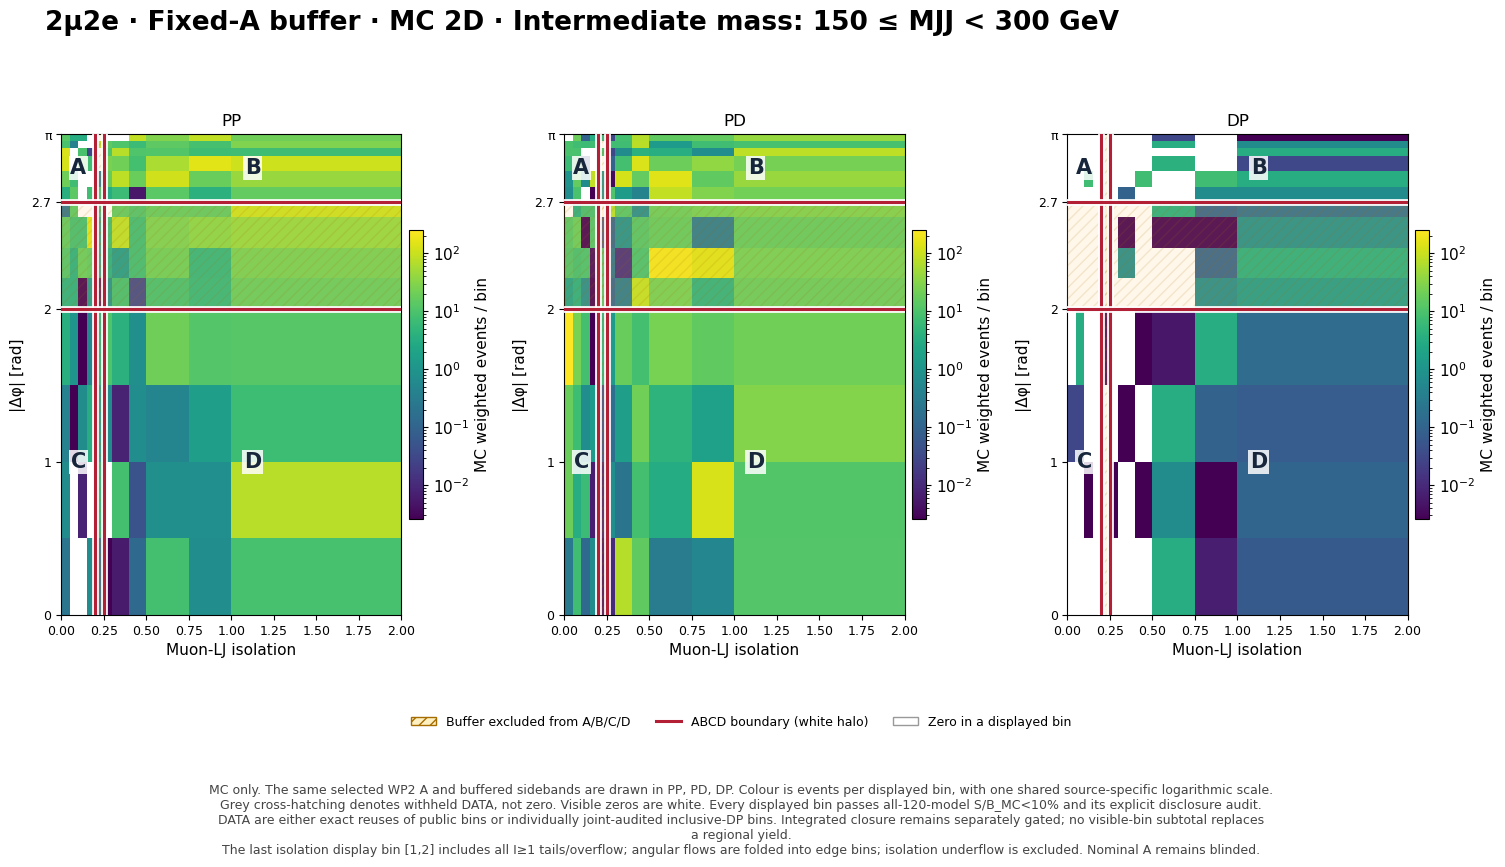

In [40]:
display(figure_lookup['buffer2d_mc_intermediate'])


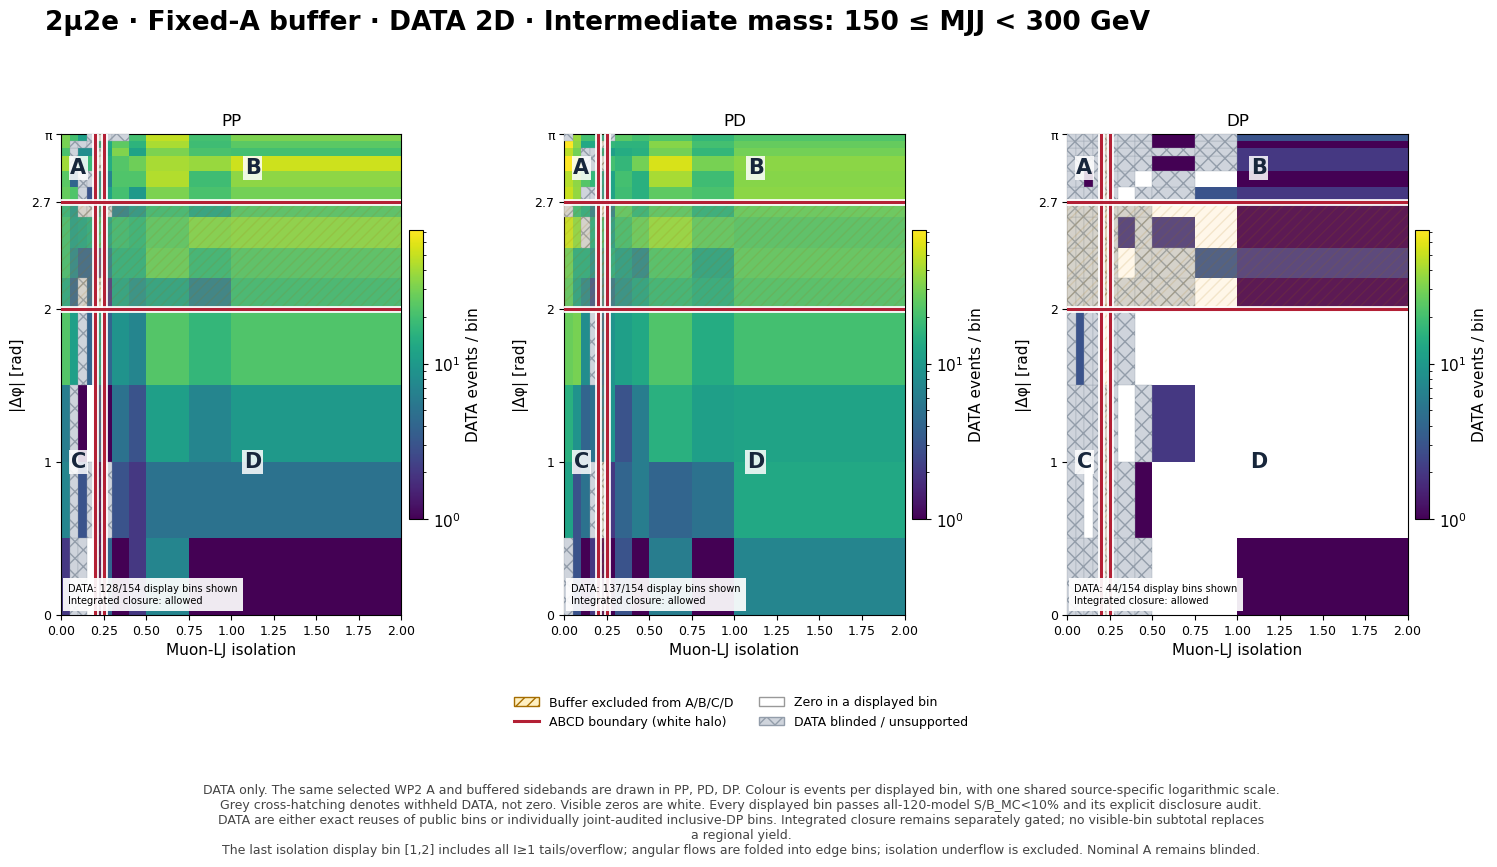

In [41]:
display(figure_lookup['buffer2d_data_intermediate'])


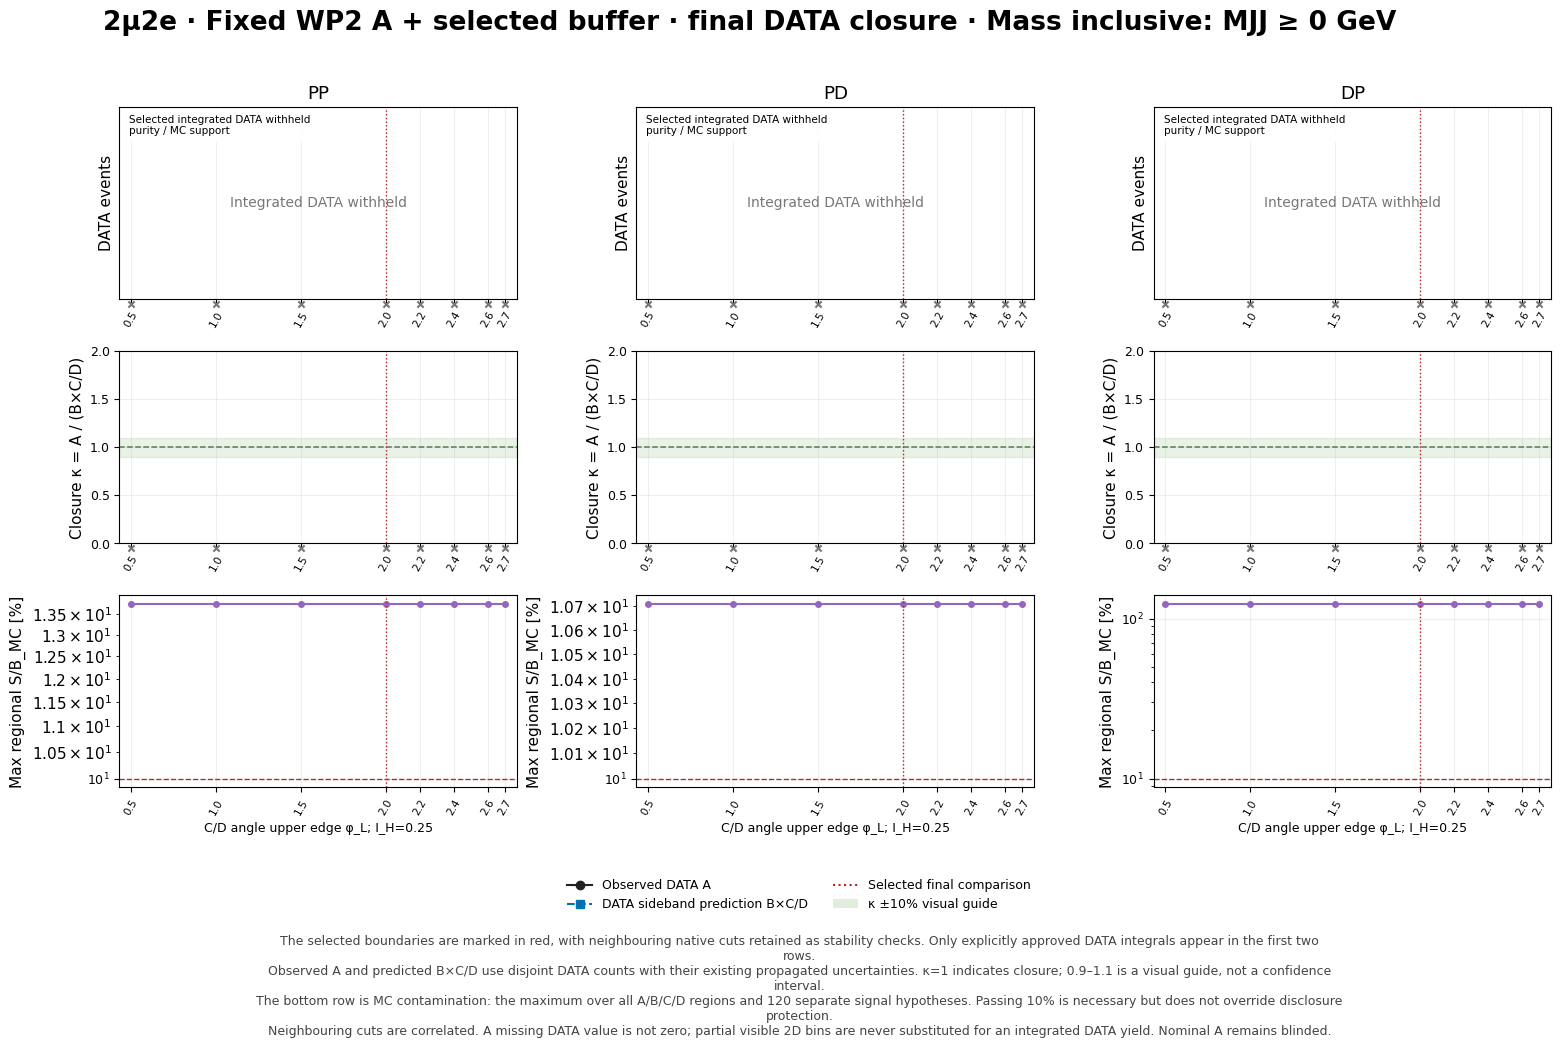

In [42]:
display(figure_lookup['buffer_final_1d_all'])


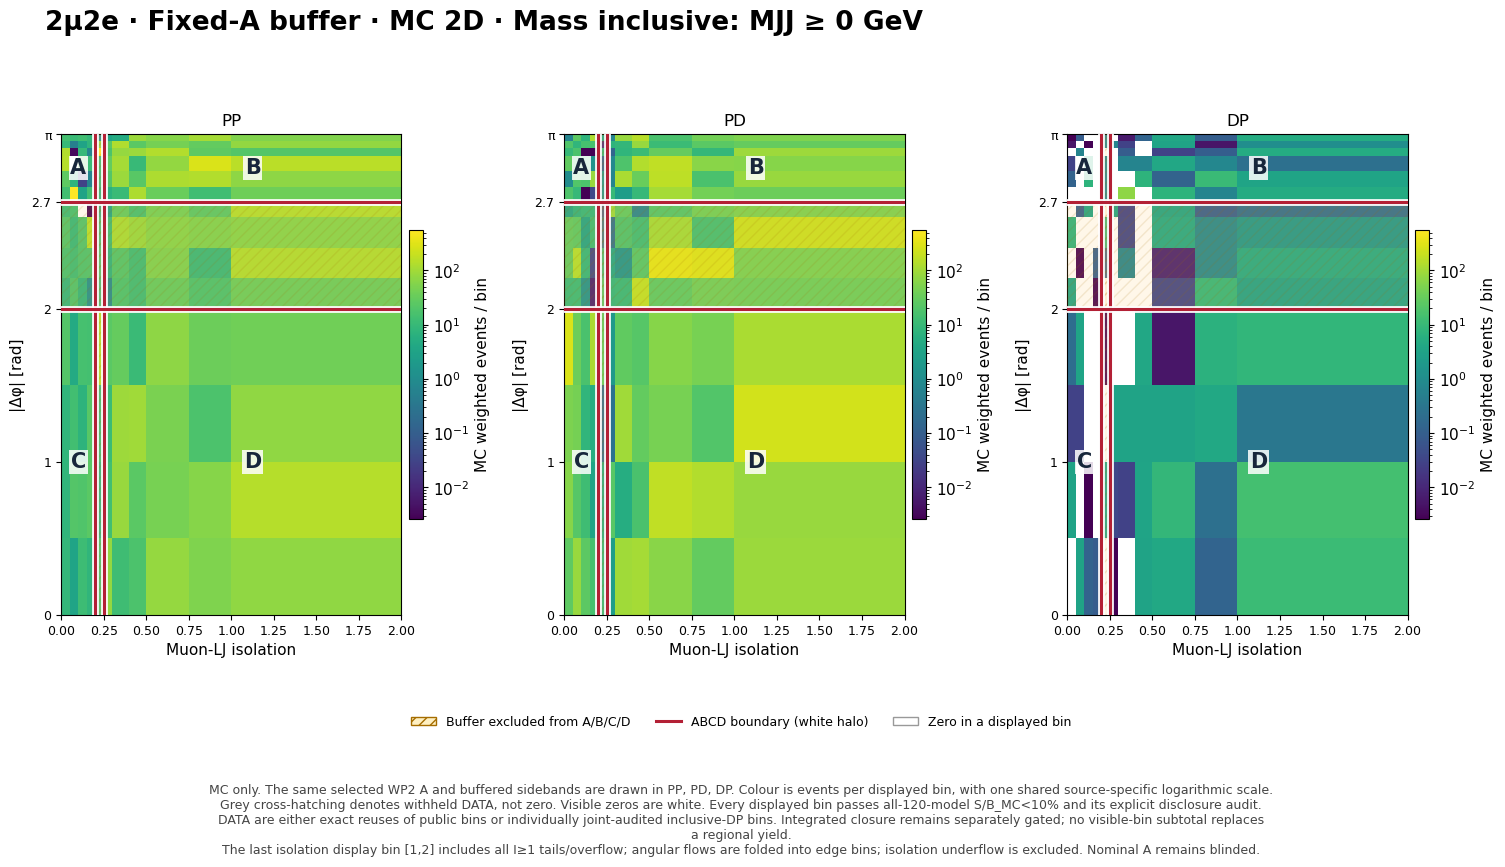

In [43]:
display(figure_lookup['buffer2d_mc_all'])


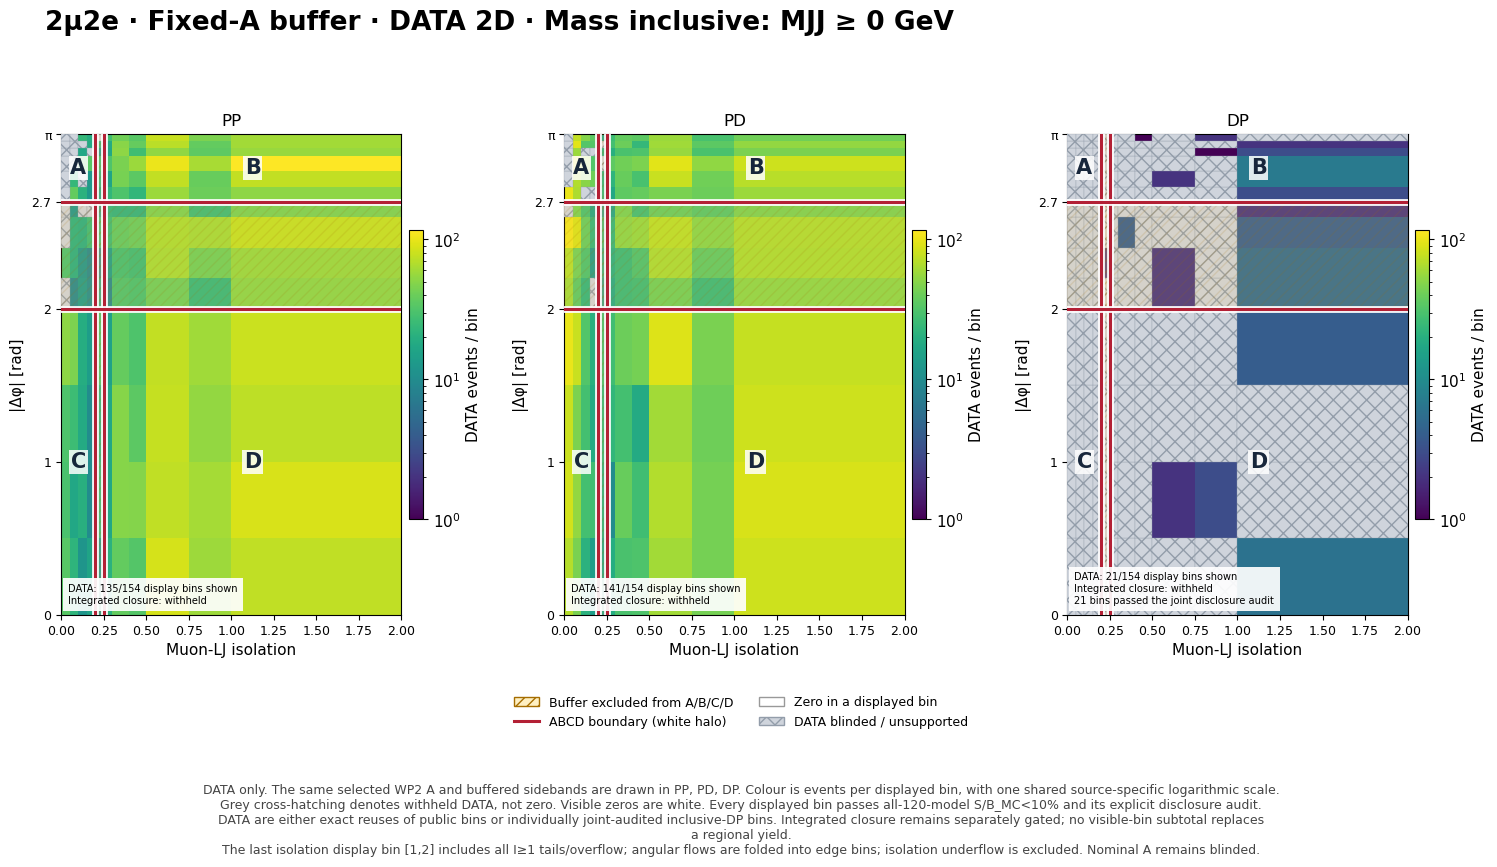

In [44]:
display(figure_lookup['buffer2d_data_all'])


In [45]:
display(Markdown('Selected buffer DATA closure:\n\n'+vr_closure_summary('gap')+
    '\n\nThe exact B/C/D rectangles are reused from previously public regional measurements after checking all four selected VR regions. Sparse/contaminated VRs remain hidden.'))


Selected buffer DATA closure:

| Mass | PP κ | PD κ | DP κ |
|---|---:|---:|---:|
| low | 2.291 ± 0.233 | 2.222 ± 0.184 | Blinded / unsupported |
| intermediate | 1.006 ± 0.155 | 1.304 ± 0.156 | 0.832 ± 0.536 |
| all | Blinded / unsupported | Blinded / unsupported | Blinded / unsupported |

The exact B/C/D rectangles are reused from previously public regional measurements after checking all four selected VR regions. Sparse/contaminated VRs remain hidden.

In [46]:
regional=tables['vd_region_purity'].query("mass_slice == 'all'")
lines=['## 4. Inclusive cross-check: regional purity versus visible bins','',
    '| Definition | PP A S/B | PD A S/B | DP A S/B | B/C/D pass |',
    '|---|---:|---:|---:|---|']
for study,label in [('loose','Loose (0.25,2.6)'),('gap','Fixed-WP2 A + buffer')]:
    frame=regional.loc[regional.study.eq(study)]
    values=[float(frame.loc[frame.scope.eq('INCLUSIVE_'+p)&frame.region.eq('A'),'max_S_B'].iloc[0]) for p in ['PP','PD','DP']]
    controls=bool(frame.loc[frame.region.isin(list('BCD')),'purity_pass'].all())
    lines.append('| '+label+' | '+' | '.join(f'{100*v:.2f}%' for v in values)+' | '+str(controls)+' |')
lines+=['','Complete DATA κ is displayed only when the selected ABCD definition passes the regional gate and exact measurements are available. A masked selected closure does not imply that every 2D bin is unsafe.',
    '', 'The unchanged bin-level test and audited inclusive-DP subset remain in force. No partial visible-bin sum is used as a complete regional yield; no nominal DATA A is queried.']
display(Markdown('\n'.join(lines)))


## 4. Inclusive cross-check: regional purity versus visible bins

| Definition | PP A S/B | PD A S/B | DP A S/B | B/C/D pass |
|---|---:|---:|---:|---|
| Loose (0.25,2.6) | 8.50% | 10.05% | 88.11% | True |
| Fixed-WP2 A + buffer | 13.75% | 10.71% | 123.34% | True |

Complete DATA κ is displayed only when the selected ABCD definition passes the regional gate and exact measurements are available. A masked selected closure does not imply that every 2D bin is unsafe.

The unchanged bin-level test and audited inclusive-DP subset remain in force. No partial visible-bin sum is used as a complete regional yield; no nominal DATA A is queried.

In [47]:
with pd.option_context('display.max_columns',None,'display.max_colwidth',90):
    display(tables['vd_region_purity'].query("mass_slice == 'all'")[
        ['study','scope','region','background','max_S_B','purity_pass','closure_gate','closure_gate_reason']])
    display(tables['vd_scope_audit'].query("mass_slice == 'all'")[
        ['study','scope','passing_ABCD_regions','bin_purity_pass','eligible_bins','displayed_bins','newly_audited_bins',
         'closure_gate','closure_gate_reason']])
    display(tables['dp_bin_audit'].groupby(['accepted','reason']).size().rename('bins').reset_index())


,study,scope,region,background,max_S_B,purity_pass,closure_gate,closure_gate_reason
32,loose,INCLUSIVE_PP,A,1692.5,0.084984,True,True,PREVIOUSLY_PUBLIC_NATIVE_GRID_07_EXACT_REUSE
33,loose,INCLUSIVE_PP,B,2588,0.00043017,True,True,PREVIOUSLY_PUBLIC_NATIVE_GRID_07_EXACT_REUSE
34,loose,INCLUSIVE_PP,C,683.64,0.0091329,True,True,PREVIOUSLY_PUBLIC_NATIVE_GRID_07_EXACT_REUSE
35,loose,INCLUSIVE_PP,D,1902.5,2.7106e-05,True,True,PREVIOUSLY_PUBLIC_NATIVE_GRID_07_EXACT_REUSE
36,loose,INCLUSIVE_PD,A,483.21,0.10055,False,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
37,loose,INCLUSIVE_PD,B,1949.9,0.00014064,True,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
38,loose,INCLUSIVE_PD,C,1115.5,0.0017846,True,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
39,loose,INCLUSIVE_PD,D,2819.7,8.4166e-06,True,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
40,loose,INCLUSIVE_DP,A,22.262,0.88113,False,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
41,loose,INCLUSIVE_DP,B,137.27,0.00045444,True,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND


,study,scope,passing_ABCD_regions,bin_purity_pass,eligible_bins,displayed_bins,newly_audited_bins,closure_gate,closure_gate_reason
8,loose,INCLUSIVE_PP,4,135,135,135,0,True,PREVIOUSLY_PUBLIC_NATIVE_GRID_07_EXACT_REUSE
9,loose,INCLUSIVE_PD,3,141,141,141,0,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
10,loose,INCLUSIVE_DP,3,77,21,21,21,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
19,gap,INCLUSIVE_PP,3,135,135,135,0,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
20,gap,INCLUSIVE_PD,3,141,141,141,0,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND
21,gap,INCLUSIVE_DP,3,77,21,21,21,False,VR_CONTAMINATION_OR_INVALID_BACKGROUND


,accepted,reason,bins
0,False,UNSAFE_JOINT_COMPLEMENT,18
1,False,UNSAFE_NATIVE_RECTANGLE_MASS_COMPLEMENT,38
2,True,PASS_NATIVE_RECTANGLE_MASS_AND_JOINT_COMPLEMENT_AUDITS,21


## 5. Final comparison: MC contamination, control counts and VR validation

Both finalists were fixed using nominal MC. Contamination below means the maximum **S/B_MC over 120 separate signal hypotheses** in B/C/D. The observed nominal B/C/D counts and their B×C/D prediction are reported separately.

The intermediate-mass overlay compares PP/PD/DP DATA yields, closure and maximum MC contamination on a common isolation axis. For loose boundaries this axis moves I_A; for the buffer it moves I_H while A remains fixed. Both selected isolation edges are 0.25.

The significance comparison uses absolute per-hypothesis S/√(S+B), known-background Z and finite-MC Z from nominal MC A. It uses the same 60 matching signal hypotheses for both approaches. Raw B×C/D errors include counting statistics only; nominal DATA A remains blinded.


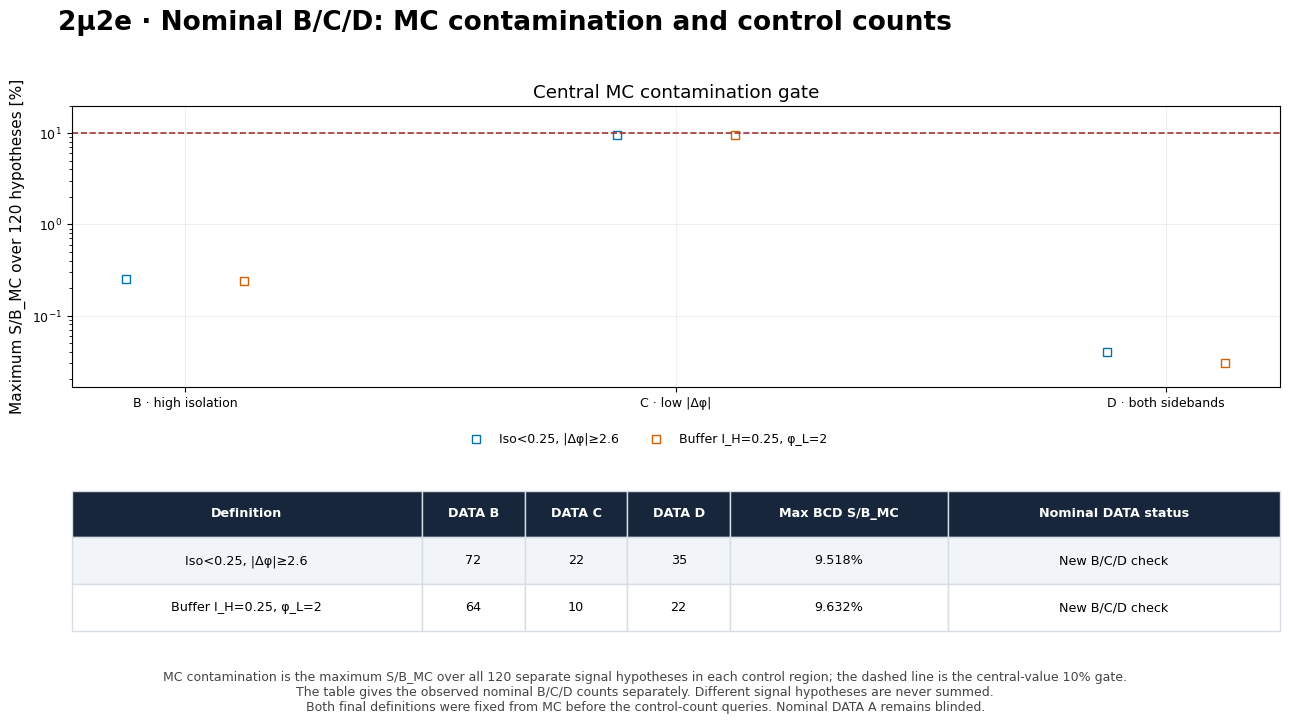

In [48]:
display(figure_lookup['if_nominal_data_contamination'])


In [49]:
fractions=tables['if_nominal_data_contamination']
final_ids=[loose.candidate_id,buffer_spec['candidate_id']]
with pd.option_context('display.max_columns',None):
    display(fractions.loc[fractions.candidate_id.isin(final_ids),
        ['candidate_id','region','data_count','max_S_B_MC','mc_purity_pass','data_available']])
    display(tables['sbd_summary'].loc[tables['sbd_summary'].candidate_id.isin(
        [loose.source_candidate_id,buffer_spec['candidate_id']]),
        ['candidate_id','data_B','data_C','data_D','pred','pred_error']])


,candidate_id,region,data_count,max_S_B_MC,mc_purity_pass,data_available
9,G_i0p25_p2,B,64,0.0023993,True,True
10,G_i0p25_p2,C,10,0.096322,True,True
11,G_i0p25_p2,D,22,0.00029997,True,True
15,I_i0p25_p2p6,B,72,0.0025178,True,True
16,I_i0p25_p2p6,C,22,0.095178,True,True
17,I_i0p25_p2p6,D,35,0.00040076,True,True


,candidate_id,data_B,data_C,data_D,pred,pred_error
6,L_i0p25_p2p6,72,22,35,45.257,13.419
7,G_i0p25_p2,64,10,22,29.091,11.676


### Intermediate mass: overlaid loose and buffer scans

Columns are PP/PD/DP; rows are DATA yields, κ and maximum regional MC contamination. The common x coordinate is the loose A isolation edge I_A or the buffer B/D isolation edge I_H. Loose A changes along its scan; buffer A is fixed. Their different A yields do not by themselves indicate a closure difference. The selected edge 0.25 is marked for both approaches.


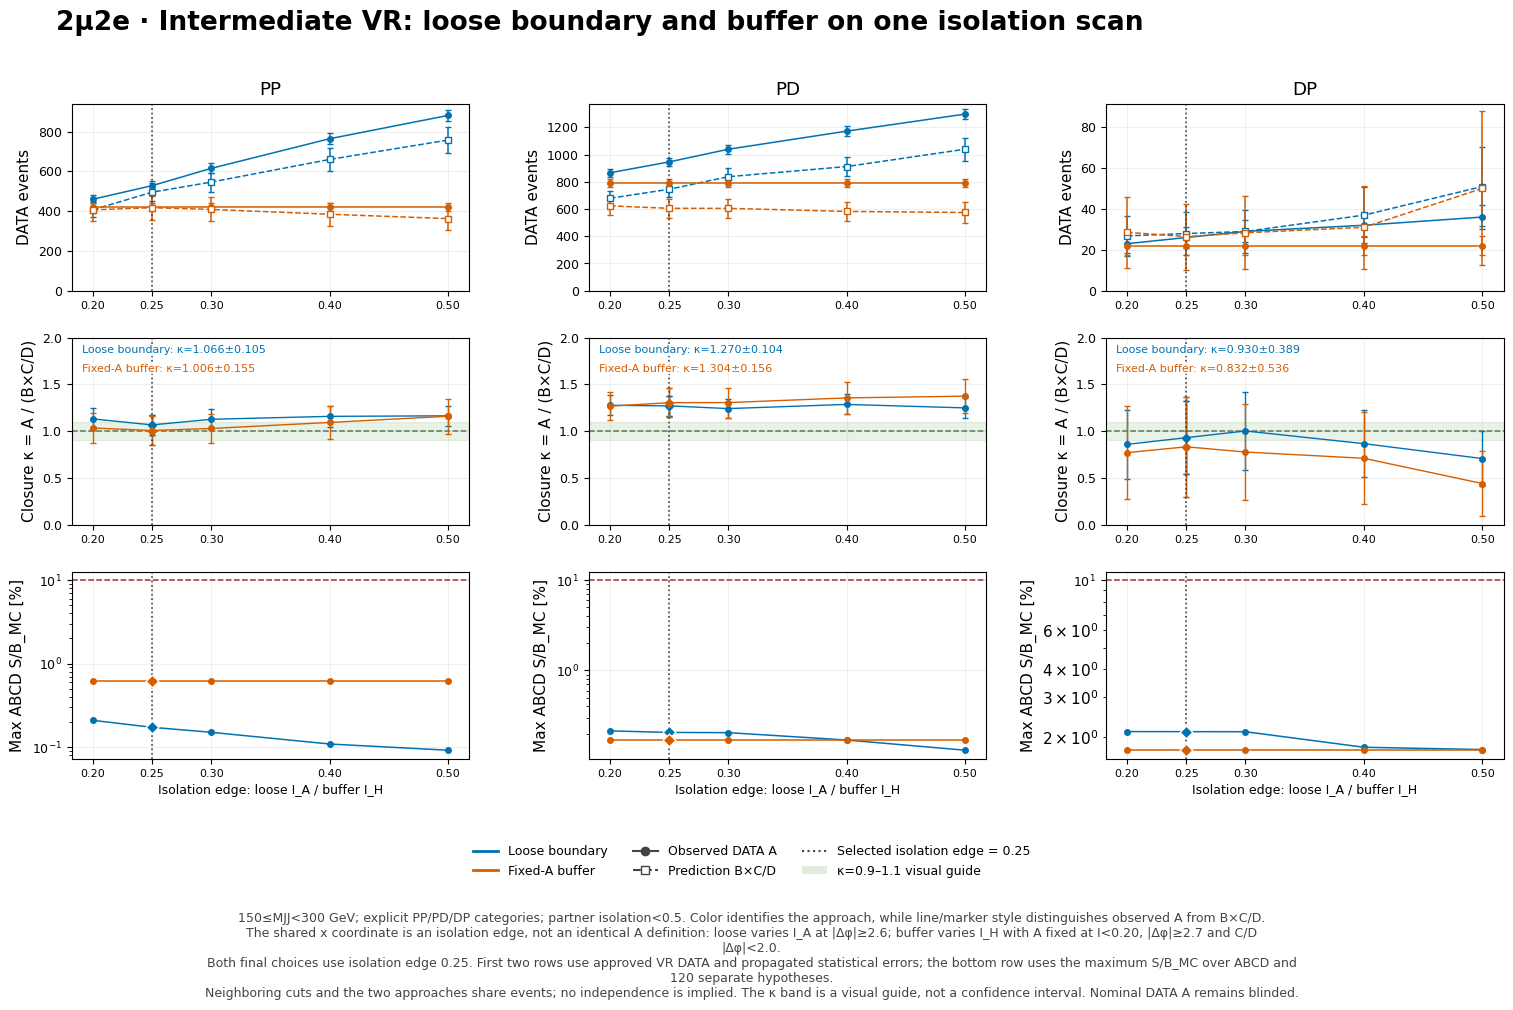

In [50]:
display(figure_lookup['final_intermediate_overlay'])

### Final nominal MC significance: identical signal hypotheses

Both approaches are compared model by model with absolute S/√(S+B), known-background Z and finite-MC Z. Signal hypotheses are ordered by parent mass, daughter mass and lifetime; they are never summed. The model-index mapping and exact plotted values are exported in `final_comparison_signals.csv`.


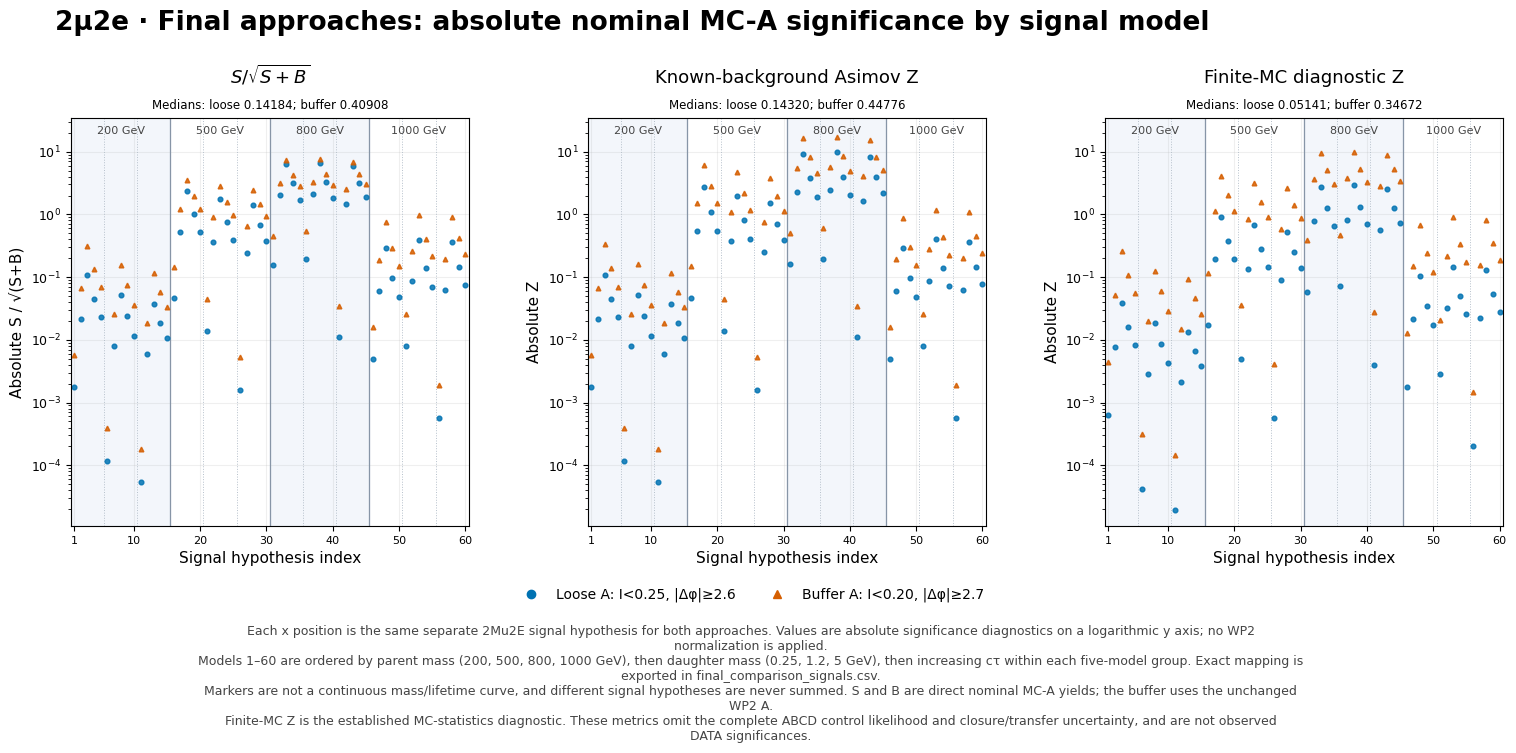

In [51]:
display(figure_lookup['final_significance_comparison'])

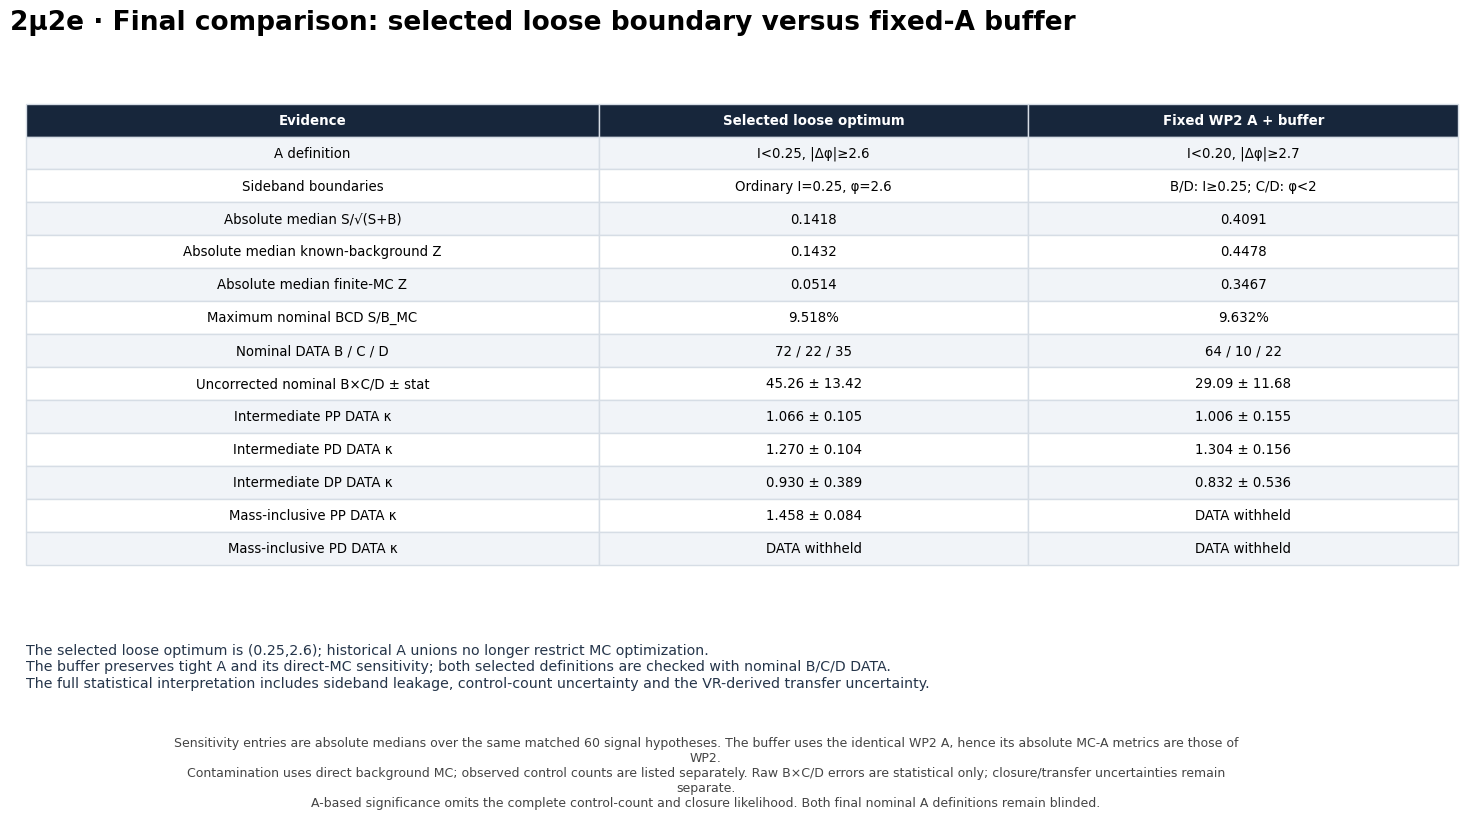

In [52]:
display(figure_lookup['if_meeting_comparison'])


In [53]:
summary_lines=['### Final comparison evidence','',
    '| Evidence | Optimized loose (0.25,2.6) | Fixed WP2 A + buffer (0.25,2.0) |','|---|---|---|']
control_index=tables['sbd_summary'].set_index('candidate_id')
lc=control_index.loc[loose.source_candidate_id];gc=control_index.loc[buffer_spec['candidate_id']]
lf=fractions.loc[fractions.candidate_id.eq(loose.candidate_id)]
gf=fractions.loc[fractions.candidate_id.eq(buffer_spec['candidate_id'])]
wp2=tables['if_scan'].set_index('candidate_id').loc['I_i0p2_p2p7']
for label,left,right in [
    ('Absolute median S/sqrt(S+B)',f'{loose.s_sqrt_s_plus_b_median:.5f}',f'{wp2.s_sqrt_s_plus_b_median:.5f}'),
    ('Absolute median known-background Z',f'{loose.z_known_b_median:.5f}',f'{wp2.z_known_b_median:.5f}'),
    ('Absolute median finite-MC Z',f'{loose.z_mc_stat_diagnostic_median:.5f}',f'{wp2.z_mc_stat_diagnostic_median:.5f}'),
    ('Nominal DATA B/C/D',' / '.join(str(int(lc['data_'+r])) for r in 'BCD'),' / '.join(str(int(gc['data_'+r])) for r in 'BCD')),
    ('Raw DATA B×C/D (stat only)',f'{lc.pred:.2f} ± {lc.pred_error:.2f}',f'{gc.pred:.2f} ± {gc.pred_error:.2f}'),
    ('Maximum BCD S/B_MC',f'{100*lf.max_S_B_MC.max():.2f}%',f'{100*gf.max_S_B_MC.max():.2f}%'),
    ('Intermediate PP DATA κ',vr_closure_text('loose','intermediate','PP'),vr_closure_text('gap','intermediate','PP')),
    ('Intermediate PD DATA κ',vr_closure_text('loose','intermediate','PD'),vr_closure_text('gap','intermediate','PD')),
    ('Intermediate DP DATA κ',vr_closure_text('loose','intermediate','DP'),vr_closure_text('gap','intermediate','DP'))]:
    summary_lines.append(f'| {label} | {left} | {right} |')
summary_lines+=['', '**Loose advantages:** ordinary four-region geometry; maximum absolute MC-A score among the contamination-passing ordinary scan points; larger nominal control samples for these final definitions.',
    '', '**Loose limitations:** lower tight-A sensitivity than the buffer; central MC contamination close to 10%; residual VR nonclosure and sparse nominal background MC.',
    '', '**Buffer advantages:** retains the tight WP2 A and its higher direct-MC sensitivity; intermediate PP closure is near unity, with sideband counts sufficient for a finite prediction.',
    '', '**Buffer limitations:** gap-dependent factorization needs VR validation; sparse C MC, limited C DATA and residual PD/low-mass nonclosure remain.',
    '', '**Interpretation:** the buffer has the stronger nominal MC-A sensitivity diagnostic. Neither this diagnostic nor the closure overlay establishes the final expected-limit ranking. The statistical model must include control signal leakage, counting uncertainties and a justified transfer/closure uncertainty. Nominal DATA A remains blinded.']
display(Markdown('\n'.join(summary_lines)))


### Final comparison evidence

| Evidence | Optimized loose (0.25,2.6) | Fixed WP2 A + buffer (0.25,2.0) |
|---|---|---|
| Absolute median S/sqrt(S+B) | 0.14184 | 0.40908 |
| Absolute median known-background Z | 0.14320 | 0.44776 |
| Absolute median finite-MC Z | 0.05141 | 0.34672 |
| Nominal DATA B/C/D | 72 / 22 / 35 | 64 / 10 / 22 |
| Raw DATA B×C/D (stat only) | 45.26 ± 13.42 | 29.09 ± 11.68 |
| Maximum BCD S/B_MC | 9.52% | 9.63% |
| Intermediate PP DATA κ | 1.066 ± 0.105 | 1.006 ± 0.155 |
| Intermediate PD DATA κ | 1.270 ± 0.104 | 1.304 ± 0.156 |
| Intermediate DP DATA κ | 0.930 ± 0.389 | 0.832 ± 0.536 |

**Loose advantages:** ordinary four-region geometry; maximum absolute MC-A score among the contamination-passing ordinary scan points; larger nominal control samples for these final definitions.

**Loose limitations:** lower tight-A sensitivity than the buffer; central MC contamination close to 10%; residual VR nonclosure and sparse nominal background MC.

**Buffer advantages:** retains the tight WP2 A and its higher direct-MC sensitivity; intermediate PP closure is near unity, with sideband counts sufficient for a finite prediction.

**Buffer limitations:** gap-dependent factorization needs VR validation; sparse C MC, limited C DATA and residual PD/low-mass nonclosure remain.

**Interpretation:** the buffer has the stronger nominal MC-A sensitivity diagnostic. Neither this diagnostic nor the closure overlay establishes the final expected-limit ranking. The statistical model must include control signal leakage, counting uncertainties and a justified transfer/closure uncertainty. Nominal DATA A remains blinded.

## Statistical conventions

### Error and sensitivity conventions

For disjoint regions, weighted MC uses X=Σw and V_X=Σw²; unweighted DATA uses V_X=N_X. With positive B,C,D,

$$P=\frac{BC}{D},\qquad
V_P=\left(\frac{C}{D}\right)^2V_B+\left(\frac{B}{D}\right)^2V_C+\left(\frac{BC}{D^2}\right)^2V_D.$$

$$\kappa=\frac{A}{P},\qquad
V_\kappa=\frac{V_A}{P^2}+\frac{A^2}{P^4}V_P,\qquad
N_{\rm eff}=\frac{(\sum w)^2}{\sum w^2}.$$

For the selected nominal controls, σ_P=P√(1/N_B+1/N_C+1/N_D). The numerical values appear in the final comparison above; this calculation uses B/C/D alone. D=0 is undefined; a zero numerator does not receive a spurious zero symmetric uncertainty. Sparse symmetric errors are diagnostic approximations, not exact coverage intervals.

For each signal hypothesis, s=S_A^MC and b=B_A^MC. The known-background diagnostic is
$$Z_0=\sqrt{2[(s+b)\ln(1+s/b)-s]}.$$
The established finite-MC diagnostic uses v=V_A^MC:
$$Z_v=\sqrt{2\left[(s+b)\ln\frac{(s+b)(b+v)}{b^2+(s+b)v}
-\frac{b^2}{v}\ln\left(1+\frac{vs}{b(b+v)}\right)\right]}.$$
These diagnostics do not include the B/C/D control likelihood or a VR-derived closure nuisance. Final inference should model signal in all four regions and the supported transfer uncertainty; an unchanged MC-A Z does not guarantee unchanged limits.

The same-hypothesis leakage diagnostic is [(1+r_B)(1+r_C)/(1+r_D)]−1, where r_R=S_R/B_R^MC. Independent regional maxima must not be combined as if they were one model.


The complementary sensitivity diagnostic is $S/\sqrt{S+B}$, using nominal MC A yields for each signal hypothesis separately. The final significance comparison shows absolute per-model values; its accompanying table identifies the same 60 matched models in both approaches.


In [54]:
assert tables['validation'].passed.all()
assert tables['if_scan'].a_iso.le(.5).all()
assert tables['if_scan'].a_phi.between(2.4,2.8).all()
assert loose.candidate_id=='I_i0p25_p2p6'
assert loose.purity_pass
assert np.isclose(loose.z_known_b_median,tables['if_scan'].loc[tables['if_scan'].purity_pass,'z_known_b_median'].max())
assert not iso_focus['metadata']['nominal_A_evaluated']
assert not final_nominal['metadata']['nominal_A_evaluated']
assert not vr_displays['metadata']['nominal_A_evaluated']
assert not vr_displays['metadata']['nominal_BCD_evaluated']
assert tables['vd_bins'].loc[~tables['vd_bins'].display_allowed,['data','var_data']].isna().all().all()
assert tables['if_vr_closure'].query("source == 'DATA' and not display_allowed")[MEASUREMENT_FIELDS].isna().all().all()
assert tables['vd_closure1d'].query("source == 'DATA' and not display_allowed")[MEASUREMENT_FIELDS].isna().all().all()
assert fractions.loc[~fractions.data_available,['data_count','max_S_over_N_data','max_S_over_N_minus_S']].isna().all().all()
assert tables['dp_bin_audit'].accepted.sum()==21
assert vr_displays['metadata']['dp_audit_metadata']['independent_final_QR_pass']
display(tables['validation'].groupby('component').agg(checks=('passed','size'),passed=('passed','sum')))
print('Final A DATA remain blinded. New nominal B/C/D evaluated only for the two fixed final candidates. Historical-A veto removed.')


,checks,passed
component,,
absolute_Z_loose_scan,44,44
dp_validation,14,14
fgvr_validation,8,8
nominal_final_validation,4,4
selected_VR_displays,186,186


Final A DATA remain blinded. New nominal B/C/D evaluated only for the two fixed final candidates. Historical-A veto removed.


## 6. Postdoc follow-up: expected significance from DATA sidebands

Use the **signal MC yield in nominal A** and the **nominal DATA B×C/D background prediction**, separately for the same 60 matching signal hypotheses and both final approaches. Existing all-120 B/C/D MC contamination checks and final-A exclusion checks are required. No nominal DATA A is selected or counted.

$$s=S_A^{\mathrm{MC}},\qquad b_{\rm pred}=\frac{N_BN_C}{N_D},\qquad
\sigma_{b,\rm count}^2=b_{\rm pred}^2\left(\frac{1}{N_B}+\frac{1}{N_C}+\frac{1}{N_D}\right).$$

The three panels show **s/√(s+b_pred)**, **Asimov Z with b_pred treated as fixed**, and the **counting-uncertainty diagnostic** using $v=\sigma_{b,\rm count}^2$ in the established significance formula. The final panel approximates the propagated ABCD uncertainty with an effective auxiliary count; it is not an exact joint B/C/D likelihood.

This is **DATA-sideband-based expected sensitivity**, not observed significance: nominal DATA A remains blinded. The raw sideband prediction assumes background-only controls, with no control-signal subtraction or κ correction. Closure/transfer uncertainties and signal-MC uncertainty are not included. Models are evaluated separately without WP2 normalization or summing signal hypotheses.


In [55]:
data_expected_summary=tables['data_expected_summary']
assert tables['data_expected_validation'].passed.all()
with pd.option_context('display.max_columns',None):
    display(data_expected_summary[['approach','data_B','data_C','data_D','background_data_abcd',
        'background_counting_error','s_sqrt_s_plus_p_median','z_data_b_fixed_median','z_data_b_counting_median']])


,approach,data_B,data_C,data_D,background_data_abcd,background_counting_error,s_sqrt_s_plus_p_median,z_data_b_fixed_median,z_data_b_counting_median
0,loose,72,22,35,45.257,13.419,0.10453,0.10507,0.04699
1,gap,64,10,22,29.091,11.676,0.12663,0.12763,0.05335


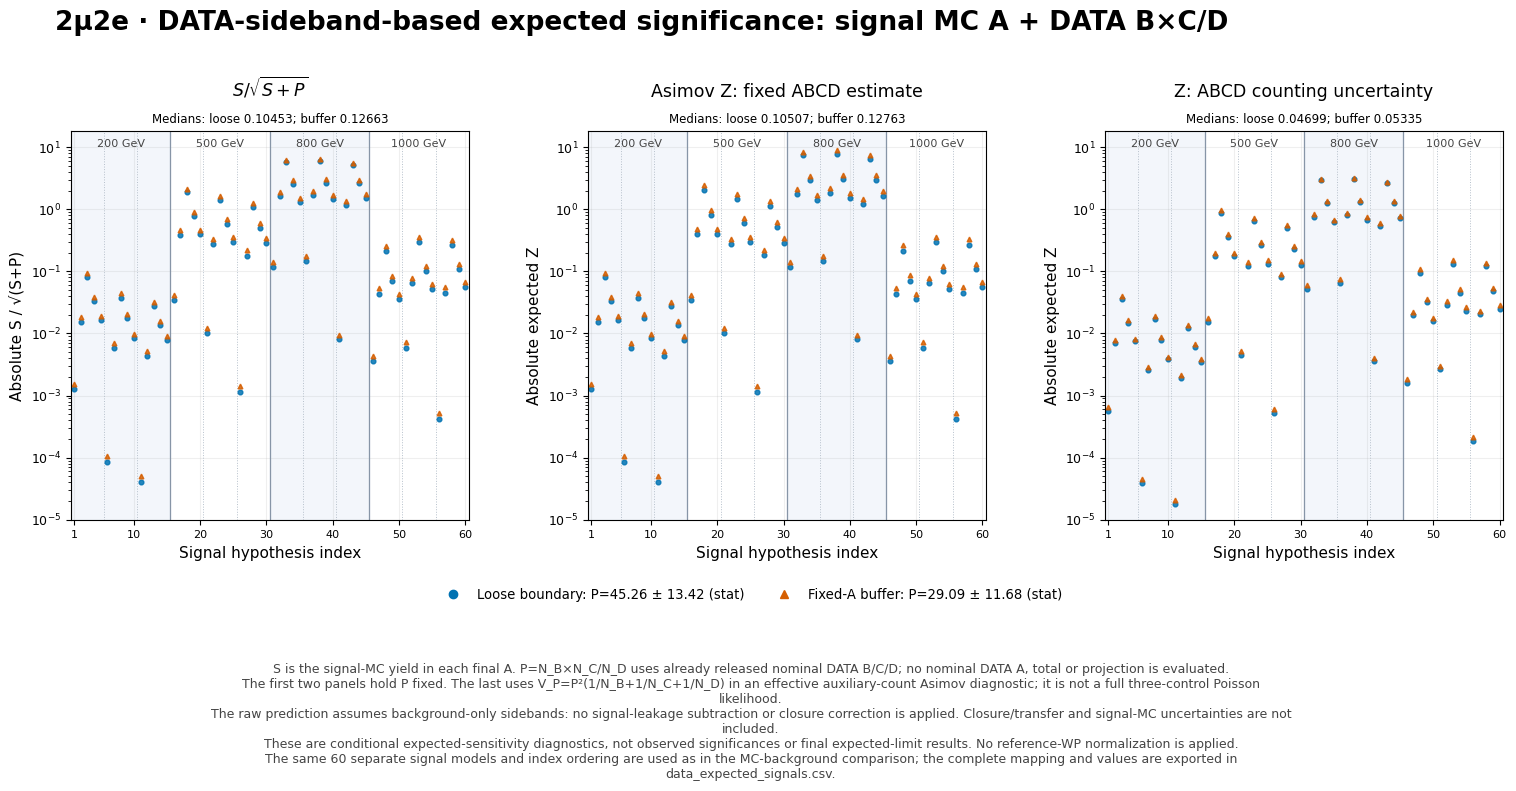

In [56]:
display(figure_lookup['final_data_expected_significance'])

## Current shareable outputs

The full deck follows the notebook order; the short deck retains the decision and the principal validation plots. The manifest lists only the current artifacts. Reference input tables are retained for reproduction; superseded PDFs, images, notebook copies and unused output tables are removed.


In [57]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
presentation_order=['if_nominal_plane','if_approaches','if_tradeoff','if_selection','if_nominal_closure']
for mass in ['low','intermediate','all']:
    presentation_order += ['if_vr_mc_'+mass,'if_vr_data_'+mass]
for mass in ['low','intermediate','all']:
    presentation_order += ['loose_final_1d_'+mass,'loose2d_mc_'+mass,'loose2d_data_'+mass]
presentation_order += ['gap_tradeoff','buffer2d_nominal','gap_nominal_closure','gap_support','gap_selection']
for mass in ['low','intermediate','all']:
    presentation_order += ['gap_vr_mc_'+mass,'gap_vr_data_'+mass]
for mass in ['low','intermediate','all']:
    presentation_order += ['buffer_final_1d_'+mass,'buffer2d_mc_'+mass,'buffer2d_data_'+mass]
presentation_order += ['if_nominal_data_contamination','final_intermediate_overlay','final_significance_comparison','if_meeting_comparison','final_data_expected_significance']
assert len(presentation_order)==len(set(presentation_order))==len(figures)==45
assert set(presentation_order)==set(figure_lookup)
figure_rows=[]
for page,name in enumerate(presentation_order,1):
    figure=figure_lookup[name]
    figure.savefig(OUTPUT_DIR/(name+'.png'),dpi=120,facecolor='white',bbox_inches='tight')
    figure_rows.append(dict(name=name,png=name+'.png',order=page))
decision_names=['if_nominal_plane','if_approaches','if_tradeoff','if_selection',
    'loose_final_1d_intermediate','loose2d_data_intermediate','loose2d_data_all',
    'gap_tradeoff','buffer2d_nominal','gap_selection','buffer_final_1d_intermediate',
    'buffer2d_data_intermediate','buffer2d_data_all','if_nominal_data_contamination','final_intermediate_overlay','final_significance_comparison','if_meeting_comparison','final_data_expected_significance']
tables['figure_manifest']=pd.DataFrame(figure_rows)
tables['figure_definitions']=definitions.set_index('name').loc[presentation_order].reset_index()
tables['decision_figure_manifest']=pd.DataFrame([dict(name=name,png=name+'.png',order=i)
    for i,name in enumerate(decision_names,1)])
tables['gap_scan']=tables['sideband_scan'].query("strategy == 'gap' and b_iso <= 0.5").copy()
tables['gap_regions']=tables['sideband_regions'].loc[tables['sideband_regions'].candidate_id.isin(tables['gap_scan'].candidate_id)].copy()
tables['nominal_controls']=tables['sbd_summary'].loc[tables['sbd_summary'].candidate_id.isin([loose.source_candidate_id,buffer_spec['candidate_id']])].copy()
helpers=['abcd_finalize_plots.py','abcd_finalize_plots.py','abcd_finalize_common.py','abcd_finalize_common.py','abcd_finalize_common.py','abcd_finalize_plots.py','abcd_finalize_common.py','abcd_finalize_plots.py',
    'abcd_finalize_common.py',
    'abcd_finalize_common.py','abcd_finalize_common.py','abcd_finalize_common.py','abcd_finalize_common.py',
    'abcd_finalize_common.py','abcd_finalize_plots.py','abcd_finalize_common.py','abcd_finalize_common.py',
    'abcd_finalize_plots.py','abcd_finalize_common.py','abcd_finalize_common.py']
implementation=pd.DataFrame([common.candidate_input_record(NOTEBOOK_DIR/name,'09 capped-study implementation') for name in helpers])
extra_manifests=[frame for name,frame in tables.items() if name.endswith('_input_manifest') and name not in ['if_input_manifest','vd_input_manifest']]
tables['input_manifest']=pd.concat([tables['if_input_manifest'],tables['vd_input_manifest'],*extra_manifests,implementation,
    pd.DataFrame([common.candidate_input_record(d/'archive_manifest.json','Retained reference inputs') for d in REFERENCE_DIRS])],
    ignore_index=True).drop_duplicates(['path','sha256'])
active_names=[n for n in tables if n.startswith(('if_','vd_','dp_','fgvr_','nominal_final_','final_comparison_','data_expected_'))]+[
    'gap_scan','gap_regions','nominal_controls','validation','input_manifest','figure_manifest','figure_definitions','decision_figure_manifest']
assert len(active_names)==len(set(active_names))
for name in active_names:tables[name].to_csv(OUTPUT_DIR/(name+'.csv'),index=False)
manifest=dict(created_utc=datetime.now(timezone.utc).isoformat(),configuration=CONFIG,methodology=result['metadata'],
    nominal_A_evaluated=False,new_nominal_BCD_evaluated=True,prior_nominal_BCD_reused=True,
    original_data_files_opened={'VR':vr_displays['metadata']['original_data_files_opened'],'nominal':final_nominal['metadata'].get('original_data_files_opened',68)},new_public_2D_masks=21,
    new_independent_2D_observations=20,newly_identifiable_unsafe_audited_targets=0,
    figures=figure_rows,table_rows={n:len(tables[n]) for n in active_names},
    implementation_sha256={Path(r.path).name:r.sha256 for r in implementation.itertuples()},
    newly_executed_checks=len(tables['validation']),reference_inputs=[d.name for d in REFERENCE_DIRS],
    presentation_sequences={'full':presentation_order,'decision':decision_names},MC_optimum=loose.candidate_id,selected_loose=loose.candidate_id,
    selected_buffer=buffer_spec['candidate_id'],historical_A_union_veto=False,final_A_protection=[.25,2.6],final_nominal_background_model_validated=False,final_limits_evaluated=False,
    significance_display='absolute median over 60 matching signal hypotheses',
    data_sideband_expected_significance=True,data_expected_validation_checks=len(tables['data_expected_validation']),closure_display_range=[0,2],closure_visual_band=[.9,1.1],closure_band_is_confidence_interval=False,auxiliary_outputs=['cleanup_manifest.json'],
    final_status='Final two-approach comparison: optimized loose (0.25,2.6) and buffer (0.25,2.0); final likelihood uncertainty remains a statistical-model task')
(OUTPUT_DIR/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2,default=str)+'\n')

report=['2mu2e final boundary comparison','',
    'The historical union of abandoned nominal A definitions has been removed from optimization and control eligibility.',
    'Finalists: loose A=(isolation<0.25, |dphi|>=2.6), versus fixed WP2 A=(isolation<0.20, |dphi|>=2.7) with B/D isolation>=0.25 and C/D |dphi|<2.0.',
    'The loose WP maximizes absolute median known-background MC-A significance among native points with all-120 nominal B/C/D S/B_MC<10%. The same 60 matching hypotheses define the sensitivity median.',
    f'Loose absolute medians: S/sqrt(S+B)={loose.s_sqrt_s_plus_b_median:.5f}, known-background Z={loose.z_known_b_median:.5f}, finite-MC Z={loose.z_mc_stat_diagnostic_median:.5f}.',
    f'Buffer absolute medians: S/sqrt(S+B)={wp2.s_sqrt_s_plus_b_median:.5f}, known-background Z={wp2.z_known_b_median:.5f}, finite-MC Z={wp2.z_mc_stat_diagnostic_median:.5f}.',
    'The pure minimum-gap alternative has B/D isolation>=0.20, but its nominal B overlaps the current loose finalist A. We explicitly chose the 0.25 edge so both actual finalist A regions stay blind during the DATA-control comparison.','']
report+=['The final section compares MC contamination, nominal control counts, and overlaid intermediate VR scans. It also shows absolute per-model significance for both final definitions.','']
report+=summary_lines
report+=['','Loose DATA VR closure:',vr_closure_summary('loose'),'','Buffer DATA VR closure:',vr_closure_summary('gap'),'',
    'Low/intermediate/inclusive VR checks and binwise contamination masks are retained. Partial visible 2D bins are not substituted for integrated regional yields.',
    'The boundary decision can use these two final definitions. MC-A significance is not a complete ABCD expected-limit calculation; the statistical model must include control leakage and supported transfer/closure uncertainties.']

report+=['','DATA-sideband-based expected significance (postdoc follow-up):',
    's=signal MC in A; b_pred=nominal DATA B*C/D. The first Z fixes b_pred; the second uses propagated B/C/D counting variance in an effective auxiliary-count approximation.']
for row in data_expected_summary.itertuples():
    report.append(f'{row.approach}: b_pred={row.background_data_abcd:.5f} +/- {row.background_counting_error:.5f}; median S/sqrt(S+b_pred)={row.s_sqrt_s_plus_p_median:.6f}, fixed-b Z={row.z_data_b_fixed_median:.6f}, counting-uncertainty Z={row.z_data_b_counting_median:.6f}.')
report+=['The two approaches are closer than in the direct-background-MC comparison. These are absolute medians over the same 60 separate models.',
    'Nominal DATA A remains blinded: these are expected diagnostics, not observed significance or a complete joint ABCD likelihood. Raw background-only sideband prediction; no control-signal subtraction, kappa correction, closure/transfer nuisance, or signal-MC uncertainty is included.']

(OUTPUT_DIR/'final_team_proposal.txt').write_text('\n'.join(report)+'\n')
display(Markdown(f'[Full {len(figures)}-figure PNG index]({OUTPUT_DIR.name}/figure_manifest.csv) · '
    f'[{len(decision_names)}-figure meeting index]({OUTPUT_DIR.name}/decision_figure_manifest.csv) · '
    f'[Copyable English report]({OUTPUT_DIR.name}/final_team_proposal.txt)'))


[Full 45-figure PNG index](09_2mu2e_final_check_outputs/figure_manifest.csv) · [18-figure meeting index](09_2mu2e_final_check_outputs/decision_figure_manifest.csv) · [Copyable English report](09_2mu2e_final_check_outputs/final_team_proposal.txt)